
# OBAS V2 — Semana 15
## Auditoría avanzada del modelo final

**Proyecto:** Detección y segmentación de áreas quemadas mediante imágenes satelitales.

**Objetivo:** Evaluar los errores, la robustez y la capacidad de generalización del modelo OBAS V2, considerando su posible utilización en el Tolima.

### Adaptación de la evaluación

OBAS V2 realiza segmentación semántica binaria, por lo que las clases evaluadas a nivel de píxel son:

- **Clase 0:** No quemado.
- **Clase 1:** Quemado.

La auditoría analizará Precision, Recall y F1 por clase, matrices de confusión, curvas Precision-Recall, incertidumbre, estabilidad, robustez, explicabilidad y pruebas regionales.

Se distinguirán los resultados de validación, test espacial y prueba de campo.


In [1]:

# PASO 1 — Verificación del entorno de Kaggle

import os
import sys
import platform
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 60)
print("OBAS V2 | AUDITORÍA SEMANA 15")
print("=" * 60)

print("Python:", sys.version.split()[0])
print("Sistema:", platform.system())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

paquetes = [
    "tensorflow",
    "sklearn",
    "cv2",
    "PIL",
    "scipy",
    "seaborn"
]

print("\nLIBRERÍAS DISPONIBLES:")
for paquete in paquetes:
    disponible = importlib.util.find_spec(paquete) is not None
    print(f"{paquete}: {'OK' if disponible else 'NO INSTALADO'}")

print("\nRUTAS DE KAGGLE:")
print("Input existe:", Path("/kaggle/input").exists())
print("Working existe:", Path("/kaggle/working").exists())

os.makedirs("/kaggle/working/S15_AUDITORIA", exist_ok=True)

print("\nCarpeta de auditoría preparada.")


OBAS V2 | AUDITORÍA SEMANA 15
Python: 3.13.18
Sistema: Linux
NumPy: 2.1.3
Pandas: 2.3.3

LIBRERÍAS DISPONIBLES:
tensorflow: OK
sklearn: OK
cv2: OK
PIL: OK
scipy: OK
seaborn: OK

RUTAS DE KAGGLE:
Input existe: True
Working existe: True

Carpeta de auditoría preparada.


revisar todos los datasets y modelos disponibles

In [2]:

# PASO 2 — Inventario de archivos disponibles

from pathlib import Path
import pandas as pd

raiz = Path("/kaggle/input")

registros = []

if raiz.exists():
    for archivo in raiz.rglob("*"):
        if archivo.is_file():
            registros.append({
                "Dataset": archivo.relative_to(raiz).parts[0],
                "Archivo": archivo.name,
                "Extensión": archivo.suffix.lower(),
                "Tamaño_MB": round(
                    archivo.stat().st_size / (1024 ** 2), 3
                ),
                "Ruta": str(archivo)
            })

df_archivos = pd.DataFrame(registros)

print("TOTAL DE ARCHIVOS:", len(df_archivos))

if not df_archivos.empty:
    print("\nARCHIVOS POR DATASET:")
    print(
        df_archivos.groupby("Dataset")
        .size()
        .sort_values(ascending=False)
        .to_string()
    )

    print("\nARCHIVOS POR EXTENSIÓN:")
    print(
        df_archivos["Extensión"]
        .value_counts()
        .to_string()
    )

    print("\nPOSIBLES MODELOS Y DATOS IMPORTANTES:")

    patron = (
        r"teacher|student|baseline|best|"
        r"model|checkpoint|mask|test|"
        r"\.h5$|\.keras$|\.tflite$|\.npy$|\.npz$"
    )

    importantes = df_archivos[
        df_archivos["Archivo"].str.contains(
            patron, case=False, regex=True, na=False
        )
    ]

    print(
        importantes[
            ["Dataset", "Archivo", "Tamaño_MB", "Ruta"]
        ].head(100).to_string(index=False)
    )

    df_archivos.to_csv(
        "/kaggle/working/S15_AUDITORIA/inventario_archivos.csv",
        index=False
    )

else:
    print("No se encontraron archivos en /kaggle/input.")
    print("Debes agregar los datasets desde Add Input.")


TOTAL DE ARCHIVOS: 20691

ARCHIVOS POR DATASET:
Dataset
datasets    20691

ARCHIVOS POR EXTENSIÓN:
Extensión
.npy       20460
.png          99
.csv          76
.json         18
.tif          18
.keras        10
.tflite        5
.txt           3
.md            1
.h5            1

POSIBLES MODELOS Y DATOS IMPORTANTES:
 Dataset                                         Archivo  Tamaño_MB                                                                                                                                                                                                                     Ruta
datasets                           A_Dropout_mejor.keras     92.595                                                                                                                                 /kaggle/input/datasets/santiagofallaamaya/entrega-completa-obas-v2/A_Dropout_mejor.keras
datasets                        B_Dropout_L2_mejor.keras     92.596                                             

comprobar la forma de las imágenes y máscaras

In [3]:

# PASO 3 — Inspección de archivos NumPy

import numpy as np
from pathlib import Path

archivos_numpy = [
    Path(ruta)
    for ruta in df_archivos["Ruta"]
    if Path(ruta).suffix.lower() in [".npy", ".npz"]
] if not df_archivos.empty else []

print("Archivos NumPy encontrados:", len(archivos_numpy))

for ruta in archivos_numpy[:15]:
    print("\nArchivo:", ruta.name)

    try:
        datos = np.load(ruta, allow_pickle=False)

        if isinstance(datos, np.lib.npyio.NpzFile):
            print("Claves:", datos.files)
            datos.close()
        else:
            print("Forma:", datos.shape)
            print("Tipo:", datos.dtype)

            if np.issubdtype(datos.dtype, np.number):
                print("Mínimo:", np.min(datos))
                print("Máximo:", np.max(datos))

    except Exception as error:
        print("No se pudo inspeccionar:", str(error))


Archivos NumPy encontrados: 20460

Archivo: prueba_01_OBAS_zone1_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 1

Archivo: prueba_02_OBAS_zone1_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 0

Archivo: prueba_03_OBAS_zone2_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 0

Archivo: prueba_04_OBAS_zone3_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 0

Archivo: prueba_05_OBAS_zone1_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 0

Archivo: prueba_06_OBAS_zone1_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 1

Archivo: prueba_07_OBAS_zone3_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 0

Archivo: prueba_08_OBAS_zone3_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 1

Archivo: prueba_09_OBAS_zone1_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 1

Archivo: prueba_10_OBAS_zone1_prediccion.npy
Forma: (128, 128)
Tipo: uint8
Mínimo: 0
Máximo: 1

Archi

verificar qué modelos tenemos realmente

In [4]:

# PASO 4 — Localizar archivos de modelos

extensiones_modelo = {
    ".keras", ".h5", ".hdf5",
    ".tflite", ".onnx", ".pt", ".pth"
}

modelos = df_archivos[
    df_archivos["Extensión"].isin(extensiones_modelo)
].copy() if not df_archivos.empty else pd.DataFrame()

if modelos.empty:
    print("No se encontraron archivos de modelos con extensiones conocidas.")
    print("Revisar checkpoints, SavedModel y datasets pendientes.")
else:
    print(
        modelos[
            ["Dataset", "Archivo", "Tamaño_MB", "Ruta"]
        ].to_string(index=False)
    )

print("\nDirectorios que podrían contener SavedModel:")

if raiz.exists():
    for archivo in raiz.rglob("saved_model.pb"):
        print(archivo.parent)


 Dataset                                                    Archivo  Tamaño_MB                                                                                                                                                                                        Ruta
datasets                                      A_Dropout_mejor.keras     92.595                                                                                                    /kaggle/input/datasets/santiagofallaamaya/entrega-completa-obas-v2/A_Dropout_mejor.keras
datasets                                   B_Dropout_L2_mejor.keras     92.596                                                                                                 /kaggle/input/datasets/santiagofallaamaya/entrega-completa-obas-v2/B_Dropout_L2_mejor.keras
datasets                                   C_Dropout_L1_mejor.keras     92.596                                                                                                 /kaggle/input/datasets/s


## Paso 5. Verificación de los datos y modelos finales

En esta etapa se comprueba la correspondencia entre las imágenes satelitales, las máscaras reales y las predicciones existentes.

También se identifican los modelos Teacher, Student y Student KD para determinar cuál será utilizado en la auditoría avanzada y cuál corresponde a la aplicación Android.


In [5]:

# PASO 5 — Verificación de imágenes, máscaras y predicciones

import numpy as np
from pathlib import Path

BASE = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-respaldo-continuidad-aplicacion-movil/"
    "OBAS_V2_PAQUETE_FLUTTER_FINAL/"
    "OBAS_V2_PAQUETE_FLUTTER_FINAL"
)

RUTA_IMAGENES = BASE / "datos/parches"
RUTA_MASCARAS = BASE / "datos/mascaras_reales"
RUTA_PREDICCIONES = BASE / "resultados/mascaras_predichas"

imagenes = sorted(RUTA_IMAGENES.glob("*_imagen.npy"))
mascaras = sorted(RUTA_MASCARAS.glob("*_mascara_real.npy"))
predicciones = sorted(RUTA_PREDICCIONES.glob("*_prediccion.npy"))

print("=== ARCHIVOS DE PRUEBA ===")
print("Imágenes:", len(imagenes))
print("Máscaras reales:", len(mascaras))
print("Predicciones:", len(predicciones))

# Verificar correspondencia mediante el identificador
ids_imagenes = {
    p.name.replace("_imagen.npy", "") for p in imagenes
}
ids_mascaras = {
    p.name.replace("_mascara_real.npy", "") for p in mascaras
}
ids_predicciones = {
    p.name.replace("_prediccion.npy", "") for p in predicciones
}

ids_comunes = sorted(
    ids_imagenes & ids_mascaras & ids_predicciones
)

print("\nConjuntos completos:", len(ids_comunes))

if ids_comunes:
    identificador = ids_comunes[0]

    imagen = np.load(
        RUTA_IMAGENES / f"{identificador}_imagen.npy"
    )
    mascara = np.load(
        RUTA_MASCARAS / f"{identificador}_mascara_real.npy"
    )
    prediccion = np.load(
        RUTA_PREDICCIONES / f"{identificador}_prediccion.npy"
    )

    print("\n=== PRIMER EJEMPLO ===")
    print("ID:", identificador)
    print("Imagen:", imagen.shape, imagen.dtype)
    print("Máscara:", mascara.shape, mascara.dtype)
    print("Predicción:", prediccion.shape, prediccion.dtype)

    print("\nRango imagen:",
          float(np.min(imagen)),
          float(np.max(imagen)))

    print("Valores máscara:",
          np.unique(mascara))

    print("Valores predicción:",
          np.unique(prediccion))

    print("\nPíxeles quemados reales:",
          int(np.sum(mascara == 1)))

    print("Píxeles quemados predichos:",
          int(np.sum(prediccion == 1)))

else:
    print("No se encontraron conjuntos completos.")
    print("Revisar rutas y nombres de archivos.")


=== ARCHIVOS DE PRUEBA ===
Imágenes: 20
Máscaras reales: 20
Predicciones: 20

Conjuntos completos: 20

=== PRIMER EJEMPLO ===
ID: prueba_01_OBAS_zone1
Imagen: (3, 128, 128) float32
Máscara: (128, 128) uint8
Predicción: (128, 128) uint8

Rango imagen: 0.0 0.9642857313156128
Valores máscara: [0 1]
Valores predicción: [0 1]

Píxeles quemados reales: 1601
Píxeles quemados predichos: 1609


Paso 6: visualizar una imagen, su máscara y la predicción

Imagen original: (3, 128, 128)
Máscara real: (128, 128)
Predicción: (128, 128)


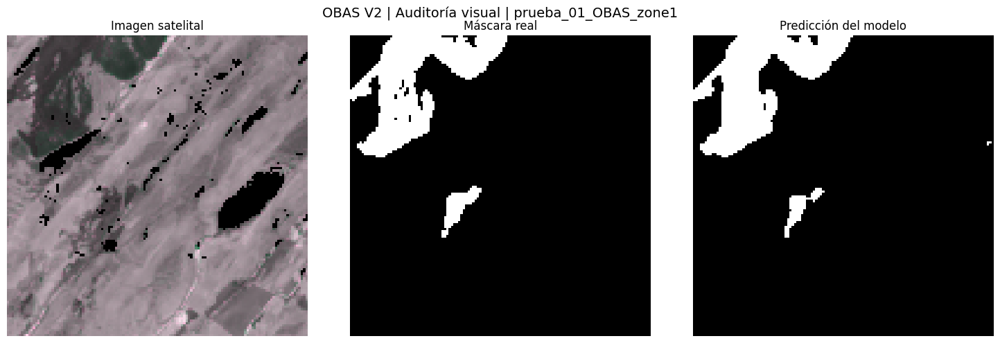

In [7]:

# PASO 6 — Visualización corregida de OBAS V2

import numpy as np
import matplotlib.pyplot as plt

if ids_comunes:

    # Seleccionar el primer conjunto completo
    identificador = ids_comunes[0]

    imagen = np.load(
        RUTA_IMAGENES / f"{identificador}_imagen.npy"
    )

    mascara = np.load(
        RUTA_MASCARAS / f"{identificador}_mascara_real.npy"
    )

    prediccion = np.load(
        RUTA_PREDICCIONES / f"{identificador}_prediccion.npy"
    )

    print("Imagen original:", imagen.shape)
    print("Máscara real:", mascara.shape)
    print("Predicción:", prediccion.shape)

    # Convertir de (3, 128, 128) a (128, 128, 3)
    if imagen.ndim == 3 and imagen.shape[0] == 3:
        imagen = np.transpose(imagen, (1, 2, 0))

    # Preparar imagen para visualización
    imagen_visual = imagen.astype(np.float32)

    minimo = np.min(imagen_visual)
    maximo = np.max(imagen_visual)

    if maximo > minimo:
        imagen_visual = (
            imagen_visual - minimo
        ) / (maximo - minimo)

    # Preparar máscaras
    mascara_visual = np.squeeze(mascara)
    prediccion_visual = np.squeeze(prediccion)

    # Crear gráficos
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(imagen_visual)
    axes[0].set_title("Imagen satelital")

    axes[1].imshow(
        mascara_visual,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Máscara real")

    axes[2].imshow(
        prediccion_visual,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Predicción del modelo")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"OBAS V2 | Auditoría visual | {identificador}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

else:
    print("No se encontraron conjuntos completos.")



## Paso 7. Evaluación cuantitativa de la segmentación

Se comparan las máscaras reales con las predicciones del modelo para calcular Precision, Recall, F1-score y la matriz de confusión.

OBAS V2 realiza segmentación binaria por píxel:
- Clase 0: No quemado.
- Clase 1: Quemado.

Parches evaluados: 20
Píxeles evaluados: 327680

REPORTE DE CLASIFICACIÓN POR PÍXEL
              precision    recall  f1-score   support

  No quemado     0.9578    0.9806    0.9691    286003
     Quemado     0.8410    0.7034    0.7661     41677

    accuracy                         0.9454    327680
   macro avg     0.8994    0.8420    0.8676    327680
weighted avg     0.9429    0.9454    0.9433    327680


MÉTRICAS DE ÁREA QUEMADA
Precision: 0.8410
Recall:    0.7034
F1-score:  0.7661

MATRIZ DE CONFUSIÓN
TN: 280462
FP: 5541
FN: 12362
TP: 29315


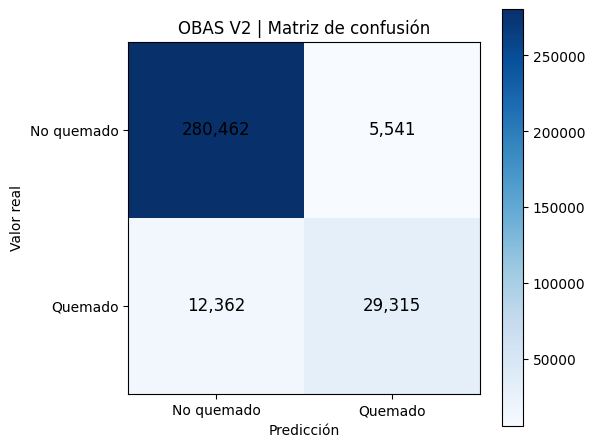

In [8]:

# PASO 7 — Métricas de segmentación binaria

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Acumular valores reales y predichos
valores_reales = []
valores_predichos = []

for identificador in ids_comunes:

    mascara = np.load(
        RUTA_MASCARAS / f"{identificador}_mascara_real.npy"
    )

    prediccion = np.load(
        RUTA_PREDICCIONES / f"{identificador}_prediccion.npy"
    )

    mascara = np.asarray(mascara).ravel()
    prediccion = np.asarray(prediccion).ravel()

    if mascara.shape != prediccion.shape:
        print("Dimensiones diferentes:", identificador)
        continue

    # Verificar que ambas sean binarias
    if not (
        np.isin(mascara, [0, 1]).all()
        and np.isin(prediccion, [0, 1]).all()
    ):
        print("Valores no binarios:", identificador)
        continue

    valores_reales.append(mascara.astype(np.uint8))
    valores_predichos.append(prediccion.astype(np.uint8))

if not valores_reales:
    raise ValueError("No se encontraron pares válidos.")

y_real = np.concatenate(valores_reales)
y_pred = np.concatenate(valores_predichos)

print("Parches evaluados:", len(valores_reales))
print("Píxeles evaluados:", len(y_real))

# Reporte por clase
print("\nREPORTE DE CLASIFICACIÓN POR PÍXEL")

print(
    classification_report(
        y_real,
        y_pred,
        labels=[0, 1],
        target_names=["No quemado", "Quemado"],
        digits=4,
        zero_division=0
    )
)

# Métricas de la clase quemada
precision = precision_score(
    y_real, y_pred, pos_label=1, zero_division=0
)

recall = recall_score(
    y_real, y_pred, pos_label=1, zero_division=0
)

f1 = f1_score(
    y_real, y_pred, pos_label=1, zero_division=0
)

print("\nMÉTRICAS DE ÁREA QUEMADA")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# Matriz de confusión
matriz = confusion_matrix(
    y_real, y_pred, labels=[0, 1]
)

tn, fp, fn, tp = matriz.ravel()

print("\nMATRIZ DE CONFUSIÓN")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(matriz, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["No quemado", "Quemado"])
ax.set_yticklabels(["No quemado", "Quemado"])

ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
ax.set_title("OBAS V2 | Matriz de confusión")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i,
            f"{matriz[i, j]:,}",
            ha="center",
            va="center",
            fontsize=12
        )

plt.colorbar(imagen, ax=ax)
plt.tight_layout()
plt.show()


## Paso 8. Verificación de probabilidades y umbral de confianza

Se identifican los archivos que contienen probabilidades de
predicción para construir curvas Precision-Recall y analizar
el umbral de decisión del modelo.

In [11]:

# PASO 8 — Buscar probabilidades del modelo

from pathlib import Path
import numpy as np

archivos_probabilidad = []

for carpeta in Path("/kaggle/input").rglob("*"):
    if carpeta.is_file() and carpeta.suffix.lower() in [".npy", ".npz"]:
        nombre = carpeta.name.lower()

        if any(
            palabra in nombre
            for palabra in [
                "probabilidad",
                "probabilidades",
                "prob",
                "prediction_prob",
                "pred_proba"
            ]
        ):
            archivos_probabilidad.append(carpeta)

print("Archivos candidatos encontrados:", len(archivos_probabilidad))

for archivo in archivos_probabilidad[:20]:
    print("\nArchivo:", archivo.name)
    print("Ruta:", archivo)

    try:
        datos = np.load(archivo, allow_pickle=False)

        if isinstance(datos, np.ndarray):
            print("Forma:", datos.shape)
            print("Tipo:", datos.dtype)
            print("Mínimo:", np.min(datos))
            print("Máximo:", np.max(datos))
        else:
            print("Contenido NPZ:", datos.files)
            datos.close()

    except Exception as error:
        print("No se pudo inspeccionar:", error)


Archivos candidatos encontrados: 0


In [10]:

# PASO 8.1 — Verificar modelos y datos disponibles

from pathlib import Path
import numpy as np

raiz = Path("/kaggle/input")

# 1. Buscar modelos disponibles
extensiones = {".keras", ".tflite", ".h5"}

modelos = [
    archivo
    for archivo in raiz.rglob("*")
    if archivo.is_file()
    and archivo.suffix.lower() in extensiones
]

print("=== MODELOS DISPONIBLES ===")

for i, modelo in enumerate(modelos, start=1):
    print(f"\n{i}. {modelo.name}")
    print("Ruta:", modelo)
    print(
        "Tamaño:",
        round(modelo.stat().st_size / (1024**2), 2),
        "MB"
    )

# 2. Revisar la imagen que ya visualizamos
print("\n=== IMAGEN DE PRUEBA ===")

identificador = ids_comunes[0]

imagen = np.load(
    RUTA_IMAGENES / f"{identificador}_imagen.npy"
)

print("Identificador:", identificador)
print("Forma:", imagen.shape)
print("Tipo:", imagen.dtype)
print("Mínimo:", np.min(imagen))
print("Máximo:", np.max(imagen))
print("Promedio:", np.mean(imagen))

# 3. Verificar la máscara
mascara = np.load(
    RUTA_MASCARAS / f"{identificador}_mascara_real.npy"
)

print("\n=== MÁSCARA REAL ===")
print("Forma:", mascara.shape)
print("Valores:", np.unique(mascara))


=== MODELOS DISPONIBLES ===

1. A_Dropout_mejor.keras
Ruta: /kaggle/input/datasets/santiagofallaamaya/entrega-completa-obas-v2/A_Dropout_mejor.keras
Tamaño: 92.59 MB

2. B_Dropout_L2_mejor.keras
Ruta: /kaggle/input/datasets/santiagofallaamaya/entrega-completa-obas-v2/B_Dropout_L2_mejor.keras
Tamaño: 92.6 MB

3. C_Dropout_L1_mejor.keras
Ruta: /kaggle/input/datasets/santiagofallaamaya/entrega-completa-obas-v2/C_Dropout_L1_mejor.keras
Tamaño: 92.6 MB

4. obas_v2_student_float16.tflite
Ruta: /kaggle/input/datasets/santiagofallaamaya/obas-v2-progreso-respaldo/obas_v2_student_float16.tflite
Tamaño: 15.31 MB

5. student_baseline_float16.tflite
Ruta: /kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/modelos/student_baseline_float16.tflite
Tamaño: 15.31 MB

6. student_baseline_float32.tflite
Ruta: /kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUET

## Paso 8.2. Verificación del modelo Student

Se carga el modelo Student MobileNetV2–U-Net entrenado para
verificar sus dimensiones de entrada y salida antes de
realizar inferencias y calcular las curvas Precision-Recall.

In [13]:

# PASO 8.2 — Cargar y verificar el modelo Student

import tensorflow as tf
from pathlib import Path

RUTA_MODELO = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-final-backup/models/"
    "Student_MobileNetV2_UNet_V2_baseline_best.keras"
)

print("TensorFlow:", tf.__version__)
print("Modelo encontrado:", RUTA_MODELO.exists())

if not RUTA_MODELO.exists():
    raise FileNotFoundError(
        f"No se encontró el modelo: {RUTA_MODELO}"
    )

# No necesitamos compilar para realizar predicciones
modelo_student = tf.keras.models.load_model(
    str(RUTA_MODELO),
    compile=False
)

print("\nMODELO CARGADO CORRECTAMENTE")
print("Nombre:", modelo_student.name)
print("Entrada:", modelo_student.input_shape)
print("Salida:", modelo_student.output_shape)
print("Parámetros:", modelo_student.count_params())


TensorFlow: 2.21.0
Modelo encontrado: True

MODELO CARGADO CORRECTAMENTE
Nombre: Student_MobileNetV2_UNet_V2
Entrada: (None, 128, 128, 3)
Salida: (None, 128, 128, 1)
Parámetros: 8045857


## Paso 8.3. Obtención de probabilidades de segmentación

Se ejecuta el modelo Student sobre los 20 parches disponibles para obtener las probabilidades de área quemada por píxel, antes de aplicar el umbral de clasificación.

Estas probabilidades permitirán construir la curva Precision-Recall y evaluar diferentes umbrales de decisión.

Parches procesados: 20
Píxeles evaluados: 327680
Probabilidad mínima: 1.7185534e-26
Probabilidad máxima: 1.0
Probabilidad promedio: 0.10594551


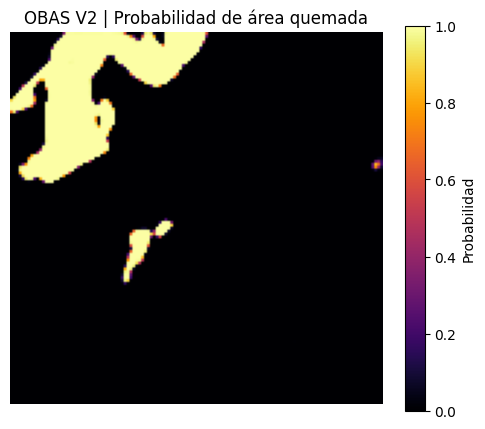

In [14]:

# PASO 8.3 — Obtener probabilidades del Student

import numpy as np
import matplotlib.pyplot as plt

probabilidades_student = []
mascaras_student = []

for identificador in ids_comunes:

    imagen = np.load(
        RUTA_IMAGENES / f"{identificador}_imagen.npy"
    ).astype(np.float32)

    mascara = np.load(
        RUTA_MASCARAS / f"{identificador}_mascara_real.npy"
    )

    # Convertir canales: (3,128,128) -> (128,128,3)
    if imagen.shape == (3, 128, 128):
        imagen = np.transpose(imagen, (1, 2, 0))

    if imagen.shape != (128, 128, 3):
        raise ValueError(
            f"Forma inesperada: {identificador}, {imagen.shape}"
        )

    # Los datos ya están en escala cercana a 0-1.
    # No normalizar nuevamente sin verificar
    # el preprocesamiento original del entrenamiento.

    entrada = np.expand_dims(imagen, axis=0)

    # Predicción del modelo
    salida = modelo_student.predict(
        entrada,
        verbose=0
    )

    salida = np.squeeze(salida)

    if salida.shape != (128, 128):
        raise ValueError(
            f"Salida inesperada: {salida.shape}"
        )

    if not np.isfinite(salida).all():
        raise ValueError(
            f"Valores no finitos: {identificador}"
        )

    if salida.min() < 0 or salida.max() > 1:
        raise ValueError(
            "La salida no está entre 0 y 1. "
            "Debemos comprobar si son logits."
        )

    probabilidades_student.append(
        salida.astype(np.float32).ravel()
    )

    mascaras_student.append(
        mascara.astype(np.uint8).ravel()
    )

y_prob = np.concatenate(probabilidades_student)
y_real_prob = np.concatenate(mascaras_student)

print("Parches procesados:", len(ids_comunes))
print("Píxeles evaluados:", len(y_prob))
print("Probabilidad mínima:", y_prob.min())
print("Probabilidad máxima:", y_prob.max())
print("Probabilidad promedio:", y_prob.mean())

# Visualizar probabilidades del primer parche
primera_probabilidad = probabilidades_student[0].reshape(
    128, 128
)

plt.figure(figsize=(6, 5))
plt.imshow(
    primera_probabilidad,
    cmap="inferno",
    vmin=0,
    vmax=1
)
plt.title("OBAS V2 | Probabilidad de área quemada")
plt.colorbar(label="Probabilidad")
plt.axis("off")
plt.show()


## Paso 8.4. Comparación visual de diferentes parches

Se comparan imágenes satelitales, máscaras reales y predicciones del modelo Student para identificar aciertos y posibles errores de segmentación.

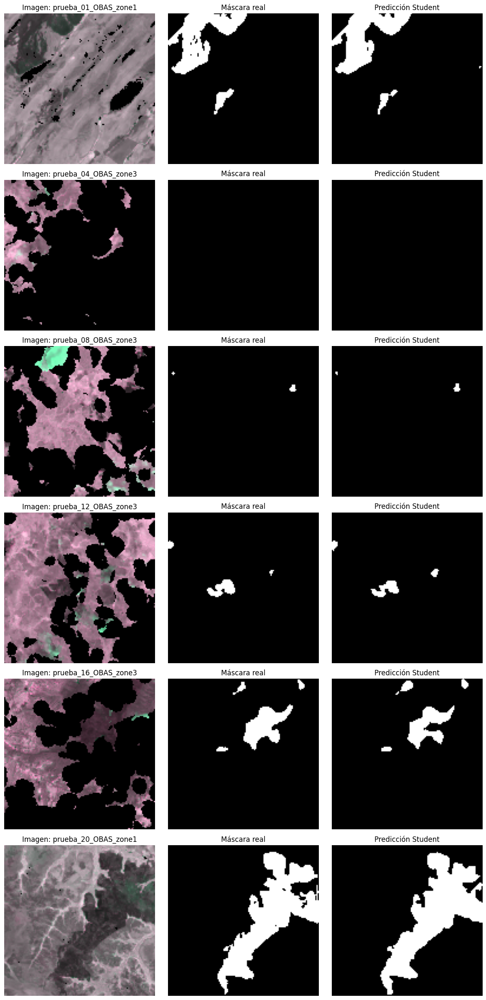

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# Seleccionar hasta 6 parches distribuidos en el conjunto
indices = np.linspace(
    0, len(ids_comunes) - 1,
    min(6, len(ids_comunes)),
    dtype=int
)

fig, axes = plt.subplots(
    len(indices), 3,
    figsize=(12, 4 * len(indices))
)

axes = np.atleast_2d(axes)

for fila, indice in enumerate(indices):

    identificador = ids_comunes[indice]

    imagen = np.load(
        RUTA_IMAGENES / f"{identificador}_imagen.npy"
    ).astype(np.float32)

    mascara_real = np.load(
        RUTA_MASCARAS / f"{identificador}_mascara_real.npy"
    )

    if imagen.shape == (3, 128, 128):
        imagen = np.transpose(imagen, (1, 2, 0))

    # Visualización de la imagen
    minimo = imagen.min()
    maximo = imagen.max()

    imagen_visual = (
        (imagen - minimo) / (maximo - minimo)
        if maximo > minimo
        else np.zeros_like(imagen)
    )

    probabilidad = probabilidades_student[indice].reshape(
        128, 128
    )

    prediccion = (probabilidad >= 0.5).astype(np.uint8)

    axes[fila, 0].imshow(imagen_visual)
    axes[fila, 0].set_title(
        f"Imagen: {identificador}"
    )

    axes[fila, 1].imshow(
        mascara_real,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[fila, 1].set_title("Máscara real")

    axes[fila, 2].imshow(
        prediccion,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[fila, 2].set_title("Predicción Student")

    for columna in range(3):
        axes[fila, columna].axis("off")

plt.tight_layout()
plt.show()


## Paso 8.5. Identificación de aciertos y errores

Se calcula el F1-score de cada parche para identificar los casos con mejor y peor desempeño del modelo Student.

In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

resultados_parches = []

for i, identificador in enumerate(ids_comunes):

    mascara = np.load(
        RUTA_MASCARAS / f"{identificador}_mascara_real.npy"
    ).astype(np.uint8).ravel()

    probabilidad = np.asarray(
        probabilidades_student[i]
    ).reshape(-1)

    prediccion = (probabilidad >= 0.5).astype(np.uint8)

    resultados_parches.append({
        "Parche": identificador,
        "Precision": precision_score(
            mascara, prediccion, zero_division=0
        ),
        "Recall": recall_score(
            mascara, prediccion, zero_division=0
        ),
        "F1-score": f1_score(
            mascara, prediccion, zero_division=0
        ),
        "Pixeles_reales_quemados": int(mascara.sum()),
        "Pixeles_predichos_quemados": int(prediccion.sum()),
        "FP": int(((mascara == 0) & (prediccion == 1)).sum()),
        "FN": int(((mascara == 1) & (prediccion == 0)).sum())
    })

df_resultados = pd.DataFrame(resultados_parches)

# Para ordenar correctamente los parches sin áreas quemadas,
# se utiliza también la coincidencia de píxeles.
df_resultados["Coincidencia"] = (
    1 - (df_resultados["FP"] + df_resultados["FN"]) / 16384
)

print("=== 5 PARCHES CON MEJOR COINCIDENCIA ===")
display(
    df_resultados.sort_values(
        "Coincidencia", ascending=False
    ).head(5)
)

print("\n=== 5 PARCHES CON PEOR COINCIDENCIA ===")
display(
    df_resultados.sort_values(
        "Coincidencia", ascending=True
    ).head(5)
)

=== 5 PARCHES CON MEJOR COINCIDENCIA ===


,Parche,Precision,Recall,F1-score,Pixeles_reales_quemados,Pixeles_predichos_quemados,FP,FN,Coincidencia
1,prueba_02_OBAS_zone1,0.0,0.0,0.0,0,0,0,0,1.000000
2,prueba_03_OBAS_zone2,0.0,0.0,0.0,0,0,0,0,1.000000
3,prueba_04_OBAS_zone3,0.0,0.0,0.0,0,0,0,0,1.000000
4,prueba_05_OBAS_zone1,0.0,0.0,0.0,3,0,0,3,0.999817
6,prueba_07_OBAS_zone3,0.0,0.0,0.0,5,0,0,5,0.999695



=== 5 PARCHES CON PEOR COINCIDENCIA ===


,Parche,Precision,Recall,F1-score,Pixeles_reales_quemados,Pixeles_predichos_quemados,FP,FN,Coincidencia
16,prueba_17_CEMS_AOI01_01,0.000000,0.000000,0.000000,10317,0,0,10317,0.370300
17,prueba_18_CEMS_AOI01_01,0.563593,0.810225,0.664771,5770,8295,3620,1095,0.712219
18,prueba_19_CEMS_AOI01_01,0.948818,0.999869,0.973675,15259,16080,823,2,0.949646
13,prueba_14_OBAS_zone1,0.871512,0.805639,0.837282,1667,1541,198,324,0.968140
19,prueba_20_OBAS_zone1,0.911822,0.966107,0.938180,3393,3595,317,115,0.973633


## Paso 8.6. Selección de casos para explicabilidad

Se identifican los parches con presencia real de áreas quemadas y
se ordenan según su F1-score para seleccionar casos de buen y mal
desempeño que posteriormente serán analizados mediante Grad-CAM.

In [17]:
import pandas as pd

# Trabajar con los resultados del paso 8.5
df_auditoria = df_resultados.copy()

# Separar parches con y sin áreas quemadas reales
df_con_quema = df_auditoria[
    df_auditoria["Pixeles_reales_quemados"] > 0
].copy()

df_sin_quema = df_auditoria[
    df_auditoria["Pixeles_reales_quemados"] == 0
].copy()

# Ordenar por F1 de la clase quemada
df_ordenado = df_con_quema.sort_values(
    by=["F1-score", "Recall"],
    ascending=[False, False]
)

print("=== RESUMEN DEL CONJUNTO ===")
print("Total de parches:", len(df_auditoria))
print("Parches con quema real:", len(df_con_quema))
print("Parches sin quema real:", len(df_sin_quema))

print("\n=== MEJORES CASOS CON QUEMA ===")
display(
    df_ordenado[
        ["Parche", "Precision", "Recall",
         "F1-score", "FP", "FN"]
    ].head(10)
)

print("\n=== PEORES CASOS CON QUEMA ===")
display(
    df_ordenado[
        ["Parche", "Precision", "Recall",
         "F1-score", "FP", "FN"]
    ].tail(10).sort_values("F1-score")
)

print("\n=== CASOS SIN QUEMA REAL ===")
display(
    df_sin_quema[
        ["Parche", "Pixeles_predichos_quemados",
         "FP", "Coincidencia"]
    ]
)

=== RESUMEN DEL CONJUNTO ===
Total de parches: 20
Parches con quema real: 17
Parches sin quema real: 3

=== MEJORES CASOS CON QUEMA ===


,Parche,Precision,Recall,F1-score,FP,FN
18,prueba_19_CEMS_AOI01_01,0.948818,0.999869,0.973675,823,2
14,prueba_15_OBAS_zone1,0.978088,0.965585,0.971796,22,35
0,prueba_01_OBAS_zone1,0.955252,0.960025,0.957632,72,64
19,prueba_20_OBAS_zone1,0.911822,0.966107,0.938180,317,115
15,prueba_16_OBAS_zone3,0.937811,0.866667,0.900836,50,116
8,prueba_09_OBAS_zone1,0.927273,0.869318,0.897361,12,23
7,prueba_08_OBAS_zone3,0.848485,0.933333,0.888889,5,2
11,prueba_12_OBAS_zone3,0.882845,0.882845,0.882845,28,28
12,prueba_13_OBAS_zone1,0.794562,0.923888,0.854358,204,65
13,prueba_14_OBAS_zone1,0.871512,0.805639,0.837282,198,324



=== PEORES CASOS CON QUEMA ===


,Parche,Precision,Recall,F1-score,FP,FN
4,prueba_05_OBAS_zone1,0.000000,0.000000,0.000000,0,3
6,prueba_07_OBAS_zone3,0.000000,0.000000,0.000000,0,5
16,prueba_17_CEMS_AOI01_01,0.000000,0.000000,0.000000,0,10317
5,prueba_06_OBAS_zone1,0.223022,0.953846,0.361516,216,3
17,prueba_18_CEMS_AOI01_01,0.563593,0.810225,0.664771,3620,1095
9,prueba_10_OBAS_zone1,1.000000,0.532663,0.695082,0,93
10,prueba_11_OBAS_zone1,0.965753,0.665094,0.787709,5,71
13,prueba_14_OBAS_zone1,0.871512,0.805639,0.837282,198,324
12,prueba_13_OBAS_zone1,0.794562,0.923888,0.854358,204,65
11,prueba_12_OBAS_zone3,0.882845,0.882845,0.882845,28,28



=== CASOS SIN QUEMA REAL ===


,Parche,Pixeles_predichos_quemados,FP,Coincidencia
1,prueba_02_OBAS_zone1,0,0,1.0
2,prueba_03_OBAS_zone2,0,0,1.0
3,prueba_04_OBAS_zone3,0,0,1.0


## Paso 8.7. Selección de casos para Grad-CAM

Se seleccionan 10 parches con mejor desempeño y 10 casos
de contraste, incluyendo errores de omisión, falsas alarmas
y ejemplos sin áreas quemadas.

La selección permitirá analizar visualmente qué regiones
influyen en las predicciones del modelo Student.

In [18]:
import pandas as pd

# Copiar los resultados anteriores
df_seleccion = df_resultados.copy()

# Separar imágenes con y sin quema
con_quema = df_seleccion[
    df_seleccion["Pixeles_reales_quemados"] > 0
].copy()

# Ordenar por F1-score de mayor a menor
con_quema = con_quema.sort_values(
    by=["F1-score", "Recall"],
    ascending=[False, False]
)

# Seleccionar los 10 mejores con quema
mejores_10 = con_quema.head(10).copy()

# Los demás parches serán casos de contraste
restantes_10 = df_seleccion[
    ~df_seleccion["Parche"].isin(mejores_10["Parche"])
].copy()

# Ordenar casos de contraste por F1
restantes_10 = restantes_10.sort_values(
    by=["F1-score", "FN"],
    ascending=[True, False]
)

# Guardar identificadores para los próximos pasos
ids_mejores = mejores_10["Parche"].tolist()
ids_errores = restantes_10["Parche"].tolist()

print("=== 10 CASOS CON MEJOR DESEMPEÑO ===")
display(
    mejores_10[
        ["Parche", "F1-score", "Recall", "FP", "FN"]
    ]
)

print("\n=== 10 CASOS DE CONTRASTE ===")
display(
    restantes_10[
        ["Parche", "F1-score", "Recall", "FP", "FN"]
    ]
)

print("\nTotal seleccionados:",
      len(ids_mejores) + len(ids_errores))

print("Identificadores únicos:",
      len(set(ids_mejores + ids_errores)))

=== 10 CASOS CON MEJOR DESEMPEÑO ===


,Parche,F1-score,Recall,FP,FN
18,prueba_19_CEMS_AOI01_01,0.973675,0.999869,823,2
14,prueba_15_OBAS_zone1,0.971796,0.965585,22,35
0,prueba_01_OBAS_zone1,0.957632,0.960025,72,64
19,prueba_20_OBAS_zone1,0.938180,0.966107,317,115
15,prueba_16_OBAS_zone3,0.900836,0.866667,50,116
8,prueba_09_OBAS_zone1,0.897361,0.869318,12,23
7,prueba_08_OBAS_zone3,0.888889,0.933333,5,2
11,prueba_12_OBAS_zone3,0.882845,0.882845,28,28
12,prueba_13_OBAS_zone1,0.854358,0.923888,204,65
13,prueba_14_OBAS_zone1,0.837282,0.805639,198,324



=== 10 CASOS DE CONTRASTE ===


,Parche,F1-score,Recall,FP,FN
16,prueba_17_CEMS_AOI01_01,0.000000,0.000000,0,10317
6,prueba_07_OBAS_zone3,0.000000,0.000000,0,5
4,prueba_05_OBAS_zone1,0.000000,0.000000,0,3
1,prueba_02_OBAS_zone1,0.000000,0.000000,0,0
2,prueba_03_OBAS_zone2,0.000000,0.000000,0,0
3,prueba_04_OBAS_zone3,0.000000,0.000000,0,0
5,prueba_06_OBAS_zone1,0.361516,0.953846,216,3
17,prueba_18_CEMS_AOI01_01,0.664771,0.810225,3620,1095
9,prueba_10_OBAS_zone1,0.695082,0.532663,0,93
10,prueba_11_OBAS_zone1,0.787709,0.665094,5,71



Total seleccionados: 20
Identificadores únicos: 20


## Paso 8.8. Identificación de capas para Grad-CAM

Se inspecciona la arquitectura del modelo Student MobileNetV2–U-Net
para identificar las capas convolucionales que pueden utilizarse
en el análisis de explicabilidad.

El objetivo es generar mapas de calor que permitan estudiar las
regiones que influyen en la detección de áreas quemadas.

In [19]:
import tensorflow as tf

print("=== ARQUITECTURA DEL MODELO STUDENT ===")

print("Nombre:", modelo_student.name)
print("Entrada:", modelo_student.input_shape)
print("Salida:", modelo_student.output_shape)

print("\n=== CAPAS CONVOLUCIONALES DISPONIBLES ===")

capas_conv = []

for i, capa in enumerate(modelo_student.layers):

    if isinstance(
        capa,
        (
            tf.keras.layers.Conv2D,
            tf.keras.layers.SeparableConv2D,
            tf.keras.layers.DepthwiseConv2D
        )
    ):
        capas_conv.append((i, capa.name))

print("Total de capas convolucionales directas:",
      len(capas_conv))

for indice, nombre in capas_conv[-20:]:
    print(f"Índice: {indice} | Capa: {nombre}")

print("\n=== ÚLTIMAS 20 CAPAS DEL MODELO ===")

for i, capa in list(enumerate(modelo_student.layers))[-20:]:
    print(
        f"Índice: {i} | "
        f"Nombre: {capa.name} | "
        f"Tipo: {type(capa).__name__}"
    )

=== ARQUITECTURA DEL MODELO STUDENT ===
Nombre: Student_MobileNetV2_UNet_V2
Entrada: (None, 128, 128, 3)
Salida: (None, 128, 128, 1)

=== CAPAS CONVOLUCIONALES DISPONIBLES ===
Total de capas convolucionales directas: 10
Índice: 4 | Capa: decoder1_conv1
Índice: 6 | Capa: decoder1_conv2
Índice: 10 | Capa: decoder2_conv1
Índice: 12 | Capa: decoder2_conv2
Índice: 16 | Capa: decoder3_conv1
Índice: 18 | Capa: decoder3_conv2
Índice: 22 | Capa: decoder4_conv1
Índice: 24 | Capa: decoder4_conv2
Índice: 27 | Capa: decoder_final_conv
Índice: 28 | Capa: burned_area_probability

=== ÚLTIMAS 20 CAPAS DEL MODELO ===
Índice: 9 | Nombre: decoder2_concat | Tipo: Concatenate
Índice: 10 | Nombre: decoder2_conv1 | Tipo: Conv2D
Índice: 11 | Nombre: decoder2_bn1 | Tipo: BatchNormalization
Índice: 12 | Nombre: decoder2_conv2 | Tipo: Conv2D
Índice: 13 | Nombre: decoder2_bn2 | Tipo: BatchNormalization
Índice: 14 | Nombre: decoder3_upsample | Tipo: UpSampling2D
Índice: 15 | Nombre: decoder3_concat | Tipo: Concate

## Paso 8.9. Generación inicial de Grad-CAM

Se aplica Grad-CAM al modelo Student MobileNetV2–U-Net
para visualizar las regiones que influyen en la predicción
de áreas quemadas.

Se utiliza inicialmente la capa decoder_final_conv
y se evalúa un parche con buen desempeño.

In [25]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Capa seleccionada
nombre_capa = "decoder_final_conv"

# Crear modelo auxiliar para Grad-CAM
modelo_gradcam = tf.keras.Model(
    inputs=modelo_student.inputs,
    outputs=[
        modelo_student.get_layer(nombre_capa).output,
        modelo_student.output
    ]
)

def generar_gradcam(imagen, modelo_gradcam):

    imagen = np.asarray(imagen, dtype=np.float32)

    # Convertir de (3,128,128) a (128,128,3)
    if imagen.shape == (3, 128, 128):
        imagen = np.transpose(imagen, (1, 2, 0))

    entrada = tf.convert_to_tensor(
        imagen[np.newaxis, ...],
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        activaciones, predicciones = modelo_gradcam(
            entrada,
            training=False
        )

        # Explicar la probabilidad de quema
        # en las regiones predichas como quemadas.
        mascara = tf.cast(
            predicciones >= 0.5,
            tf.float32
        )

        objetivo = tf.reduce_sum(
            predicciones * tf.stop_gradient(mascara)
        )

    gradientes = tape.gradient(
        objetivo,
        activaciones
    )

    if gradientes is None:
        raise ValueError(
            "No se pudieron calcular los gradientes."
        )

    pesos = tf.reduce_mean(
        gradientes,
        axis=(1, 2)
    )

    mapa = tf.reduce_sum(
        activaciones * pesos[:, None, None, :],
        axis=-1
    )

    mapa = tf.nn.relu(mapa)

    mapa = tf.image.resize(
        mapa[..., None],
        (128, 128)
    )

    mapa = mapa[0, :, :, 0].numpy()

    if mapa.max() > 0:
        mapa = mapa / mapa.max()

    return mapa, predicciones[0, :, :, 0].numpy()

Archivo: /kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/datos/parches/prueba_01_OBAS_zone1_imagen.npy
Forma original: (3, 128, 128)


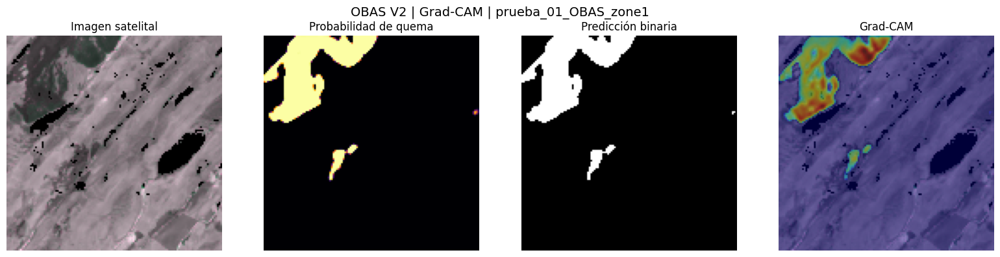

Grad-CAM mínimo: 0.0
Grad-CAM máximo: 1.0
Píxeles predichos como quemados: 1609


In [26]:
from pathlib import Path

identificador = "prueba_01_OBAS_zone1"

archivos = list(
    Path("/kaggle/input").rglob(
        f"{identificador}_imagen.npy"
    )
)

if not archivos:
    raise FileNotFoundError(
        f"No se encontró la imagen de {identificador}"
    )

ruta_imagen = archivos[0]

imagen_original = np.load(ruta_imagen)

print("Archivo:", ruta_imagen)
print("Forma original:", imagen_original.shape)

mapa_gradcam, probabilidad = generar_gradcam(
    imagen_original,
    modelo_gradcam
)

imagen_visual = imagen_original.copy()

if imagen_visual.shape == (3, 128, 128):
    imagen_visual = np.transpose(
        imagen_visual,
        (1, 2, 0)
    )

imagen_visual = np.nan_to_num(imagen_visual)

minimo = imagen_visual.min()
maximo = imagen_visual.max()

if maximo > minimo:
    imagen_visual = (
        imagen_visual - minimo
    ) / (maximo - minimo)

prediccion_binaria = (
    probabilidad >= 0.5
).astype(np.uint8)

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4)
)

axes[0].imshow(imagen_visual)
axes[0].set_title("Imagen satelital")

axes[1].imshow(
    probabilidad,
    cmap="inferno",
    vmin=0,
    vmax=1
)
axes[1].set_title("Probabilidad de quema")

axes[2].imshow(
    prediccion_binaria,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[2].set_title("Predicción binaria")

axes[3].imshow(imagen_visual)
axes[3].imshow(
    mapa_gradcam,
    cmap="jet",
    alpha=0.45,
    vmin=0,
    vmax=1
)
axes[3].set_title("Grad-CAM")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"OBAS V2 | Grad-CAM | {identificador}",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Grad-CAM mínimo:", mapa_gradcam.min())
print("Grad-CAM máximo:", mapa_gradcam.max())
print(
    "Píxeles predichos como quemados:",
    int(prediccion_binaria.sum())
)

## Paso 8.10. Análisis de explicabilidad con Grad-CAM

Se generan mapas Grad-CAM para 10 parches con buen
desempeño y 10 casos de contraste.

Se comparan la imagen original, la máscara real,
la predicción del modelo y las regiones de mayor
influencia en la decisión.

Los casos sin errores se identifican como controles
negativos y no como predicciones incorrectas.

In [28]:
from pathlib import Path

BASE = Path("/kaggle/input")
identificador = "prueba_19_CEMS_AOI01_01"

print("=== ARCHIVOS RELACIONADOS ===")

encontrados = [
    p for p in BASE.rglob("*.npy")
    if identificador.lower() in p.name.lower()
]

for archivo in encontrados[:30]:
    print(archivo)

print("\nTotal encontrados:", len(encontrados))

=== ARCHIVOS RELACIONADOS ===
/kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/resultados/mascaras_predichas/prueba_19_CEMS_AOI01_01_prediccion.npy
/kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/datos/mascaras_reales/prueba_19_CEMS_AOI01_01_mascara_real.npy
/kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/datos/parches/prueba_19_CEMS_AOI01_01_imagen.npy

Total encontrados: 3


In [29]:
from pathlib import Path
from collections import Counter

archivos = list(Path("/kaggle/input").rglob("*.npy"))

print("=== POSIBLES ARCHIVOS DE MÁSCARAS ===")

mascaras = [
    p for p in archivos
    if any(
        palabra in p.name.lower()
        for palabra in [
            "mascara",
            "mask",
            "ground_truth",
            "_gt",
            "label"
        ]
    )
]

for archivo in mascaras[:20]:
    print(archivo)

print("\nTotal de posibles máscaras:", len(mascaras))

print("\n=== TERMINACIONES MÁS FRECUENTES ===")
print(Counter(
    p.name.split("_")[-1]
    for p in archivos
).most_common(15))

=== POSIBLES ARCHIVOS DE MÁSCARAS ===
/kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/datos/mascaras_reales/prueba_01_OBAS_zone1_mascara_real.npy
/kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/datos/mascaras_reales/prueba_02_OBAS_zone1_mascara_real.npy
/kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/datos/mascaras_reales/prueba_03_OBAS_zone2_mascara_real.npy
/kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQUETE_FLUTTER_FINAL/datos/mascaras_reales/prueba_04_OBAS_zone3_mascara_real.npy
/kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_PAQUETE_FLUTTER_FINAL/OBAS_V2_PAQU

In [30]:
from pathlib import Path
import numpy as np

# Carpeta principal del proyecto
BASE_OBAS = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-respaldo-continuidad-aplicacion-movil/"
    "OBAS_V2_PAQUETE_FLUTTER_FINAL/"
    "OBAS_V2_PAQUETE_FLUTTER_FINAL"
)

CARPETA_IMAGENES = BASE_OBAS / "datos/parches"
CARPETA_MASCARAS = BASE_OBAS / "datos/mascaras_reales"
CARPETA_PREDICCIONES = BASE_OBAS / "resultados/mascaras_predichas"

def localizar_archivo(identificador, tipo):
    """
    Localiza los archivos reales de OBAS V2.
    """

    configuracion = {
        "imagen": (
            CARPETA_IMAGENES,
            "_imagen.npy"
        ),
        "mascara": (
            CARPETA_MASCARAS,
            "_mascara_real.npy"
        ),
        "mascara_real": (
            CARPETA_MASCARAS,
            "_mascara_real.npy"
        ),
        "prediccion": (
            CARPETA_PREDICCIONES,
            "_prediccion.npy"
        )
    }

    if tipo not in configuracion:
        raise ValueError(f"Tipo desconocido: {tipo}")

    carpeta, sufijo = configuracion[tipo]
    ruta = carpeta / f"{identificador}{sufijo}"

    if not ruta.is_file():
        raise FileNotFoundError(
            f"No se encontró el archivo: {ruta}"
        )

    return ruta


# Verificación con el parche 19
identificador = "prueba_19_CEMS_AOI01_01"

for tipo in ["imagen", "mascara", "prediccion"]:
    ruta = localizar_archivo(identificador, tipo)
    datos = np.load(ruta)

    print(f"\n{tipo.upper()}")
    print("Archivo:", ruta.name)
    print("Forma:", datos.shape)
    print("Tipo:", datos.dtype)

print("\nVERIFICACIÓN COMPLETADA")


IMAGEN
Archivo: prueba_19_CEMS_AOI01_01_imagen.npy
Forma: (3, 128, 128)
Tipo: float32

MASCARA
Archivo: prueba_19_CEMS_AOI01_01_mascara_real.npy
Forma: (128, 128)
Tipo: uint8

PREDICCION
Archivo: prueba_19_CEMS_AOI01_01_prediccion.npy
Forma: (128, 128)
Tipo: uint8

VERIFICACIÓN COMPLETADA


In [33]:
# PASO 8.14 - Selección de 10 casos de contraste

casos_errores = [
    "prueba_17_CEMS_AOI01_01",
    "prueba_07_OBAS_zone3",
    "prueba_05_OBAS_zone1",
    "prueba_02_OBAS_zone1",
    "prueba_03_OBAS_zone2",
    "prueba_04_OBAS_zone3",
    "prueba_06_OBAS_zone1",
    "prueba_18_CEMS_AOI01_01",
    "prueba_10_OBAS_zone1",
    "prueba_11_OBAS_zone1"
]

print("Casos de contraste seleccionados:", len(casos_errores))

for caso in casos_errores:
    print(caso)

Casos de contraste seleccionados: 10
prueba_17_CEMS_AOI01_01
prueba_07_OBAS_zone3
prueba_05_OBAS_zone1
prueba_02_OBAS_zone1
prueba_03_OBAS_zone2
prueba_04_OBAS_zone3
prueba_06_OBAS_zone1
prueba_18_CEMS_AOI01_01
prueba_10_OBAS_zone1
prueba_11_OBAS_zone1


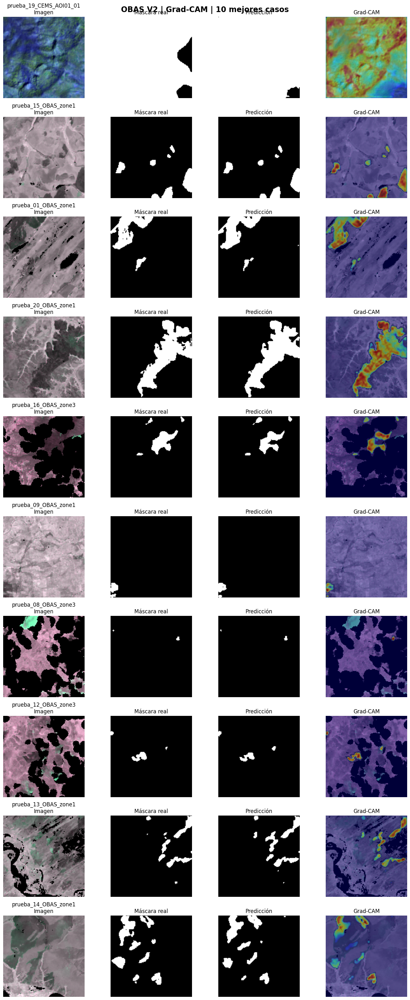

NameError: name 'casos_errores' is not defined

In [31]:
visualizar_grupo_gradcam(
    casos_aciertos,
    "OBAS V2 | Grad-CAM | 10 mejores casos"
)

visualizar_grupo_gradcam(
    casos_errores,
    "OBAS V2 | Grad-CAM | 10 casos de contraste"
)

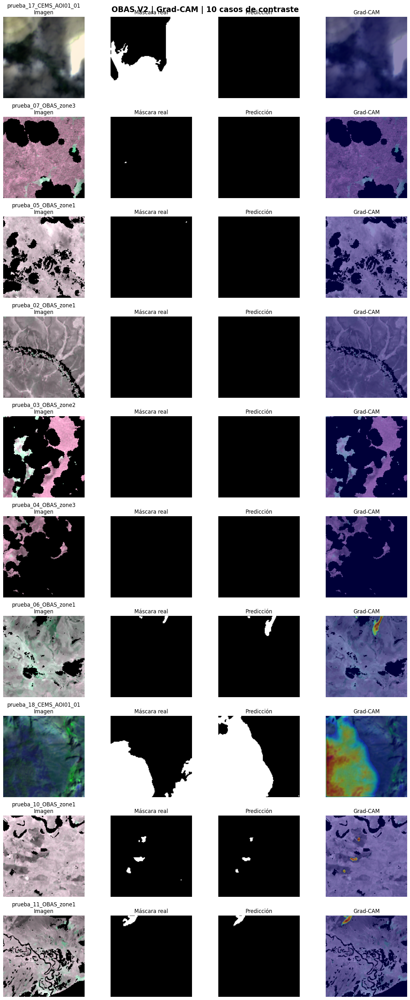

In [35]:
visualizar_grupo_gradcam(
    casos_errores,
    "OBAS V2 | Grad-CAM | 10 casos de contraste"
)

In [38]:
import numpy as np

print("=== VARIABLES DISPONIBLES ===")

for nombre, valor in list(globals().items()):
    if isinstance(valor, np.ndarray):
        if valor.size > 0:
            print(
                f"{nombre}: "
                f"forma={valor.shape}, "
                f"tipo={valor.dtype}"
            )

=== VARIABLES DISPONIBLES ===
datos: forma=(128, 128), tipo=uint8
imagen: forma=(128, 128, 3), tipo=float32
mascara: forma=(16384,), tipo=uint8
prediccion: forma=(16384,), tipo=uint8
axes: forma=(4,), tipo=object
imagen_visual: forma=(128, 128, 3), tipo=float32
mascara_visual: forma=(128, 128), tipo=uint8
prediccion_visual: forma=(128, 128), tipo=uint8
y_real: forma=(327680,), tipo=uint8
y_pred: forma=(327680,), tipo=uint8
matriz: forma=(2, 2), tipo=int64
entrada: forma=(1, 128, 128, 3), tipo=float32
salida: forma=(128, 128), tipo=float32
y_prob: forma=(327680,), tipo=float32
y_real_prob: forma=(327680,), tipo=uint8
primera_probabilidad: forma=(128, 128), tipo=float32
indices: forma=(6,), tipo=int64
mascara_real: forma=(128, 128), tipo=uint8
probabilidad: forma=(128, 128), tipo=float32
imagen_original: forma=(3, 128, 128), tipo=float32
mapa_gradcam: forma=(128, 128), tipo=float32
prediccion_binaria: forma=(128, 128), tipo=uint8


## Paso 9.2. Evaluación de la curva Precision-Recall

Se analiza el comportamiento del modelo Student MobileNetV2–UNet
para la segmentación de áreas quemadas, evaluando cómo cambian
la precisión y el recall según el umbral de decisión.

=== DATOS DE EVALUACIÓN ===
Píxeles evaluados: 327680
Píxeles quemados: 41677
Píxeles no quemados: 286003


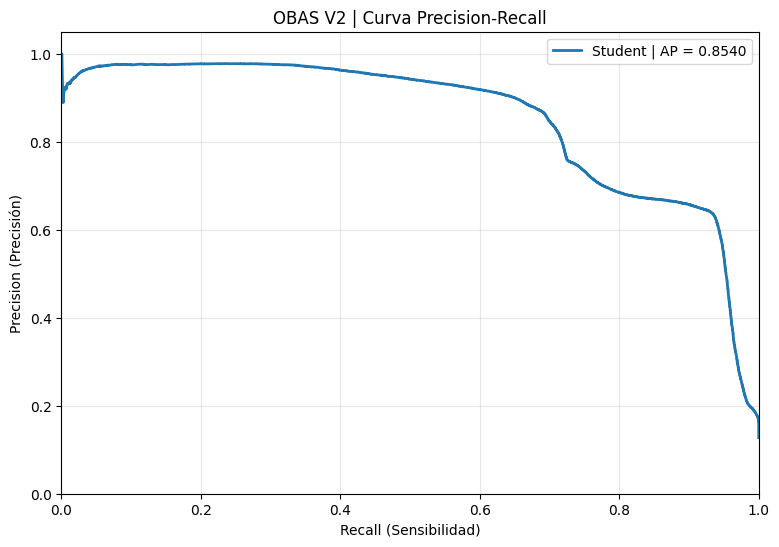


Average Precision (AP): 0.854

=== RESULTADOS CON UMBRAL 0.5 ===
Precision: 0.8403
Recall:    0.7034
F1-score:  0.7658


In [39]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Recuperar datos
y_true = np.asarray(y_real_prob).reshape(-1).astype(np.uint8)
y_scores = np.asarray(y_prob).reshape(-1).astype(np.float32)

# 2. Verificar correspondencia y validez
assert len(y_true) == len(y_scores), "Los tamaños no coinciden."
assert set(np.unique(y_true)).issubset({0, 1}), "Máscara no binaria."
assert np.all(np.isfinite(y_scores)), "Existen probabilidades inválidas."
assert np.all((y_scores >= 0) & (y_scores <= 1)), "Probabilidades fuera de rango."

print("=== DATOS DE EVALUACIÓN ===")
print("Píxeles evaluados:", len(y_true))
print("Píxeles quemados:", int(np.sum(y_true)))
print("Píxeles no quemados:", int(np.sum(y_true == 0)))

# 3. Calcular curva Precision-Recall
precision, recall, thresholds = precision_recall_curve(
    y_true,
    y_scores
)

ap = average_precision_score(y_true, y_scores)

# 4. Visualizar curva
plt.figure(figsize=(9, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"Student | AP = {ap:.4f}"
)

plt.xlabel("Recall (Sensibilidad)")
plt.ylabel("Precision (Precisión)")
plt.title("OBAS V2 | Curva Precision-Recall")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

print("\nAverage Precision (AP):", round(ap, 4))

# 5. Evaluación del umbral actual
pred_05 = (y_scores >= 0.5).astype(np.uint8)

print("\n=== RESULTADOS CON UMBRAL 0.5 ===")
print("Precision:", round(precision_score(y_true, pred_05, zero_division=0), 4))
print("Recall:   ", round(recall_score(y_true, pred_05, zero_division=0), 4))
print("F1-score: ", round(f1_score(y_true, pred_05, zero_division=0), 4))

Comparación de diferentes umbrales

=== COMPARACIÓN DE UMBRALES ===


,Umbral,Precision,Recall,F1-score
0,0.10,0.8223,0.7117,0.7630
1,0.15,0.8266,0.7099,0.7638
2,0.20,0.8300,0.7086,0.7645
3,0.25,0.8326,0.7077,0.7651
4,0.30,0.8347,0.7067,0.7654
5,0.35,0.8361,0.7058,0.7654
6,0.40,0.8375,0.7050,0.7656
7,0.45,0.8389,0.7040,0.7656
8,0.50,0.8403,0.7034,0.7658
9,0.55,0.8417,0.7024,0.7658



=== MEJOR UMBRAL OBSERVADO ===
Umbral: 0.9
Precision: 0.8661
Recall: 0.6911
F1-score: 0.7688


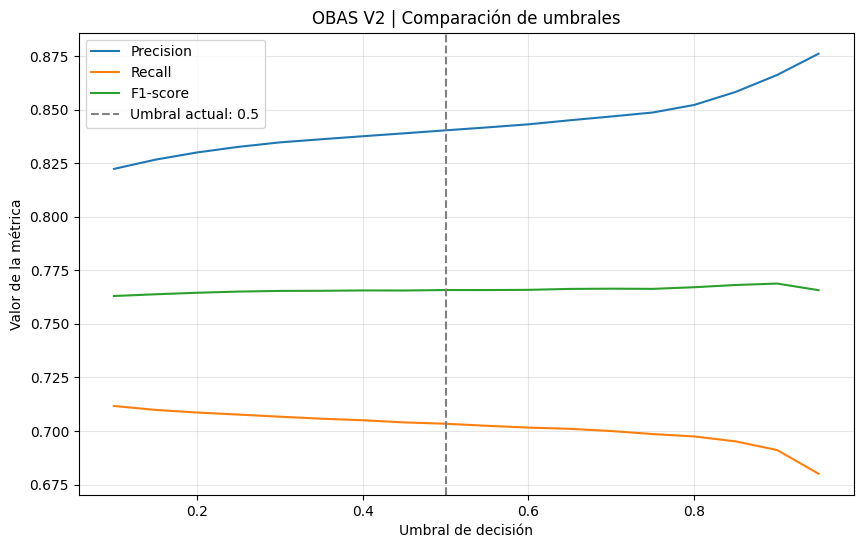

In [40]:
import pandas as pd

resultados_umbrales = []

for umbral in np.arange(0.1, 1.0, 0.05):

    pred = (y_scores >= umbral).astype(np.uint8)

    resultados_umbrales.append({
        "Umbral": round(float(umbral), 2),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-score": f1_score(y_true, pred, zero_division=0)
    })

df_umbrales = pd.DataFrame(resultados_umbrales)

print("=== COMPARACIÓN DE UMBRALES ===")
display(df_umbrales.round(4))

# Seleccionar el umbral con mejor F1 en esta muestra
mejor = df_umbrales.loc[df_umbrales["F1-score"].idxmax()]

print("\n=== MEJOR UMBRAL OBSERVADO ===")
print("Umbral:", mejor["Umbral"])
print("Precision:", round(mejor["Precision"], 4))
print("Recall:", round(mejor["Recall"], 4))
print("F1-score:", round(mejor["F1-score"], 4))

# Graficar
plt.figure(figsize=(10, 6))

plt.plot(df_umbrales["Umbral"], df_umbrales["Precision"], label="Precision")
plt.plot(df_umbrales["Umbral"], df_umbrales["Recall"], label="Recall")
plt.plot(df_umbrales["Umbral"], df_umbrales["F1-score"], label="F1-score")

plt.axvline(
    0.5,
    linestyle="--",
    color="gray",
    label="Umbral actual: 0.5"
)

plt.xlabel("Umbral de decisión")
plt.ylabel("Valor de la métrica")
plt.title("OBAS V2 | Comparación de umbrales")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [41]:
# Umbrales exploratorios
umbral_bajo = 0.30
umbral_alto = 0.70

# -1 = incierto, 0 = no quemado, 1 = quemado
estados = np.full(y_scores.shape, -1, dtype=np.int8)

estados[y_scores < umbral_bajo] = 0
estados[y_scores >= umbral_alto] = 1

total = len(estados)
inciertos = int(np.sum(estados == -1))
seguros = estados != -1

print("=== ANÁLISIS DE INCERTIDUMBRE ===")
print("Total de píxeles:", total)
print("Píxeles inciertos:", inciertos)
print("Porcentaje incierto:", round(100 * inciertos / total, 2), "%")
print("Porcentaje con decisión:", round(100 * np.mean(seguros), 2), "%")

if np.any(seguros):
    print("\n=== DESEMPEÑO EN PÍXELES CON DECISIÓN ===")
    print(
        "Precision:",
        round(precision_score(y_true[seguros], estados[seguros], zero_division=0), 4)
    )
    print(
        "Recall:",
        round(recall_score(y_true[seguros], estados[seguros], zero_division=0), 4)
    )
    print(
        "F1-score:",
        round(f1_score(y_true[seguros], estados[seguros], zero_division=0), 4)
    )
else:
    print("No hay píxeles con decisión.")

=== ANÁLISIS DE INCERTIDUMBRE ===
Total de píxeles: 327680
Píxeles inciertos: 833
Porcentaje incierto: 0.25 %
Porcentaje con decisión: 99.75 %

=== DESEMPEÑO EN PÍXELES CON DECISIÓN ===
Precision: 0.8468
Recall: 0.7047
F1-score: 0.7692


## Paso 10. Evaluación de robustez del modelo Student

Se analiza el desempeño del modelo Student MobileNetV2–UNet
ante cuatro perturbaciones simuladas: desenfoque, reducción
de iluminación, oclusión parcial y modificación del fondo.

Se compararán Precision, Recall y F1-score con los resultados
originales, manteniendo las mismas máscaras de referencia.

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

def preparar_imagen(imagen):
    """Convierte CHW a HWC y conserva valores float32."""
    imagen = np.asarray(imagen, dtype=np.float32)

    if imagen.shape == (3, 128, 128):
        imagen = np.transpose(imagen, (1, 2, 0))

    if imagen.shape != (128, 128, 3):
        raise ValueError(f"Forma inesperada: {imagen.shape}")

    return imagen


def aplicar_perturbacion(imagen, tipo):
    imagen = preparar_imagen(imagen).copy()

    if tipo == "Original":
        return imagen

    elif tipo == "Desenfoque":
        return cv2.GaussianBlur(imagen, (7, 7), 1.5)

    elif tipo == "Poca luz":
        return np.clip(imagen * 0.5, 0, 1)

    elif tipo == "Oclusion":
        imagen[40:88, 40:88, :] = 0
        return imagen

    elif tipo == "Cambio de fondo":
        # Perturbación sintética de contraste y canales.
        # No representa un cambio geográfico real.
        imagen = imagen[..., [1, 0, 2]]
        return np.clip(imagen * 0.85 + 0.05, 0, 1)

    else:
        raise ValueError("Perturbación desconocida")


print("Funciones de robustez creadas correctamente.")

Funciones de robustez creadas correctamente.


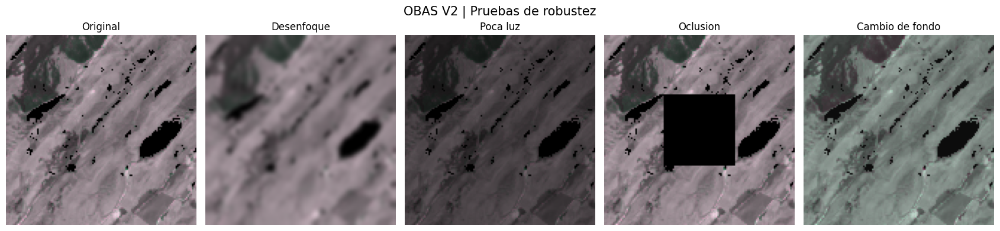

In [45]:
tipos = [
    "Original",
    "Desenfoque",
    "Poca luz",
    "Oclusion",
    "Cambio de fondo"
]

# Utilizamos la imagen que ya está cargada en el cuaderno
imagen_base = preparar_imagen(imagen_original)

fig, axes = plt.subplots(1, 5, figsize=(17, 4))

for ax, tipo in zip(axes, tipos):
    modificada = aplicar_perturbacion(imagen_base, tipo)

    ax.imshow(np.clip(modificada, 0, 1))
    ax.set_title(tipo)
    ax.axis("off")

plt.suptitle("OBAS V2 | Pruebas de robustez", fontsize=15)
plt.tight_layout()
plt.show()

Verificar las rutas de los 20 parches

In [46]:
from pathlib import Path

BASE = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-respaldo-continuidad-aplicacion-movil/"
    "OBAS_V2_PAQUETE_FLUTTER_FINAL/"
    "OBAS_V2_PAQUETE_FLUTTER_FINAL"
)

CARPETA_IMAGENES = BASE / "datos" / "parches"
CARPETA_MASCARAS = BASE / "datos" / "mascaras_reales"

archivos_imagenes = sorted(
    CARPETA_IMAGENES.glob("prueba_*_imagen.npy")
)

pares_validos = []

for ruta_imagen in archivos_imagenes:
    identificador = ruta_imagen.name.replace("_imagen.npy", "")
    ruta_mascara = CARPETA_MASCARAS / (
        identificador + "_mascara_real.npy"
    )

    if ruta_mascara.exists():
        pares_validos.append(
            (identificador, ruta_imagen, ruta_mascara)
        )
    else:
        print("Falta máscara:", identificador)

print("=== VERIFICACIÓN DE ARCHIVOS ===")
print("Imágenes encontradas:", len(archivos_imagenes))
print("Pares completos:", len(pares_validos))

for identificador, _, _ in pares_validos:
    print("OK:", identificador)

assert len(pares_validos) == 20, (
    "Se esperaban 20 pares completos. Revisar rutas."
)

=== VERIFICACIÓN DE ARCHIVOS ===
Imágenes encontradas: 20
Pares completos: 20
OK: prueba_01_OBAS_zone1
OK: prueba_02_OBAS_zone1
OK: prueba_03_OBAS_zone2
OK: prueba_04_OBAS_zone3
OK: prueba_05_OBAS_zone1
OK: prueba_06_OBAS_zone1
OK: prueba_07_OBAS_zone3
OK: prueba_08_OBAS_zone3
OK: prueba_09_OBAS_zone1
OK: prueba_10_OBAS_zone1
OK: prueba_11_OBAS_zone1
OK: prueba_12_OBAS_zone3
OK: prueba_13_OBAS_zone1
OK: prueba_14_OBAS_zone1
OK: prueba_15_OBAS_zone1
OK: prueba_16_OBAS_zone3
OK: prueba_17_CEMS_AOI01_01
OK: prueba_18_CEMS_AOI01_01
OK: prueba_19_CEMS_AOI01_01
OK: prueba_20_OBAS_zone1


### Paso 10.4. Evaluación cuantitativa de robustez

Se evalúa el modelo Student MobileNetV2–UNet utilizando 20
parches satelitales bajo cinco condiciones: original,
desenfoque, poca luz, oclusión parcial y cambio sintético
de apariencia.

Se calculan Precision, Recall y F1-score por píxel para
identificar las condiciones que afectan la detección de
áreas quemadas.

In [48]:
import tensorflow as tf
from pathlib import Path

# Ruta del modelo Student
ruta_modelo_student = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-final-backup/models/"
    "Student_MobileNetV2_UNet_V2_baseline_best.keras"
)

print("Archivo encontrado:", ruta_modelo_student.exists())

# Cargar el modelo para realizar predicciones
modelo_student = tf.keras.models.load_model(
    str(ruta_modelo_student),
    compile=False
)

print("\n=== MODELO STUDENT CARGADO ===")
print("Nombre:", modelo_student.name)
print("Entrada:", modelo_student.input_shape)
print("Salida:", modelo_student.output_shape)
print("Parámetros:", modelo_student.count_params())

Archivo encontrado: True

=== MODELO STUDENT CARGADO ===
Nombre: Student_MobileNetV2_UNet_V2
Entrada: (None, 128, 128, 3)
Salida: (None, 128, 128, 1)
Parámetros: 8045857


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Verificar que el modelo esté disponible
assert "modelo" in globals(), (
    "No se encontró la variable 'modelo'. "
    "Ejecuta primero la celda donde cargaste el Student."
)

assert len(pares_validos) == 20, (
    "No están disponibles los 20 pares de evaluación."
)

condiciones = [
    "Original",
    "Desenfoque",
    "Poca luz",
    "Oclusion",
    "Cambio de fondo"
]

resultados_robustez = []
resultados_por_parche = []

for condicion in condiciones:

    reales_total = []
    predicciones_total = []

    print(f"\nEvaluando condición: {condicion}")

    for identificador, ruta_imagen, ruta_mascara in pares_validos:

        # 1. Cargar imagen y máscara
        imagen_np = np.load(ruta_imagen)
        mascara_np = np.load(ruta_mascara)

        # 2. Preparar imagen y aplicar perturbación
        imagen_hwc = preparar_imagen(imagen_np)

        imagen_modificada = aplicar_perturbacion(
            imagen_hwc,
            condicion
        )

        # 3. Preparar entrada
        entrada_modelo = np.expand_dims(
            imagen_modificada.astype(np.float32),
            axis=0
        )

        # 4. Obtener probabilidades del Student
        salida_modelo = modelo_student.predict(
    entrada_modelo,
    verbose=0
)

        probabilidades = np.squeeze(salida_modelo)

        if probabilidades.shape != (128, 128):
            raise ValueError(
                f"Salida inesperada: {probabilidades.shape}"
            )

        # 5. Convertir a predicción binaria
        pred_binaria = (
            probabilidades >= 0.5
        ).astype(np.uint8)

        real_binaria = (
            np.squeeze(mascara_np) > 0
        ).astype(np.uint8)

        # 6. Guardar valores para métricas globales
        reales_total.append(real_binaria.reshape(-1))
        predicciones_total.append(pred_binaria.reshape(-1))

        # 7. Métricas individuales
        resultados_por_parche.append({
            "Parche": identificador,
            "Condicion": condicion,
            "Precision": precision_score(
                real_binaria.reshape(-1),
                pred_binaria.reshape(-1),
                zero_division=0
            ),
            "Recall": recall_score(
                real_binaria.reshape(-1),
                pred_binaria.reshape(-1),
                zero_division=0
            ),
            "F1": f1_score(
                real_binaria.reshape(-1),
                pred_binaria.reshape(-1),
                zero_division=0
            )
        })

    # 8. Consolidar todos los píxeles
    y_real_condicion = np.concatenate(reales_total)
    y_pred_condicion = np.concatenate(predicciones_total)

    tn, fp, fn, tp = confusion_matrix(
        y_real_condicion,
        y_pred_condicion,
        labels=[0, 1]
    ).ravel()

    resultados_robustez.append({
        "Condicion": condicion,
        "Precision": precision_score(
            y_real_condicion,
            y_pred_condicion,
            zero_division=0
        ),
        "Recall": recall_score(
            y_real_condicion,
            y_pred_condicion,
            zero_division=0
        ),
        "F1": f1_score(
            y_real_condicion,
            y_pred_condicion,
            zero_division=0
        ),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "TN": int(tn)
    })

# 9. Crear tablas
df_robustez = pd.DataFrame(resultados_robustez)
df_robustez_parches = pd.DataFrame(resultados_por_parche)

# 10. Calcular variación respecto a la condición original
f1_original = df_robustez.loc[
    df_robustez["Condicion"] == "Original",
    "F1"
].iloc[0]

df_robustez["Cambio_F1_pp"] = (
    df_robustez["F1"] - f1_original
) * 100

print("\n=== RESULTADOS DE ROBUSTEZ OBAS V2 ===")
display(df_robustez.round(4))

print("\n=== VARIACIÓN DEL F1 ===")
for _, fila in df_robustez.iterrows():
    print(
        f"{fila['Condicion']}: "
        f"F1={fila['F1']:.4f} | "
        f"Cambio={fila['Cambio_F1_pp']:+.2f} puntos porcentuales"
    )

# 11. Guardar resultados
df_robustez.to_csv(
    "/kaggle/working/OBAS_V2_robustez_resumen.csv",
    index=False
)

df_robustez_parches.to_csv(
    "/kaggle/working/OBAS_V2_robustez_por_parche.csv",
    index=False
)

print("\nArchivos CSV guardados correctamente.")


Evaluando condición: Original

Evaluando condición: Desenfoque

Evaluando condición: Poca luz

Evaluando condición: Oclusion

Evaluando condición: Cambio de fondo

=== RESULTADOS DE ROBUSTEZ OBAS V2 ===


,Condicion,Precision,Recall,F1,FP,FN,TP,TN,Cambio_F1_pp
0,Original,0.8403,0.7034,0.7658,5572,12361,29316,280431,0.0000
1,Desenfoque,0.0000,0.0000,0.0000,691,41677,0,285312,-76.5781
2,Poca luz,0.2840,0.6846,0.4015,71934,13144,28533,214069,-36.4315
3,Oclusion,0.9093,0.5915,0.7168,2458,17023,24654,283545,-4.8980
4,Cambio de fondo,0.7415,0.1994,0.3143,2897,33366,8311,283106,-45.1476



=== VARIACIÓN DEL F1 ===
Original: F1=0.7658 | Cambio=+0.00 puntos porcentuales
Desenfoque: F1=0.0000 | Cambio=-76.58 puntos porcentuales
Poca luz: F1=0.4015 | Cambio=-36.43 puntos porcentuales
Oclusion: F1=0.7168 | Cambio=-4.90 puntos porcentuales
Cambio de fondo: F1=0.3143 | Cambio=-45.15 puntos porcentuales

Archivos CSV guardados correctamente.


## Paso 10.5. Comparación visual del desempeño bajo diferentes condiciones

Se comparan las métricas de precisión, recall y F1-score
del modelo Student ante alteraciones simuladas de las
imágenes satelitales. Se utiliza la condición original
como referencia para medir la pérdida de desempeño.

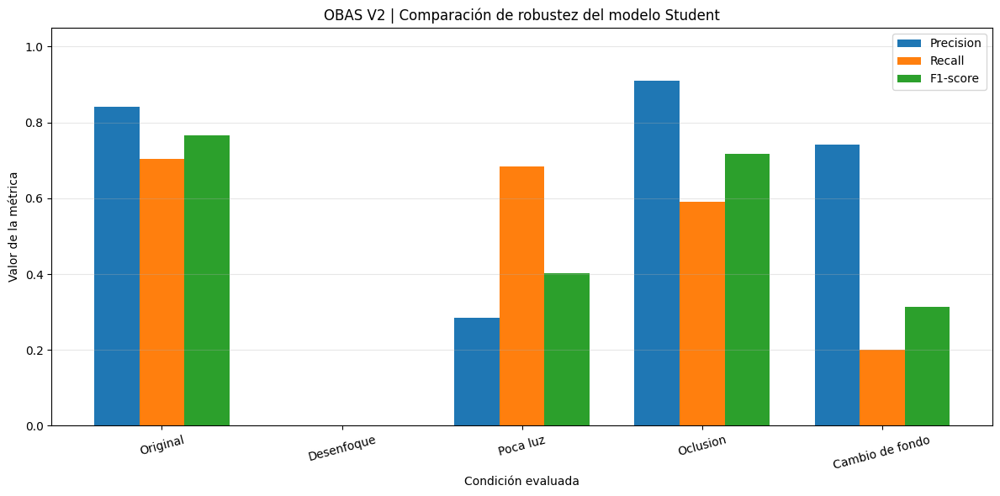

Gráfica de robustez generada correctamente.


In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Resultados obtenidos en el paso 10.4
resultados_robustez = pd.DataFrame({
    "Condicion": [
        "Original",
        "Desenfoque",
        "Poca luz",
        "Oclusion",
        "Cambio de fondo"
    ],
    "Precision": [
        0.8403, 0.0000, 0.2840, 0.9093, 0.7415
    ],
    "Recall": [
        0.7034, 0.0000, 0.6846, 0.5915, 0.1994
    ],
    "F1": [
        0.7658, 0.0000, 0.4015, 0.7168, 0.3143
    ]
})

x = np.arange(len(resultados_robustez))
ancho = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - ancho,
    resultados_robustez["Precision"],
    ancho,
    label="Precision"
)

ax.bar(
    x,
    resultados_robustez["Recall"],
    ancho,
    label="Recall"
)

ax.bar(
    x + ancho,
    resultados_robustez["F1"],
    ancho,
    label="F1-score"
)

ax.set_title(
    "OBAS V2 | Comparación de robustez del modelo Student"
)

ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("Condición evaluada")

ax.set_xticks(x)
ax.set_xticklabels(
    resultados_robustez["Condicion"],
    rotation=15
)

ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/OBAS_V2_comparacion_robustez.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Gráfica de robustez generada correctamente.")

## Paso 11. Evaluación de estabilidad mediante tres semillas

Se evalúa la variabilidad de las métricas del modelo Student
mediante remuestreo bootstrap de los 20 parches disponibles.

Se utilizan tres semillas reproducibles: 42, 123 y 2026.

Para cada semilla se seleccionan 20 parches con reemplazo,
se calculan Precision, Recall y F1-score por píxel y se
reportan la media y la desviación estándar entre las tres
repeticiones.

Esta prueba mide la sensibilidad de los resultados a la
selección de parches. No representa tres entrenamientos
independientes del modelo.

In [51]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import precision_score, recall_score, f1_score

BASE = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-respaldo-continuidad-aplicacion-movil/"
    "OBAS_V2_PAQUETE_FLUTTER_FINAL/"
    "OBAS_V2_PAQUETE_FLUTTER_FINAL"
)

RUTA_REALES = BASE / "datos/mascaras_reales"
RUTA_PREDICCIONES = BASE / "resultados/mascaras_predichas"

# Identificar pares completos
pares = []

for ruta_real in sorted(RUTA_REALES.glob("*_mascara_real.npy")):

    identificador = ruta_real.name.replace(
        "_mascara_real.npy", ""
    )

    ruta_pred = (
        RUTA_PREDICCIONES /
        f"{identificador}_prediccion.npy"
    )

    if ruta_pred.exists():
        pares.append((identificador, ruta_real, ruta_pred))

print("Pares completos encontrados:", len(pares))

assert len(pares) == 20, (
    "Se esperaban 20 pares. Revisar rutas y archivos."
)

# Cargar los 20 pares una sola vez
mascaras_reales = []
mascaras_predichas = []

for identificador, ruta_real, ruta_pred in pares:

    real = np.load(ruta_real).reshape(-1)
    pred = np.load(ruta_pred).reshape(-1)

    assert real.shape == pred.shape, identificador

    mascaras_reales.append(real.astype(np.uint8))
    mascaras_predichas.append(pred.astype(np.uint8))

# Tres remuestreos bootstrap
semillas = [42, 123, 2026]
resultados_semillas = []

for semilla in semillas:

    rng = np.random.default_rng(semilla)

    indices = rng.choice(
        len(pares),
        size=len(pares),
        replace=True
    )

    y_real_semilla = np.concatenate([
        mascaras_reales[i] for i in indices
    ])

    y_pred_semilla = np.concatenate([
        mascaras_predichas[i] for i in indices
    ])

    precision = precision_score(
        y_real_semilla,
        y_pred_semilla,
        zero_division=0
    )

    recall = recall_score(
        y_real_semilla,
        y_pred_semilla,
        zero_division=0
    )

    f1 = f1_score(
        y_real_semilla,
        y_pred_semilla,
        zero_division=0
    )

    resultados_semillas.append({
        "Semilla": semilla,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Parches_muestreados": len(indices),
        "Parches_unicos": len(np.unique(indices))
    })

df_semillas = pd.DataFrame(resultados_semillas)

print("\n=== RESULTADOS POR SEMILLA ===")
display(df_semillas.round(4))

# Media y desviación estándar muestral
columnas = ["Precision", "Recall", "F1"]

resumen = pd.DataFrame({
    "Metrica": columnas,
    "Media": df_semillas[columnas].mean().values,
    "Desviacion_estandar": df_semillas[columnas].std(ddof=1).values
})

print("\n=== MEDIA Y DESVIACIÓN ESTÁNDAR ===")
display(resumen.round(4))

# Guardar resultados
df_semillas.to_csv(
    "/kaggle/working/OBAS_V2_tres_semillas.csv",
    index=False
)

resumen.to_csv(
    "/kaggle/working/OBAS_V2_resumen_semillas.csv",
    index=False
)

print("\nArchivos CSV guardados correctamente.")

Pares completos encontrados: 20

=== RESULTADOS POR SEMILLA ===


,Semilla,Precision,Recall,F1,Parches_muestreados,Parches_unicos
0,42,0.7747,0.5472,0.6413,20,12
1,123,0.8209,0.6524,0.7270,20,14
2,2026,0.7807,0.7064,0.7417,20,13



=== MEDIA Y DESVIACIÓN ESTÁNDAR ===


,Metrica,Media,Desviacion_estandar
0,Precision,0.7921,0.0252
1,Recall,0.6353,0.0810
2,F1,0.7033,0.0542



Archivos CSV guardados correctamente.


### Paso 11.3. Comparación de métricas entre semillas

Se presentan las métricas Precision, Recall y F1-score
obtenidas mediante tres remuestreos bootstrap.

El objetivo es identificar la variabilidad del desempeño
del modelo Student ante diferentes selecciones de parches.

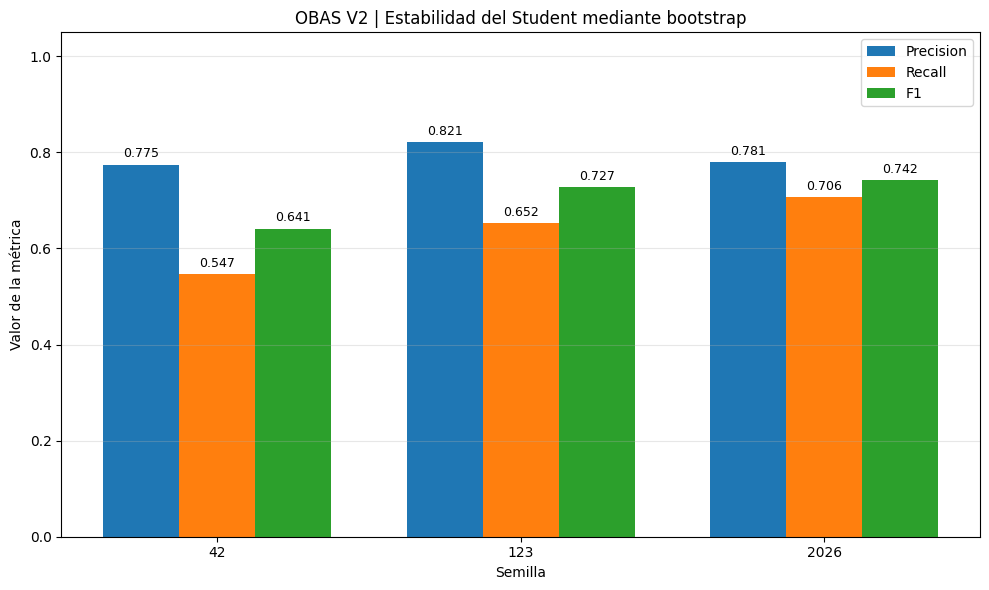

Gráfica de estabilidad guardada correctamente.


In [52]:
import numpy as np
import matplotlib.pyplot as plt

metricas = ["Precision", "Recall", "F1"]
semillas = df_semillas["Semilla"].astype(str).tolist()

x = np.arange(len(semillas))
ancho = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

for i, metrica in enumerate(metricas):
    posiciones = x + (i - 1) * ancho

    barras = ax.bar(
        posiciones,
        df_semillas[metrica],
        ancho,
        label=metrica
    )

    ax.bar_label(
        barras,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "OBAS V2 | Estabilidad del Student mediante bootstrap"
)

ax.set_xlabel("Semilla")
ax.set_ylabel("Valor de la métrica")

ax.set_xticks(x)
ax.set_xticklabels(semillas)
ax.set_ylim(0, 1.05)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/OBAS_V2_estabilidad_semillas.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Gráfica de estabilidad guardada correctamente.")

## Paso 12. Preparación de las pruebas de campo

Se prepara la evaluación del modelo Student con imágenes
nuevas de la región, utilizando la aplicación OBAS V2.

El modelo realiza segmentación binaria por píxel:
- 0: No quemado.
- 1: Quemado.

Se verificará el formato de entrada de las imágenes y se
registrarán los resultados de inferencia para construir
el archivo CSV solicitado.

Las imágenes deberán ser independientes de las utilizadas
para entrenamiento y evaluación.

In [53]:
import numpy as np
from pathlib import Path

print("=== REQUISITOS DEL MODELO STUDENT ===")

print("Entrada:", modelo_student.input_shape)
print("Salida:", modelo_student.output_shape)

print("\n=== ARCHIVOS DE PRUEBA DISPONIBLES ===")

ruta_parches = BASE / "datos/parches"

archivos = sorted(ruta_parches.glob("*_imagen.npy"))

print("Imágenes disponibles:", len(archivos))

if archivos:
    ejemplo = np.load(archivos[0])

    print("Ejemplo:", archivos[0].name)
    print("Forma original:", ejemplo.shape)
    print("Tipo:", ejemplo.dtype)
    print("Mínimo:", ejemplo.min())
    print("Máximo:", ejemplo.max())

    if ejemplo.shape == (3, 128, 128):
        ejemplo = np.transpose(ejemplo, (1, 2, 0))

    print("Forma para el modelo:", ejemplo.shape)

    assert ejemplo.shape == (128, 128, 3)

    print("\nFormato compatible con el modelo.")

=== REQUISITOS DEL MODELO STUDENT ===
Entrada: (None, 128, 128, 3)
Salida: (None, 128, 128, 1)

=== ARCHIVOS DE PRUEBA DISPONIBLES ===
Imágenes disponibles: 20
Ejemplo: prueba_01_OBAS_zone1_imagen.npy
Forma original: (3, 128, 128)
Tipo: float32
Mínimo: 0.0
Máximo: 0.96428573
Forma para el modelo: (128, 128, 3)

Formato compatible con el modelo.


### Paso 12.3. Registro de pruebas de campo regionales

Se prepara un archivo CSV para documentar al menos 50
imágenes nuevas evaluadas mediante la aplicación OBAS V2.

Debido a que el modelo realiza segmentación binaria,
se registrarán tanto la identificación de áreas quemadas
como el porcentaje de píxeles predichos como quemados.

Cada registro deberá incluir:
- Archivo de imagen.
- Clase real: quemado, no quemado o sin verificar.
- Predicción del modelo.
- Confianza de la predicción.
- Tiempo de respuesta en milisegundos.

No se utilizarán los 20 parches anteriores como
evidencia de nuevas pruebas de campo.

In [54]:
import pandas as pd
from pathlib import Path

RUTA_SALIDA = Path("/kaggle/working")
RUTA_SALIDA.mkdir(parents=True, exist_ok=True)

columnas = [
    "archivo",
    "clase_real",
    "prediccion",
    "confianza",
    "tiempo_respuesta_ms",
    "porcentaje_area_quemada",
    "ubicacion",
    "fecha_captura",
    "fuente_imagen",
    "observaciones"
]

df_campo = pd.DataFrame(columns=columnas)

archivo_csv = (
    RUTA_SALIDA /
    "S15_PruebaCampo_Galviz_Falla_Pena.csv"
)

df_campo.to_csv(
    archivo_csv,
    index=False,
    encoding="utf-8-sig"
)

print("=== PLANTILLA DE PRUEBA DE CAMPO ===")
print("Archivo:", archivo_csv)
print("Registros completados:", len(df_campo))
print("Registros requeridos:", 50)

display(df_campo)

=== PLANTILLA DE PRUEBA DE CAMPO ===
Archivo: /kaggle/working/S15_PruebaCampo_Galviz_Falla_Pena.csv
Registros completados: 0
Registros requeridos: 50


,archivo,clase_real,prediccion,confianza,tiempo_respuesta_ms,porcentaje_area_quemada,ubicacion,fecha_captura,fuente_imagen,observaciones


In [57]:

from pathlib import Path
import numpy as np
import pandas as pd

# Dataset original
BASE = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-burned-area-segmentation/"
    "OBAS_V2_common_patches/common_patches"
)

# Cantidad de parches por zona
DISTRIBUCION = {
    "OBAS_zone1": 15,
    "OBAS_zone2": 10,
    "OBAS_zone3": 15,
    "CEMS_AOI01_01": 10
}

# Semilla para reproducibilidad
rng = np.random.default_rng(2026)

registros = []

for zona, cantidad in DISTRIBUCION.items():

    carpeta_imagenes = BASE / zona / "images"
    carpeta_mascaras = BASE / zona / "masks"

    imagenes = sorted(carpeta_imagenes.glob("*.npy"))

    # Solo archivos que tengan su máscara correspondiente
    pares = []

    for imagen in imagenes:
        mascara = carpeta_mascaras / imagen.name

        if mascara.is_file():
            pares.append((imagen, mascara))

    if len(pares) < cantidad:
        raise ValueError(
            f"{zona}: solo hay {len(pares)} pares completos"
        )

    # Selección aleatoria sin reemplazo
    indices = rng.choice(
        len(pares),
        size=cantidad,
        replace=False
    )

    for indice in indices:
        imagen, mascara = pares[int(indice)]

        registros.append({
            "Zona": zona,
            "Parche": imagen.stem,
            "Ruta_imagen": str(imagen),
            "Ruta_mascara": str(mascara)
        })

# Crear tabla
df_50_nuevos = pd.DataFrame(registros)

# Verificar duplicados
assert len(df_50_nuevos) == 50
assert df_50_nuevos["Parche"].is_unique

# Guardar selección
SALIDA = Path("/kaggle/working/OBAS_V2_Auditoria_50")
SALIDA.mkdir(parents=True, exist_ok=True)

ruta_csv = SALIDA / "seleccion_50_parches.csv"
df_50_nuevos.to_csv(ruta_csv, index=False)

print("=== NUEVA MUESTRA OBAS V2 ===")
print("Parches seleccionados:", len(df_50_nuevos))
print()
print("Distribución:")
print(df_50_nuevos["Zona"].value_counts())
print()
print("Primeros 10 parches:")
print(df_50_nuevos[["Zona", "Parche"]].head(10).to_string(index=False))
print()
print("Identificadores únicos:",
      df_50_nuevos["Parche"].nunique())
print("Archivo guardado:", ruta_csv)


=== NUEVA MUESTRA OBAS V2 ===
Parches seleccionados: 50

Distribución:
Zona
OBAS_zone1       15
OBAS_zone3       15
OBAS_zone2       10
CEMS_AOI01_01    10
Name: count, dtype: int64

Primeros 10 parches:
      Zona            Parche
OBAS_zone1 OBAS_zone1_001532
OBAS_zone1 OBAS_zone1_003518
OBAS_zone1 OBAS_zone1_001510
OBAS_zone1 OBAS_zone1_002988
OBAS_zone1 OBAS_zone1_003440
OBAS_zone1 OBAS_zone1_001469
OBAS_zone1 OBAS_zone1_000330
OBAS_zone1 OBAS_zone1_001932
OBAS_zone1 OBAS_zone1_003750
OBAS_zone1 OBAS_zone1_003273

Identificadores únicos: 50
Archivo guardado: /kaggle/working/OBAS_V2_Auditoria_50/seleccion_50_parches.csv


### Paso 12.6. Validación de los 50 pares imagen-máscara

Se verifica que los 50 parches seleccionados tengan imágenes
de 3 canales con dimensiones 128 × 128 y máscaras binarias
de referencia de 128 × 128.

También se identifica cuántos parches contienen áreas
quemadas y cuántos no presentan píxeles quemados.

In [58]:
import numpy as np

print("=== VERIFICACIÓN DE LOS 50 PARCHES ===")

correctos = 0
con_quema = 0
sin_quema = 0
errores = []

for fila in df_50_nuevos.itertuples():

    try:
        imagen = np.load(fila.Ruta_imagen, allow_pickle=False)
        mascara = np.load(fila.Ruta_mascara, allow_pickle=False)

        if imagen.shape != (3, 128, 128):
            raise ValueError(
                f"Forma de imagen incorrecta: {imagen.shape}"
            )

        if mascara.shape != (128, 128):
            raise ValueError(
                f"Forma de máscara incorrecta: {mascara.shape}"
            )

        if not np.isfinite(imagen).all():
            raise ValueError("Imagen contiene valores inválidos")

        if not np.isin(mascara, [0, 1]).all():
            raise ValueError("Máscara no binaria")

        correctos += 1

        if np.any(mascara == 1):
            con_quema += 1
        else:
            sin_quema += 1

    except Exception as e:
        errores.append((fila.Parche, str(e)))

print("Pares correctos:", correctos)
print("Parches con quema real:", con_quema)
print("Parches sin quema real:", sin_quema)
print("Errores:", len(errores))

for parche, error in errores:
    print("ERROR:", parche, error)

assert correctos == 50, "Hay archivos que requieren revisión."

=== VERIFICACIÓN DE LOS 50 PARCHES ===
Pares correctos: 50
Parches con quema real: 27
Parches sin quema real: 23
Errores: 0


### Paso 12.7. Inferencia del modelo Student en 50 parches

Se ejecuta el modelo Student MobileNetV2–UNet sobre
50 parches satelitales seleccionados del dataset OBAS V2.

Para cada parche se registra:
- Clase real según la máscara de referencia.
- Clase predicha según la presencia de píxeles quemados.
- Confianza de la predicción.
- Porcentaje de superficie predicha como quemada.
- Tiempo de inferencia en milisegundos.
- Precision, Recall, F1-score e IoU por parche.

Se utiliza un umbral de segmentación de 0.5.

Los resultados representan una evaluación adicional del
dataset. Su independencia respecto al entrenamiento
todavía debe verificarse.

In [59]:

import numpy as np
import pandas as pd
import time
from pathlib import Path
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    jaccard_score
)

UMBRAL = 0.5
resultados_50 = []

SALIDA = Path("/kaggle/working/OBAS_V2_Auditoria_50")
SALIDA.mkdir(parents=True, exist_ok=True)

# Preparación inicial del modelo, fuera de la medición
imagen_inicial = np.load(
    df_50_nuevos.iloc[0]["Ruta_imagen"],
    allow_pickle=False
)
imagen_inicial = np.transpose(
    imagen_inicial, (1, 2, 0)
).astype(np.float32)

_ = modelo_student(
    imagen_inicial[np.newaxis, ...],
    training=False
).numpy()

for numero, fila in enumerate(
    df_50_nuevos.itertuples(), start=1
):
    imagen = np.load(
        fila.Ruta_imagen,
        allow_pickle=False
    )

    mascara_real = np.load(
        fila.Ruta_mascara,
        allow_pickle=False
    ).astype(np.uint8)

    imagen = np.transpose(
        imagen, (1, 2, 0)
    ).astype(np.float32)

    entrada = imagen[np.newaxis, ...]

    # Medición del tiempo de inferencia
    inicio = time.perf_counter()

    probabilidades = modelo_student(
        entrada, training=False
    ).numpy()[0, :, :, 0]

    tiempo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    mascara_predicha = (
        probabilidades >= UMBRAL
    ).astype(np.uint8)

    real = mascara_real.ravel()
    pred = mascara_predicha.ravel()

    precision = precision_score(
        real, pred, zero_division=0
    )

    recall = recall_score(
        real, pred, zero_division=0
    )

    f1 = f1_score(
        real, pred, zero_division=0
    )

    iou = jaccard_score(
        real, pred, zero_division=0
    )

    clase_real = (
        "Quemado"
        if np.any(mascara_real == 1)
        else "No quemado"
    )

    clase_predicha = (
        "Quemado"
        if np.any(mascara_predicha == 1)
        else "No quemado"
    )

    # Confianza media de la decisión por píxel
    confianza = float(
        np.mean(
            np.maximum(
                probabilidades,
                1 - probabilidades
            )
        )
    )

    porcentaje_quemado = float(
        mascara_predicha.mean() * 100
    )

    resultados_50.append({
        "archivo": fila.Parche + ".npy",
        "zona": fila.Zona,
        "clase_real": clase_real,
        "prediccion": clase_predicha,
        "confianza": round(confianza, 4),
        "tiempo_respuesta_ms": round(tiempo_ms, 2),
        "porcentaje_area_quemada": round(
            porcentaje_quemado, 2
        ),
        "precision": round(float(precision), 4),
        "recall": round(float(recall), 4),
        "f1": round(float(f1), 4),
        "iou": round(float(iou), 4),
        "pixeles_quemados_reales": int(
            mascara_real.sum()
        ),
        "pixeles_quemados_predichos": int(
            mascara_predicha.sum()
        )
    })

    if numero % 10 == 0:
        print(f"Procesados: {numero}/50")

df_resultados_50 = pd.DataFrame(resultados_50)

ruta_resultados = (
    SALIDA / "S15_PruebaDataset_50_Galviz_Falla_Pena.csv"
)

df_resultados_50.to_csv(
    ruta_resultados,
    index=False,
    encoding="utf-8-sig"
)

print("\n=== EVALUACIÓN DE 50 PARCHES COMPLETADA ===")
print("Total evaluados:", len(df_resultados_50))
print("Archivo CSV:", ruta_resultados)

print("\n=== RESUMEN DE INFERENCIA ===")
print(
    "Tiempo promedio (ms):",
    round(
        df_resultados_50["tiempo_respuesta_ms"].mean(),
        2
    )
)

print(
    "Tiempo máximo (ms):",
    round(
        df_resultados_50["tiempo_respuesta_ms"].max(),
        2
    )
)

print("\n=== PRIMEROS 10 RESULTADOS ===")

display(df_resultados_50.head(10))


Procesados: 10/50
Procesados: 20/50
Procesados: 30/50
Procesados: 40/50
Procesados: 50/50

=== EVALUACIÓN DE 50 PARCHES COMPLETADA ===
Total evaluados: 50
Archivo CSV: /kaggle/working/OBAS_V2_Auditoria_50/S15_PruebaDataset_50_Galviz_Falla_Pena.csv

=== RESUMEN DE INFERENCIA ===
Tiempo promedio (ms): 261.74
Tiempo máximo (ms): 297.81

=== PRIMEROS 10 RESULTADOS ===


,archivo,zona,clase_real,prediccion,confianza,tiempo_respuesta_ms,porcentaje_area_quemada,precision,recall,f1,iou,pixeles_quemados_reales,pixeles_quemados_predichos
0,OBAS_zone1_001532.npy,OBAS_zone1,Quemado,Quemado,0.9992,269.72,1.54,0.9328,0.9402,0.9365,0.8806,251,253
1,OBAS_zone1_003518.npy,OBAS_zone1,Quemado,Quemado,0.9974,260.66,1.70,0.8136,0.6504,0.7229,0.5661,349,279
2,OBAS_zone1_001510.npy,OBAS_zone1,Quemado,No quemado,1.0000,260.67,0.00,0.0000,0.0000,0.0000,0.0000,1,0
3,OBAS_zone1_002988.npy,OBAS_zone1,No quemado,No quemado,1.0000,261.89,0.00,0.0000,0.0000,0.0000,0.0000,0,0
4,OBAS_zone1_003440.npy,OBAS_zone1,Quemado,Quemado,0.9989,259.58,1.11,0.8352,0.8444,0.8398,0.7238,180,182
5,OBAS_zone1_001469.npy,OBAS_zone1,Quemado,Quemado,0.9984,262.48,1.32,0.8479,0.8106,0.8288,0.7077,227,217
6,OBAS_zone1_000330.npy,OBAS_zone1,No quemado,No quemado,1.0000,260.40,0.00,0.0000,0.0000,0.0000,0.0000,0,0
7,OBAS_zone1_001932.npy,OBAS_zone1,Quemado,Quemado,0.9998,259.50,0.12,0.7895,0.8824,0.8333,0.7143,17,19
8,OBAS_zone1_003750.npy,OBAS_zone1,Quemado,Quemado,0.9986,261.54,2.15,0.7479,0.9135,0.8224,0.6984,289,353
9,OBAS_zone1_003273.npy,OBAS_zone1,Quemado,No quemado,1.0000,260.12,0.00,0.0000,0.0000,0.0000,0.0000,2,0


### Paso 12.8. Evaluación global de segmentación

Se calculan las métricas globales del modelo Student
sobre los 50 parches satelitales seleccionados.

Se acumulan las predicciones de los 819.200 píxeles
y se construye una matriz de confusión binaria.

Las métricas incluyen:
- Precision
- Recall
- F1-score
- IoU
- Accuracy

También se identifican los falsos positivos y falsos
negativos para analizar los errores de segmentación.

=== EVALUACIÓN GLOBAL DE LOS 50 PARCHES ===

Parches evaluados: 50
Píxeles evaluados: 819200

=== MATRIZ DE CONFUSIÓN ===
Verdaderos negativos (TN): 730789
Falsos positivos (FP): 6978
Falsos negativos (FN): 18246
Verdaderos positivos (TP): 63187

=== MÉTRICAS GLOBALES ===
Precision: 0.9005
Recall: 0.7759
F1-score: 0.8336
IoU: 0.7147
Accuracy: 0.9692


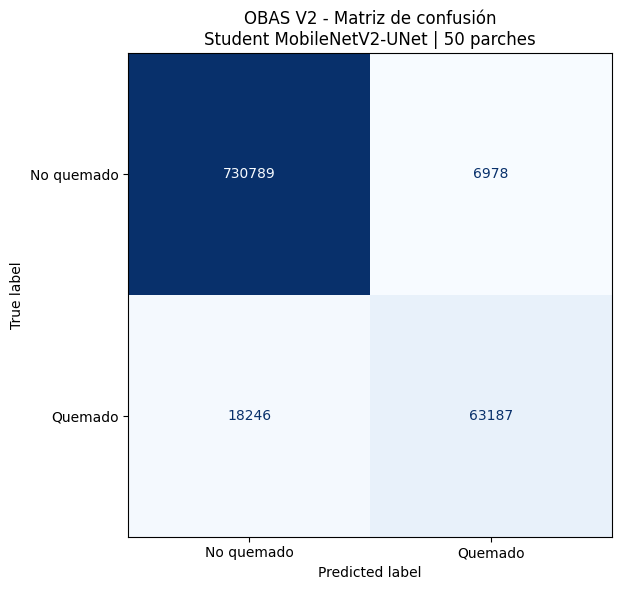


Métricas guardadas en: /kaggle/working/OBAS_V2_Auditoria_50/OBAS_V2_metricas_globales_50.csv
Gráfico guardado en: /kaggle/working/OBAS_V2_Auditoria_50/OBAS_V2_matriz_confusion_50.png


In [60]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    jaccard_score,
    accuracy_score,
    ConfusionMatrixDisplay
)

UMBRAL = 0.5

reales_globales = []
predichos_globales = []

print("=== EVALUACIÓN GLOBAL DE LOS 50 PARCHES ===")

for numero, fila in enumerate(
    df_50_nuevos.itertuples(), start=1
):
    imagen = np.load(
        fila.Ruta_imagen,
        allow_pickle=False
    )

    mascara_real = np.load(
        fila.Ruta_mascara,
        allow_pickle=False
    ).astype(np.uint8)

    imagen = np.transpose(
        imagen, (1, 2, 0)
    ).astype(np.float32)

    probabilidades = modelo_student(
        imagen[np.newaxis, ...],
        training=False
    ).numpy()[0, :, :, 0]

    mascara_predicha = (
        probabilidades >= UMBRAL
    ).astype(np.uint8)

    reales_globales.append(mascara_real.ravel())
    predichos_globales.append(mascara_predicha.ravel())

# Unir todos los píxeles
y_real_50 = np.concatenate(reales_globales)
y_pred_50 = np.concatenate(predichos_globales)

# Matriz de confusión
matriz_50 = confusion_matrix(
    y_real_50,
    y_pred_50,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz_50.ravel()

# Métricas globales
metricas_50 = {
    "Precision": precision_score(
        y_real_50, y_pred_50, zero_division=0
    ),
    "Recall": recall_score(
        y_real_50, y_pred_50, zero_division=0
    ),
    "F1-score": f1_score(
        y_real_50, y_pred_50, zero_division=0
    ),
    "IoU": jaccard_score(
        y_real_50, y_pred_50, zero_division=0
    ),
    "Accuracy": accuracy_score(
        y_real_50, y_pred_50
    )
}

print("\nParches evaluados:", len(df_50_nuevos))
print("Píxeles evaluados:", len(y_real_50))

print("\n=== MATRIZ DE CONFUSIÓN ===")
print("Verdaderos negativos (TN):", tn)
print("Falsos positivos (FP):", fp)
print("Falsos negativos (FN):", fn)
print("Verdaderos positivos (TP):", tp)

print("\n=== MÉTRICAS GLOBALES ===")

for nombre, valor in metricas_50.items():
    print(f"{nombre}: {valor:.4f}")

# Guardar métricas
df_metricas_50 = pd.DataFrame([
    {
        "Modelo": "Student MobileNetV2-UNet",
        "Parches": 50,
        "Pixeles": len(y_real_50),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        **metricas_50
    }
])

ruta_metricas = (
    SALIDA / "OBAS_V2_metricas_globales_50.csv"
)

df_metricas_50.to_csv(
    ruta_metricas,
    index=False
)

# Visualizar matriz de confusión
fig, ax = plt.subplots(figsize=(7, 6))

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_50,
    display_labels=["No quemado", "Quemado"]
)

visualizacion.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "OBAS V2 - Matriz de confusión\n"
    "Student MobileNetV2-UNet | 50 parches"
)

plt.tight_layout()

ruta_imagen = (
    SALIDA / "OBAS_V2_matriz_confusion_50.png"
)

plt.savefig(
    ruta_imagen,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nMétricas guardadas en:", ruta_metricas)
print("Gráfico guardado en:", ruta_imagen)


### Paso 12.9. Análisis de errores en los 50 parches

Se identifican los parches con peor desempeño de
segmentación, diferenciando falsos negativos, falsos
positivos y errores de delimitación.

Se prestará especial atención a las imágenes que
contienen áreas quemadas reales que el modelo no detecta.

Los resultados permitirán seleccionar casos para el
análisis visual y el informe de auditoría.

In [61]:

import pandas as pd
import numpy as np

df_errores_50 = df_resultados_50.copy()

# Clasificación de cada resultado
def clasificar_error(fila):

    real = fila["pixeles_quemados_reales"]
    pred = fila["pixeles_quemados_predichos"]

    if real == 0 and pred == 0:
        return "Sin quema - correcto"

    if real > 0 and pred == 0:
        return "Quema no detectada"

    if real == 0 and pred > 0:
        return "Falsa alarma"

    return "Segmentacion parcial"

df_errores_50["tipo_resultado"] = (
    df_errores_50.apply(clasificar_error, axis=1)
)

print("=== TIPOS DE RESULTADO ===")
print(df_errores_50["tipo_resultado"].value_counts())

# Analizar solo parches que realmente contienen quema
df_con_quema = df_errores_50[
    df_errores_50["pixeles_quemados_reales"] > 0
].copy()

df_peores_50 = (
    df_con_quema
    .sort_values(["f1", "recall"], ascending=True)
    .head(10)
)

print("\n=== 10 PARCHES CON QUEMA Y MENOR F1 ===")

display(
    df_peores_50[
        [
            "archivo",
            "zona",
            "tipo_resultado",
            "pixeles_quemados_reales",
            "pixeles_quemados_predichos",
            "precision",
            "recall",
            "f1",
            "iou"
        ]
    ]
)

# Casos sin quema
df_sin_quema = df_errores_50[
    df_errores_50["pixeles_quemados_reales"] == 0
].copy()

falsas_alarmas = df_sin_quema[
    df_sin_quema["pixeles_quemados_predichos"] > 0
]

print("\n=== FALSAS ALARMAS EN PARCHES SIN QUEMA ===")
print("Cantidad:", len(falsas_alarmas))

if len(falsas_alarmas) > 0:
    display(
        falsas_alarmas[
            [
                "archivo",
                "zona",
                "pixeles_quemados_predichos",
                "confianza"
            ]
        ]
    )

# Guardar análisis
ruta_errores = (
    SALIDA / "OBAS_V2_analisis_errores_50.csv"
)

df_errores_50.to_csv(
    ruta_errores,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo guardado:", ruta_errores)


=== TIPOS DE RESULTADO ===
tipo_resultado
Sin quema - correcto    22
Segmentacion parcial    20
Quema no detectada       7
Falsa alarma             1
Name: count, dtype: int64

=== 10 PARCHES CON QUEMA Y MENOR F1 ===


,archivo,zona,tipo_resultado,pixeles_quemados_reales,pixeles_quemados_predichos,precision,recall,f1,iou
2,OBAS_zone1_001510.npy,OBAS_zone1,Quema no detectada,1,0,0.0000,0.0000,0.0000,0.0000
9,OBAS_zone1_003273.npy,OBAS_zone1,Quema no detectada,2,0,0.0000,0.0000,0.0000,0.0000
13,OBAS_zone1_002917.npy,OBAS_zone1,Quema no detectada,41,0,0.0000,0.0000,0.0000,0.0000
25,OBAS_zone3_001966.npy,OBAS_zone3,Quema no detectada,1,0,0.0000,0.0000,0.0000,0.0000
30,OBAS_zone3_000545.npy,OBAS_zone3,Quema no detectada,17,0,0.0000,0.0000,0.0000,0.0000
34,OBAS_zone3_003269.npy,OBAS_zone3,Quema no detectada,2,0,0.0000,0.0000,0.0000,0.0000
46,CEMS_AOI01_01_000020.npy,CEMS_AOI01_01,Quema no detectada,10317,0,0.0000,0.0000,0.0000,0.0000
33,OBAS_zone3_001205.npy,OBAS_zone3,Segmentacion parcial,63,11,0.7273,0.1270,0.2162,0.1212
28,OBAS_zone3_000645.npy,OBAS_zone3,Segmentacion parcial,49,16,0.9375,0.3061,0.4615,0.3000
32,OBAS_zone3_001079.npy,OBAS_zone3,Segmentacion parcial,62,66,0.5000,0.5323,0.5156,0.3474



=== FALSAS ALARMAS EN PARCHES SIN QUEMA ===
Cantidad: 1


,archivo,zona,pixeles_quemados_predichos,confianza
12,OBAS_zone1_002662.npy,OBAS_zone1,1,0.9999



Archivo guardado: /kaggle/working/OBAS_V2_Auditoria_50/OBAS_V2_analisis_errores_50.csv


### Paso 12.10. Visualización de errores de segmentación

Se seleccionan diez parches con los menores valores
de F1-score entre aquellos que contienen quema real.

Para cada parche se comparan la imagen satelital,
la máscara real, la máscara predicha y un mapa de errores.

Los falsos negativos representan píxeles quemados
que el modelo no detectó.

Los falsos positivos representan píxeles no quemados
que el modelo identificó incorrectamente como quemados.

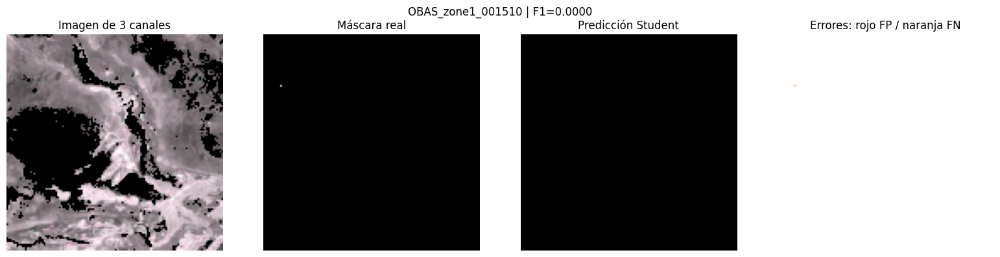

Caso 1/10 guardado: error_01_OBAS_zone1_001510.png


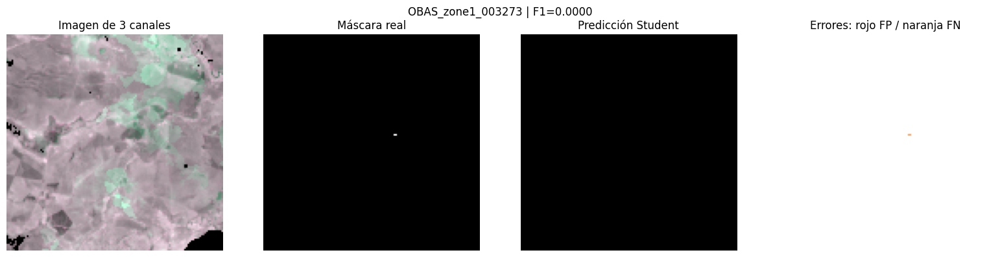

Caso 2/10 guardado: error_02_OBAS_zone1_003273.png


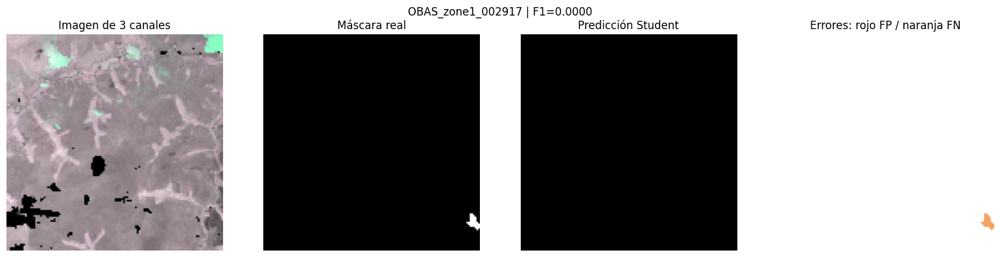

Caso 3/10 guardado: error_03_OBAS_zone1_002917.png


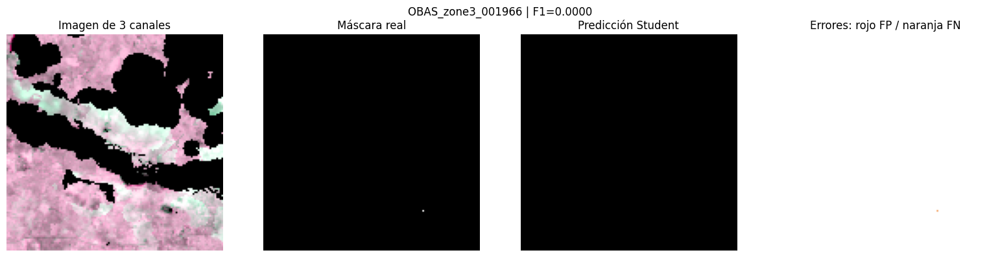

Caso 4/10 guardado: error_04_OBAS_zone3_001966.png


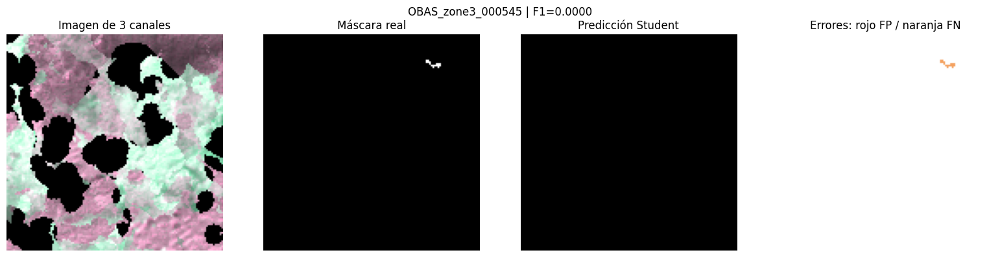

Caso 5/10 guardado: error_05_OBAS_zone3_000545.png


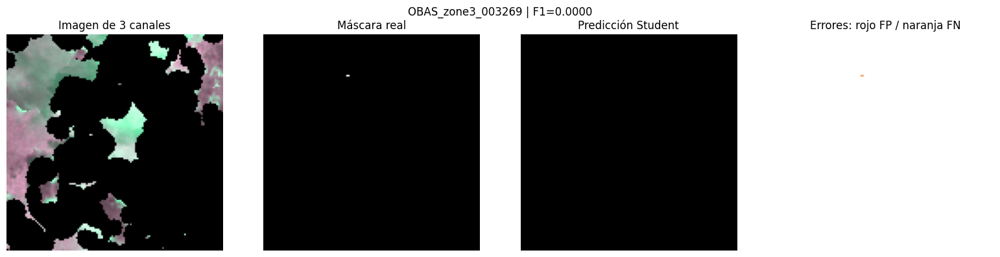

Caso 6/10 guardado: error_06_OBAS_zone3_003269.png


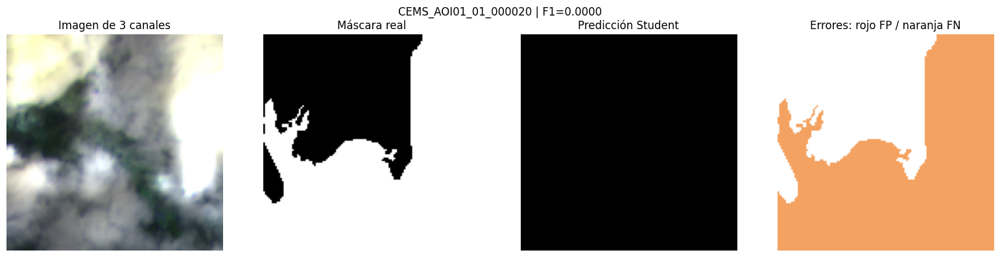

Caso 7/10 guardado: error_07_CEMS_AOI01_01_000020.png


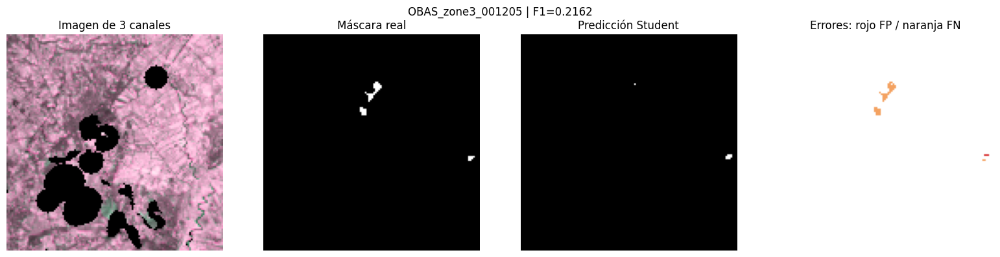

Caso 8/10 guardado: error_08_OBAS_zone3_001205.png


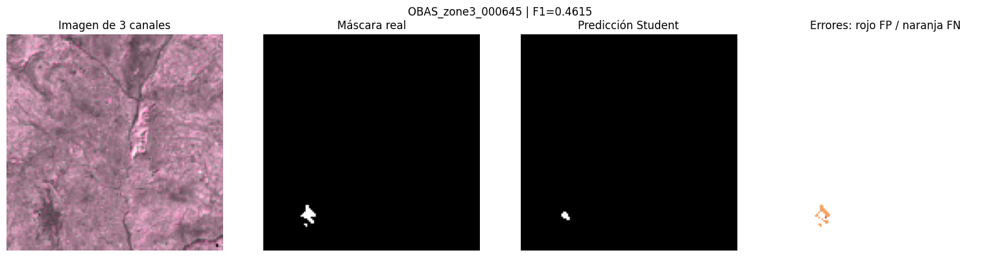

Caso 9/10 guardado: error_09_OBAS_zone3_000645.png


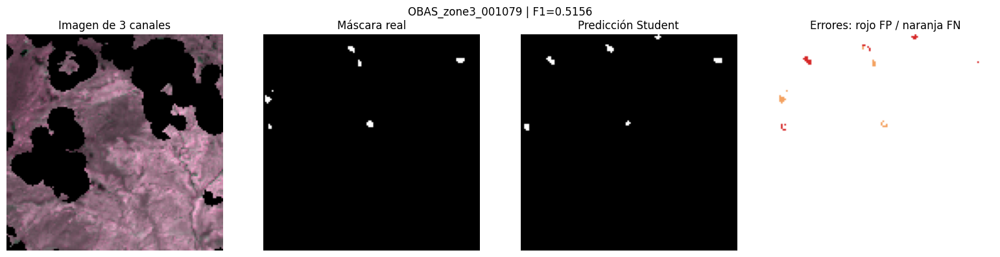

Caso 10/10 guardado: error_10_OBAS_zone3_001079.png

Visualizaciones completadas.
Carpeta: /kaggle/working/OBAS_V2_Auditoria_50/comparaciones_errores


In [62]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

UMBRAL = 0.5

CARPETA_FIGURAS = (
    SALIDA / "comparaciones_errores"
)
CARPETA_FIGURAS.mkdir(
    parents=True, exist_ok=True
)

# Seleccionar los diez casos con menor F1
casos = df_peores_50.head(10)

for numero, fila_error in enumerate(
    casos.itertuples(), start=1
):
    nombre = Path(fila_error.archivo).stem

    # Buscar las rutas originales
    seleccion = df_50_nuevos[
        df_50_nuevos["Parche"] == nombre
    ]

    if seleccion.empty:
        print("No encontrado:", nombre)
        continue

    registro = seleccion.iloc[0]

    imagen = np.load(
        registro["Ruta_imagen"],
        allow_pickle=False
    )

    mascara_real = np.load(
        registro["Ruta_mascara"],
        allow_pickle=False
    ).astype(np.uint8)

    imagen = np.transpose(
        imagen, (1, 2, 0)
    ).astype(np.float32)

    probabilidades = modelo_student(
        imagen[np.newaxis, ...],
        training=False
    ).numpy()[0, :, :, 0]

    mascara_predicha = (
        probabilidades >= UMBRAL
    ).astype(np.uint8)

    # Mapa de errores:
    # 0 = correcto
    # 1 = falso positivo
    # 2 = falso negativo
    mapa_errores = np.zeros(
        mascara_real.shape,
        dtype=np.uint8
    )

    mapa_errores[
        (mascara_real == 0) &
        (mascara_predicha == 1)
    ] = 1

    mapa_errores[
        (mascara_real == 1) &
        (mascara_predicha == 0)
    ] = 2

    fig, axes = plt.subplots(
        1, 4, figsize=(16, 4)
    )

    # Visualización de tres canales;
    # no se asume composición RGB natural.
    axes[0].imshow(
        np.clip(imagen, 0, 1)
    )
    axes[0].set_title("Imagen de 3 canales")

    axes[1].imshow(
        mascara_real,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Máscara real")

    axes[2].imshow(
        mascara_predicha,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Predicción Student")

    # Blanco: correcto
    # Rojo: falso positivo
    # Naranja: falso negativo
    from matplotlib.colors import ListedColormap

    colores = ListedColormap([
        "#FFFFFF",
        "#D62828",
        "#F4A261"
    ])

    axes[3].imshow(
        mapa_errores,
        cmap=colores,
        vmin=0,
        vmax=2
    )
    axes[3].set_title(
        "Errores: rojo FP / naranja FN"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"{nombre} | F1={fila_error.f1:.4f}",
        fontsize=12
    )

    plt.tight_layout()

    ruta_figura = (
        CARPETA_FIGURAS /
        f"error_{numero:02d}_{nombre}.png"
    )

    plt.savefig(
        ruta_figura,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(
        f"Caso {numero}/10 guardado:",
        ruta_figura.name
    )

print("\nVisualizaciones completadas.")
print("Carpeta:", CARPETA_FIGURAS)


### Paso 12.11. Verificación de independencia de la muestra

Se buscan registros de partición, manifiestos e identificadores
de imágenes utilizados durante el entrenamiento del modelo Student.

El objetivo es determinar si los 50 parches seleccionados
pertenecen a un conjunto independiente o si existe riesgo
de reutilización de datos de entrenamiento.

En ausencia de evidencia verificable, los resultados se
reportarán como evaluación exploratoria sobre el dataset.

In [63]:
from pathlib import Path
import pandas as pd

RAIZ = Path("/kaggle/input")

EXTENSIONES = {
    ".csv", ".json", ".jsonl", ".txt",
    ".yaml", ".yml", ".parquet"
}

PALABRAS = [
    "split", "train", "val", "test",
    "manifest", "indice", "index",
    "partition", "particion", "seed"
]

registros = []

for archivo in RAIZ.rglob("*"):

    if not archivo.is_file():
        continue

    if archivo.suffix.lower() not in EXTENSIONES:
        continue

    nombre = archivo.name.lower()

    if any(palabra in nombre for palabra in PALABRAS):
        registros.append({
            "archivo": archivo.name,
            "ruta": str(archivo),
            "tamano_kb": round(
                archivo.stat().st_size / 1024, 2
            )
        })

df_registros_entrenamiento = pd.DataFrame(registros)

print("=== POSIBLES REGISTROS DE ENTRENAMIENTO ===")
print("Archivos encontrados:", len(df_registros_entrenamiento))

if not df_registros_entrenamiento.empty:
    display(
        df_registros_entrenamiento
        .sort_values("archivo")
        .head(60)
    )
else:
    print(
        "No se encontraron manifiestos o registros "
        "identificables por nombre."
    )

=== POSIBLES REGISTROS DE ENTRENAMIENTO ===
Archivos encontrados: 22


,archivo,ruta,tamano_kb
5,PASO21_2_validacion_modelos.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,0.35
6,PASO21_3_comparacion_test_ABC.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,0.44
7,PASO21_3_comparacion_validacion_ABC.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,0.45
14,Student_Baseline_V2_training_log.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,12.55
9,Student_Baseline_V2_training_log.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,12.55
10,Student_KD_V2_training_log.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,12.53
15,Student_KD_V2_training_log.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,12.53
11,Teacher_V2_training_log.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,12.57
16,Teacher_V2_training_log.csv,/kaggle/input/datasets/santiagofallaamaya/obas...,12.57
2,comparacion_final_test.csv,/kaggle/input/datasets/santiagofallaamaya/entr...,0.37


### Paso 12.12. Revisión de los índices y particiones espaciales

Se inspeccionan los archivos patch_index.csv y
patch_index_spatial_v2.csv para identificar las
columnas que describen la procedencia y partición
de los parches satelitales.

El objetivo es verificar si los 50 parches seleccionados
pertenecen al conjunto de entrenamiento, validación
o prueba del modelo Student.

No se asumirá independencia de los datos sin evidencia.

In [64]:

from pathlib import Path
import pandas as pd

RAIZ = Path("/kaggle/input")

archivos_objetivo = [
    "patch_index.csv",
    "patch_index_spatial_v2.csv"
]

print("=== INSPECCIÓN DE ÍNDICES DEL DATASET ===")

for nombre in archivos_objetivo:

    rutas = sorted(RAIZ.rglob(nombre))

    print(f"\n{'=' * 65}")
    print("ARCHIVO:", nombre)
    print("Coincidencias:", len(rutas))

    for ruta in rutas:
        print("\nRuta completa:")
        print(ruta)

        try:
            df_indice = pd.read_csv(ruta)

            print("\nDimensiones:", df_indice.shape)

            print("\nCOLUMNAS:")
            for columna in df_indice.columns:
                print("-", columna)

            print("\nPRIMEROS 5 REGISTROS:")
            display(df_indice.head(5))

            print("\nPOSIBLES COLUMNAS DE PARTICIÓN:")

            columnas_particion = [
                c for c in df_indice.columns
                if any(
                    palabra in c.lower()
                    for palabra in [
                        "split", "partition",
                        "subset", "fold",
                        "train", "test",
                        "val", "spatial"
                    ]
                )
            ]

            if columnas_particion:
                for columna in columnas_particion:
                    print(f"\nColumna: {columna}")
                    print(
                        df_indice[columna]
                        .value_counts(dropna=False)
                        .head(20)
                    )
            else:
                print(
                    "No se encontraron columnas de "
                    "partición identificables por nombre."
                )

        except Exception as e:
            print("Error al leer:", e)


=== INSPECCIÓN DE ÍNDICES DEL DATASET ===

ARCHIVO: patch_index.csv
Coincidencias: 1

Ruta completa:
/kaggle/input/datasets/santiagofallaamaya/obas-v2-burned-area-segmentation/OBAS_V2_common_patches/common_patches/patch_index.csv

Dimensiones: (10200, 9)

COLUMNAS:
- patch_id
- source
- row
- col
- image_file
- mask_file
- burned_pixels
- burned_fraction
- has_burn

PRIMEROS 5 REGISTROS:


,patch_id,source,row,col,image_file,mask_file,burned_pixels,burned_fraction,has_burn
0,0,OBAS_zone1,0,0,OBAS_zone1/images/OBAS_zone1_000000.npy,OBAS_zone1/masks/OBAS_zone1_000000.npy,0,0.000000,0
1,1,OBAS_zone1,0,128,OBAS_zone1/images/OBAS_zone1_000001.npy,OBAS_zone1/masks/OBAS_zone1_000001.npy,0,0.000000,0
2,2,OBAS_zone1,0,256,OBAS_zone1/images/OBAS_zone1_000002.npy,OBAS_zone1/masks/OBAS_zone1_000002.npy,0,0.000000,0
3,3,OBAS_zone1,0,384,OBAS_zone1/images/OBAS_zone1_000003.npy,OBAS_zone1/masks/OBAS_zone1_000003.npy,22,0.001343,1
4,4,OBAS_zone1,0,512,OBAS_zone1/images/OBAS_zone1_000004.npy,OBAS_zone1/masks/OBAS_zone1_000004.npy,13,0.000793,1



POSIBLES COLUMNAS DE PARTICIÓN:
No se encontraron columnas de partición identificables por nombre.

ARCHIVO: patch_index_spatial_v2.csv
Coincidencias: 1

Ruta completa:
/kaggle/input/datasets/santiagofallaamaya/obas-v2-burned-area-segmentation/patch_index_spatial_v2.csv

Dimensiones: (10200, 12)

COLUMNAS:
- patch_id
- source
- row
- col
- image_file
- mask_file
- burned_pixels
- burned_fraction
- has_burn
- patch_row
- patch_col
- split

PRIMEROS 5 REGISTROS:


,patch_id,source,row,col,image_file,mask_file,burned_pixels,burned_fraction,has_burn,patch_row,patch_col,split
0,0,OBAS_zone1,0,0,OBAS_zone1/images/OBAS_zone1_000000.npy,OBAS_zone1/masks/OBAS_zone1_000000.npy,0,0.000000,0,0,0,train
1,1,OBAS_zone1,0,128,OBAS_zone1/images/OBAS_zone1_000001.npy,OBAS_zone1/masks/OBAS_zone1_000001.npy,0,0.000000,0,0,1,train
2,2,OBAS_zone1,0,256,OBAS_zone1/images/OBAS_zone1_000002.npy,OBAS_zone1/masks/OBAS_zone1_000002.npy,0,0.000000,0,0,2,train
3,3,OBAS_zone1,0,384,OBAS_zone1/images/OBAS_zone1_000003.npy,OBAS_zone1/masks/OBAS_zone1_000003.npy,22,0.001343,1,0,3,train
4,4,OBAS_zone1,0,512,OBAS_zone1/images/OBAS_zone1_000004.npy,OBAS_zone1/masks/OBAS_zone1_000004.npy,13,0.000793,1,0,4,train



POSIBLES COLUMNAS DE PARTICIÓN:

Columna: split
split
train    7016
test     1644
val      1540
Name: count, dtype: int64


### Paso 12.13. Cruce de los 50 parches con la partición espacial

Se cruzan los identificadores de los 50 parches evaluados
con el índice espacial del dataset OBAS V2.

El objetivo es determinar cuántos pertenecen a las
particiones train, val y test.

Este análisis permite identificar posibles riesgos de
contaminación de la evaluación por reutilización de
datos de entrenamiento.

In [65]:

from pathlib import Path
import pandas as pd

ruta_indice = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-burned-area-segmentation/"
    "patch_index_spatial_v2.csv"
)

df_indice_espacial = pd.read_csv(ruta_indice)

# Obtener el identificador desde la ruta relativa
df_indice_espacial["Parche"] = (
    df_indice_espacial["image_file"]
    .map(lambda ruta: Path(str(ruta)).stem)
)

# Comprobar identificadores únicos
assert df_indice_espacial["Parche"].is_unique

# Cruzar los 50 parches con el índice espacial
df_cruce_50 = df_50_nuevos.merge(
    df_indice_espacial[
        ["Parche", "split", "burned_pixels"]
    ],
    on="Parche",
    how="left",
    validate="one_to_one"
)

print("=== VERIFICACIÓN DE PARTICIÓN ESPACIAL ===")
print("Parches evaluados:", len(df_cruce_50))

print("\n=== DISTRIBUCIÓN DE LOS 50 PARCHES ===")
print(
    df_cruce_50["split"]
    .value_counts(dropna=False)
)

print("\n=== DISTRIBUCIÓN POR ZONA ===")
display(
    pd.crosstab(
        df_cruce_50["Zona"],
        df_cruce_50["split"],
        dropna=False
    )
)

print("\n=== PARCHES SIN COINCIDENCIA ===")
print(df_cruce_50["split"].isna().sum())

print("\n=== PARCHES DE TEST ===")
df_test_actuales = df_cruce_50[
    df_cruce_50["split"] == "test"
]

display(
    df_test_actuales[
        ["Zona", "Parche", "split", "burned_pixels"]
    ]
)

# Guardar auditoría de procedencia
ruta_cruce = (
    SALIDA / "OBAS_V2_particiones_50_actuales.csv"
)

df_cruce_50.to_csv(
    ruta_cruce,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo guardado:", ruta_cruce)


=== VERIFICACIÓN DE PARTICIÓN ESPACIAL ===
Parches evaluados: 50

=== DISTRIBUCIÓN DE LOS 50 PARCHES ===
split
train    37
test      7
val       6
Name: count, dtype: int64

=== DISTRIBUCIÓN POR ZONA ===


split,test,train,val
Zona,,,
CEMS_AOI01_01,3,5,2
OBAS_zone1,2,12,1
OBAS_zone2,0,8,2
OBAS_zone3,2,12,1



=== PARCHES SIN COINCIDENCIA ===
0

=== PARCHES DE TEST ===


,Zona,Parche,split,burned_pixels
7,OBAS_zone1,OBAS_zone1_001932,test,17
13,OBAS_zone1,OBAS_zone1_002917,test,41
28,OBAS_zone3,OBAS_zone3_000645,test,49
35,OBAS_zone3,OBAS_zone3_000992,test,0
43,CEMS_AOI01_01,CEMS_AOI01_01_000052,test,15259
45,CEMS_AOI01_01,CEMS_AOI01_01_000023,test,5770
46,CEMS_AOI01_01,CEMS_AOI01_01_000020,test,10317



Archivo guardado: /kaggle/working/OBAS_V2_Auditoria_50/OBAS_V2_particiones_50_actuales.csv


### Paso 12.14. Disponibilidad de parches de prueba espacial

Se analiza la partición test del índice espacial
OBAS V2 para determinar cuántos parches están
disponibles por zona.

También se identifica la cantidad de parches con
y sin áreas quemadas reales.

El objetivo es preparar una muestra de 50 parches
exclusivamente de test, evitando utilizar datos
clasificados como entrenamiento o validación.

In [66]:

import pandas as pd

# Utilizar el índice espacial ya cargado
df_test_disponibles = df_indice_espacial[
    df_indice_espacial["split"] == "test"
].copy()

print("=== DISPONIBILIDAD DE PARCHES TEST ===")

print(
    "Total de parches test:",
    len(df_test_disponibles)
)

print("\n=== PARCHES TEST POR ZONA ===")

resumen_test = (
    df_test_disponibles
    .groupby("source")
    .agg(
        total=("patch_id", "count"),
        con_quema=("has_burn", "sum")
    )
    .reset_index()
)

resumen_test["sin_quema"] = (
    resumen_test["total"] -
    resumen_test["con_quema"]
)

display(resumen_test)

print("\n=== DISTRIBUCIÓN GLOBAL ===")

print(
    "Con quema:",
    int(df_test_disponibles["has_burn"].sum())
)

print(
    "Sin quema:",
    int(
        (df_test_disponibles["has_burn"] == 0).sum()
    )
)

print("\n=== PARCHES TEST YA EVALUADOS ===")

parches_anteriores = set(
    df_50_nuevos["Parche"]
)

df_test_disponibles["evaluado_en_50"] = (
    df_test_disponibles["Parche"]
    .isin(parches_anteriores)
)

print(
    "Coinciden con los 50 anteriores:",
    int(df_test_disponibles["evaluado_en_50"].sum())
)

print(
    "Test no incluidos en los 50 anteriores:",
    int((~df_test_disponibles["evaluado_en_50"]).sum())
)


=== DISPONIBILIDAD DE PARCHES TEST ===
Total de parches test: 1644

=== PARCHES TEST POR ZONA ===


,source,total,con_quema,sin_quema
0,CEMS_AOI01_01,12,8,4
1,OBAS_zone1,704,364,340
2,OBAS_zone2,416,151,265
3,OBAS_zone3,512,209,303



=== DISTRIBUCIÓN GLOBAL ===
Con quema: 732
Sin quema: 912

=== PARCHES TEST YA EVALUADOS ===
Coinciden con los 50 anteriores: 7
Test no incluidos en los 50 anteriores: 1637


### Paso 12.15. Selección de 50 parches de prueba espacial

Se seleccionan 50 parches pertenecientes exclusivamente
a la partición test del índice espacial OBAS V2.

La selección incluye las cuatro zonas del dataset y
ejemplos con y sin áreas quemadas.

Se excluyen los 50 parches de la evaluación exploratoria
anterior y se utiliza una semilla fija para garantizar
la reproducibilidad del muestreo.

Esta selección evita mezclar las particiones train,
val y test. La independencia respecto al entrenamiento
del modelo Student deberá confirmarse con sus registros.

In [67]:

from pathlib import Path
import pandas as pd

# Dataset original
BASE_PARCHES = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-burned-area-segmentation/"
    "OBAS_V2_common_patches/common_patches"
)

# Distribución propuesta:
# zona: (con_quema, sin_quema)
DISTRIBUCION_TEST = {
    "OBAS_zone1": (8, 8),
    "OBAS_zone2": (7, 7),
    "OBAS_zone3": (6, 6),
    "CEMS_AOI01_01": (5, 3)
}

# Filtrar únicamente test
df_candidatos = df_indice_espacial[
    df_indice_espacial["split"] == "test"
].copy()

# Excluir los 50 parches evaluados anteriormente
excluidos = set(df_50_nuevos["Parche"])

df_candidatos = df_candidatos[
    ~df_candidatos["Parche"].isin(excluidos)
].copy()

selecciones = []

for zona, (n_quema, n_sin_quema) in DISTRIBUCION_TEST.items():

    datos_zona = df_candidatos[
        df_candidatos["source"] == zona
    ]

    positivos = datos_zona[
        datos_zona["has_burn"] == 1
    ]

    negativos = datos_zona[
        datos_zona["has_burn"] == 0
    ]

    if len(positivos) < n_quema:
        raise ValueError(
            f"No hay suficientes positivos en {zona}"
        )

    if len(negativos) < n_sin_quema:
        raise ValueError(
            f"No hay suficientes negativos en {zona}"
        )

    muestra_positiva = positivos.sample(
        n=n_quema,
        random_state=2026
    )

    muestra_negativa = negativos.sample(
        n=n_sin_quema,
        random_state=2027
    )

    selecciones.extend([
        muestra_positiva,
        muestra_negativa
    ])

# Unir la muestra definitiva
df_50_test = pd.concat(
    selecciones,
    ignore_index=True
)

# Crear rutas absolutas
df_50_test["Ruta_imagen"] = (
    df_50_test["image_file"]
    .apply(lambda x: str(BASE_PARCHES / x))
)

df_50_test["Ruta_mascara"] = (
    df_50_test["mask_file"]
    .apply(lambda x: str(BASE_PARCHES / x))
)

# Verificaciones
assert len(df_50_test) == 50
assert df_50_test["Parche"].is_unique
assert (df_50_test["split"] == "test").all()

assert not df_50_test["Parche"].isin(excluidos).any()

assert df_50_test["Ruta_imagen"].apply(
    lambda x: Path(x).is_file()
).all()

assert df_50_test["Ruta_mascara"].apply(
    lambda x: Path(x).is_file()
).all()

# Guardar selección
SALIDA_TEST = Path(
    "/kaggle/working/OBAS_V2_Auditoria_50_TEST"
)

SALIDA_TEST.mkdir(
    parents=True,
    exist_ok=True
)

ruta_seleccion_test = (
    SALIDA_TEST / "seleccion_50_test_espacial.csv"
)

df_50_test.to_csv(
    ruta_seleccion_test,
    index=False,
    encoding="utf-8-sig"
)

print("=== SELECCIÓN DEFINITIVA DE TEST ===")
print("Total seleccionados:", len(df_50_test))

print("\n=== DISTRIBUCIÓN POR ZONA Y CLASE ===")

display(
    pd.crosstab(
        df_50_test["source"],
        df_50_test["has_burn"]
    ).rename(
        columns={
            0: "Sin quema",
            1: "Con quema"
        }
    )
)

print("\n=== VERIFICACIÓN DE PARTICIONES ===")
print(df_50_test["split"].value_counts())

print("\n=== VERIFICACIÓN DE DUPLICADOS ===")
print(
    "Repetidos de los 50 anteriores:",
    df_50_test["Parche"].isin(excluidos).sum()
)

print("\n=== PRIMEROS 10 PARCHES ===")

display(
    df_50_test[
        [
            "Parche",
            "source",
            "split",
            "burned_pixels"
        ]
    ].head(10)
)

print("\nArchivo guardado:", ruta_seleccion_test)


=== SELECCIÓN DEFINITIVA DE TEST ===
Total seleccionados: 50

=== DISTRIBUCIÓN POR ZONA Y CLASE ===


has_burn,Sin quema,Con quema
source,,
CEMS_AOI01_01,3,5
OBAS_zone1,8,8
OBAS_zone2,7,7
OBAS_zone3,6,6



=== VERIFICACIÓN DE PARTICIONES ===
split
test    50
Name: count, dtype: int64

=== VERIFICACIÓN DE DUPLICADOS ===
Repetidos de los 50 anteriores: 0

=== PRIMEROS 10 PARCHES ===


,Parche,source,split,burned_pixels
0,OBAS_zone1_001883,OBAS_zone1,test,139
1,OBAS_zone1_003023,OBAS_zone1,test,9
2,OBAS_zone1_002429,OBAS_zone1,test,5
3,OBAS_zone1_000105,OBAS_zone1,test,6
4,OBAS_zone1_002944,OBAS_zone1,test,27
5,OBAS_zone1_003534,OBAS_zone1,test,20
6,OBAS_zone1_002261,OBAS_zone1,test,269
7,OBAS_zone1_002326,OBAS_zone1,test,556
8,OBAS_zone1_000764,OBAS_zone1,test,0
9,OBAS_zone1_002502,OBAS_zone1,test,0



Archivo guardado: /kaggle/working/OBAS_V2_Auditoria_50_TEST/seleccion_50_test_espacial.csv


### Paso 12.20. Inferencia sobre 50 parches de prueba espacial

Se ejecuta el modelo Student MobileNetV2–UNet sobre
50 parches pertenecientes a la partición test del
índice espacial OBAS V2.

Se registran las predicciones, métricas de segmentación,
proporción de área quemada, confianza descriptiva y
tiempo de inferencia por parche.

Los resultados corresponden a una evaluación en Kaggle.
La independencia respecto al entrenamiento original
del modelo no pudo verificarse documentalmente.

Los tiempos registrados no representan el rendimiento
de la aplicación móvil.

In [72]:

import time
import numpy as np
import pandas as pd
from pathlib import Path

UMBRAL = 0.5

resultados_test = []
matrices_test = []

print("=== INFERENCIA STUDENT SOBRE 50 PARCHES TEST ===")

for i, fila in df_50_test.iterrows():

    # Cargar imagen y máscara
    imagen = np.load(fila["Ruta_imagen"]).astype(
        np.float32
    )

    mascara = np.load(fila["Ruta_mascara"])

    # Convertir de CHW a HWC
    if imagen.shape == (3, 128, 128):
        imagen = np.transpose(imagen, (1, 2, 0))

    assert imagen.shape == (128, 128, 3)
    assert mascara.shape == (128, 128)

    # Máscara binaria real
    y_real = (mascara > 0).astype(np.uint8)

    # Inferencia del modelo
    entrada = np.expand_dims(imagen, axis=0)

    inicio = time.perf_counter()

    probabilidad = modelo_student(
        entrada,
        training=False
    ).numpy()[0, :, :, 0]

    tiempo_ms = (
        time.perf_counter() - inicio
    ) * 1000

    # Predicción binaria
    y_pred = (
        probabilidad >= UMBRAL
    ).astype(np.uint8)

    # Matriz de confusión por píxel
    tp = int(np.sum((y_real == 1) & (y_pred == 1)))
    tn = int(np.sum((y_real == 0) & (y_pred == 0)))
    fp = int(np.sum((y_real == 0) & (y_pred == 1)))
    fn = int(np.sum((y_real == 1) & (y_pred == 0)))

    precision = (
        tp / (tp + fp)
        if tp + fp > 0 else 0.0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0 else 0.0
    )

    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn > 0 else 1.0
    )

    iou = (
        tp / (tp + fp + fn)
        if tp + fp + fn > 0 else 1.0
    )

    # Confianza descriptiva por píxel
    # No es una probabilidad calibrada de acierto
    confianza = float(
        np.mean(
            np.maximum(
                probabilidad,
                1 - probabilidad
            )
        )
    )

    resultados_test.append({
        "archivo": fila["Parche"] + ".npy",
        "zona": fila["source"],
        "split": fila["split"],
        "clase_real": int(y_real.any()),
        "prediccion": int(y_pred.any()),
        "confianza": confianza,
        "tiempo_respuesta_ms": tiempo_ms,
        "porcentaje_area_quemada": (
            100 * float(y_pred.mean())
        ),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "pixeles_quemados_reales": int(y_real.sum()),
        "pixeles_quemados_predichos": int(y_pred.sum()),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    })

    matrices_test.append([tn, fp, fn, tp])

    if (len(resultados_test) % 10) == 0:
        print(
            f"Procesados: {len(resultados_test)}/50"
        )

# Crear tabla
df_resultados_50_test = pd.DataFrame(
    resultados_test
)

# Guardar CSV
ruta_csv_test = (
    SALIDA_TEST /
    "S15_PruebaDataset_50_TEST_Galviz_Falla_Pena.csv"
)

df_resultados_50_test.to_csv(
    ruta_csv_test,
    index=False,
    encoding="utf-8-sig"
)

# Métricas globales por píxel
TN, FP, FN, TP = np.sum(
    np.array(matrices_test),
    axis=0
)

precision_global = (
    TP / (TP + FP)
    if TP + FP > 0 else 0.0
)

recall_global = (
    TP / (TP + FN)
    if TP + FN > 0 else 0.0
)

f1_global = (
    2 * TP / (2 * TP + FP + FN)
    if 2 * TP + FP + FN > 0 else 1.0
)

iou_global = (
    TP / (TP + FP + FN)
    if TP + FP + FN > 0 else 1.0
)

accuracy_global = (
    (TP + TN) / (TP + TN + FP + FN)
)

print("\n=== MÉTRICAS GLOBALES TEST ===")

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

print(f"Precision: {precision_global:.4f}")
print(f"Recall:    {recall_global:.4f}")
print(f"F1 / Dice: {f1_global:.4f}")
print(f"IoU:       {iou_global:.4f}")
print(f"Accuracy:  {accuracy_global:.4f}")

print("\n=== TIEMPOS DE INFERENCIA EN KAGGLE ===")

print(
    "Promedio (ms):",
    round(
        df_resultados_50_test[
            "tiempo_respuesta_ms"
        ].mean(),
        2
    )
)

print(
    "Máximo (ms):",
    round(
        df_resultados_50_test[
            "tiempo_respuesta_ms"
        ].max(),
        2
    )
)

print("\n=== PRIMEROS RESULTADOS ===")

display(df_resultados_50_test.head(10))

print("\nCSV guardado en:")
print(ruta_csv_test)


=== INFERENCIA STUDENT SOBRE 50 PARCHES TEST ===
Procesados: 10/50
Procesados: 20/50
Procesados: 30/50
Procesados: 40/50
Procesados: 50/50

=== MÉTRICAS GLOBALES TEST ===
TN: 746480
FP: 4195
FN: 19136
TP: 49389
Precision: 0.9217
Recall:    0.7207
F1 / Dice: 0.8089
IoU:       0.6792
Accuracy:  0.9715

=== TIEMPOS DE INFERENCIA EN KAGGLE ===
Promedio (ms): 253.31
Máximo (ms): 288.2

=== PRIMEROS RESULTADOS ===


,archivo,zona,split,clase_real,prediccion,confianza,tiempo_respuesta_ms,porcentaje_area_quemada,precision,recall,f1,iou,pixeles_quemados_reales,pixeles_quemados_predichos,TP,TN,FP,FN
0,OBAS_zone1_001883.npy,OBAS_zone1,test,1,1,0.999005,264.157170,0.793457,0.761538,0.712230,0.736059,0.582353,139,130,99,16214,31,40
1,OBAS_zone1_003023.npy,OBAS_zone1,test,1,1,0.999799,284.500826,0.061035,0.500000,0.555556,0.526316,0.357143,9,10,5,16370,5,4
2,OBAS_zone1_002429.npy,OBAS_zone1,test,1,1,0.999767,251.372726,0.006104,0.000000,0.000000,0.000000,0.000000,5,1,0,16378,1,5
3,OBAS_zone1_000105.npy,OBAS_zone1,test,1,0,1.000000,251.660332,0.000000,0.000000,0.000000,0.000000,0.000000,6,0,0,16378,0,6
4,OBAS_zone1_002944.npy,OBAS_zone1,test,1,1,0.999102,248.648868,0.311279,0.372549,0.703704,0.487179,0.322034,27,51,19,16325,32,8
5,OBAS_zone1_003534.npy,OBAS_zone1,test,1,1,0.999879,248.330948,0.134277,0.863636,0.950000,0.904762,0.826087,20,22,19,16361,3,1
6,OBAS_zone1_002261.npy,OBAS_zone1,test,1,1,0.998922,246.213550,1.898193,0.823151,0.951673,0.882759,0.790123,269,311,256,16060,55,13
7,OBAS_zone1_002326.npy,OBAS_zone1,test,1,1,0.997175,244.191688,3.796387,0.819936,0.917266,0.865874,0.763473,556,622,510,15716,112,46
8,OBAS_zone1_000764.npy,OBAS_zone1,test,0,0,0.999999,259.740681,0.000000,0.000000,0.000000,1.000000,1.000000,0,0,0,16384,0,0
9,OBAS_zone1_002502.npy,OBAS_zone1,test,0,0,0.999999,248.786670,0.000000,0.000000,0.000000,1.000000,1.000000,0,0,0,16384,0,0



CSV guardado en:
/kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_PruebaDataset_50_TEST_Galviz_Falla_Pena.csv


### Paso 12.21. Análisis de errores de segmentación

Se clasifican los resultados de los 50 parches de test
según la presencia de áreas quemadas reales y predichas.

Se identifican las detecciones correctas, las áreas
quemadas no detectadas, las falsas alarmas y los
casos de segmentación parcial.

También se examinan los diez parches con peor F1
entre aquellos que contienen áreas quemadas reales.

El objetivo es identificar las principales limitaciones
del modelo Student para documentarlas en la auditoría.

In [73]:

import pandas as pd

df_analisis_test = df_resultados_50_test.copy()

def clasificar_resultado(fila):

    real = int(fila["clase_real"])
    pred = int(fila["prediccion"])
    tp = int(fila["TP"])

    if real == 0 and pred == 0:
        return "Sin quema correctamente"

    if real == 0 and pred == 1:
        return "Falsa alarma"

    if real == 1 and pred == 0:
        return "Quema no detectada"

    if real == 1 and pred == 1 and tp == 0:
        return "Prediccion sin superposicion"

    return "Quema detectada parcialmente"

df_analisis_test["tipo_resultado"] = (
    df_analisis_test.apply(
        clasificar_resultado,
        axis=1
    )
)

print("=== CLASIFICACIÓN DE LOS 50 PARCHES ===")

display(
    df_analisis_test["tipo_resultado"]
    .value_counts()
    .rename_axis("Tipo de resultado")
    .reset_index(name="Cantidad")
)

print("\n=== DISTRIBUCIÓN DE ERRORES POR ZONA ===")

display(
    pd.crosstab(
        df_analisis_test["zona"],
        df_analisis_test["tipo_resultado"]
    )
)

print("\n=== DIEZ PEORES CASOS CON QUEMA REAL ===")

df_peores_test = (
    df_analisis_test[
        df_analisis_test["clase_real"] == 1
    ]
    .sort_values(
        ["f1", "pixeles_quemados_reales"],
        ascending=[True, False]
    )
    .head(10)
)

display(
    df_peores_test[
        [
            "archivo",
            "zona",
            "tipo_resultado",
            "pixeles_quemados_reales",
            "pixeles_quemados_predichos",
            "TP",
            "FP",
            "FN",
            "f1",
            "iou",
            "confianza"
        ]
    ]
)

print("\n=== RESUMEN DE FALSOS NEGATIVOS ===")

print(
    "Parches con quema completamente omitida:",
    int(
        (
            df_analisis_test["tipo_resultado"]
            == "Quema no detectada"
        ).sum()
    )
)

print(
    "Píxeles quemados no detectados:",
    int(df_analisis_test["FN"].sum())
)

# Guardar análisis
ruta_errores_test = (
    SALIDA_TEST /
    "OBAS_V2_analisis_errores_50_TEST.csv"
)

df_analisis_test.to_csv(
    ruta_errores_test,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo guardado:")
print(ruta_errores_test)


=== CLASIFICACIÓN DE LOS 50 PARCHES ===


,Tipo de resultado,Cantidad
0,Sin quema correctamente,23
1,Quema detectada parcialmente,20
2,Quema no detectada,5
3,Prediccion sin superposicion,1
4,Falsa alarma,1



=== DISTRIBUCIÓN DE ERRORES POR ZONA ===


tipo_resultado,Falsa alarma,Prediccion sin superposicion,Quema detectada parcialmente,Quema no detectada,Sin quema correctamente
zona,,,,,
CEMS_AOI01_01,0,0,5,0,3
OBAS_zone1,0,1,6,1,8
OBAS_zone2,0,0,5,2,7
OBAS_zone3,1,0,4,2,5



=== DIEZ PEORES CASOS CON QUEMA REAL ===


,archivo,zona,tipo_resultado,pixeles_quemados_reales,pixeles_quemados_predichos,TP,FP,FN,f1,iou,confianza
16,OBAS_zone2_000583.npy,OBAS_zone2,Quema no detectada,7,0,0,0,7,0.000000,0.000000,0.999995
3,OBAS_zone1_000105.npy,OBAS_zone1,Quema no detectada,6,0,0,0,6,0.000000,0.000000,1.000000
18,OBAS_zone2_000712.npy,OBAS_zone2,Quema no detectada,6,0,0,0,6,0.000000,0.000000,0.999999
2,OBAS_zone1_002429.npy,OBAS_zone1,Prediccion sin superposicion,5,1,0,1,5,0.000000,0.000000,0.999767
30,OBAS_zone3_000228.npy,OBAS_zone3,Quema no detectada,1,0,0,0,1,0.000000,0.000000,0.999999
35,OBAS_zone3_000267.npy,OBAS_zone3,Quema no detectada,1,0,0,0,1,0.000000,0.000000,1.000000
31,OBAS_zone3_000349.npy,OBAS_zone3,Quema detectada parcialmente,28,8,7,1,21,0.388889,0.241379,0.999814
17,OBAS_zone2_000950.npy,OBAS_zone2,Quema detectada parcialmente,3,6,2,4,1,0.444444,0.285714,0.999857
4,OBAS_zone1_002944.npy,OBAS_zone1,Quema detectada parcialmente,27,51,19,32,8,0.487179,0.322034,0.999102
44,CEMS_AOI01_01_000060.npy,CEMS_AOI01_01,Quema detectada parcialmente,12587,4992,4406,586,8181,0.501280,0.334472,0.952577



=== RESUMEN DE FALSOS NEGATIVOS ===
Parches con quema completamente omitida: 5
Píxeles quemados no detectados: 19136

Archivo guardado:
/kaggle/working/OBAS_V2_Auditoria_50_TEST/OBAS_V2_analisis_errores_50_TEST.csv


### Paso 12.22. Evidencia visual de errores de segmentación

Se generan comparaciones visuales entre imágenes satelitales,
máscaras reales y predicciones del modelo Student.

Se seleccionan casos de omisión completa, predicción sin
superposición, segmentación parcial y detecciones de referencia.

Los mapas de error permiten distinguir falsos positivos y
falsos negativos para explicar las limitaciones del modelo.

Las imágenes se guardan como evidencia para el informe final.

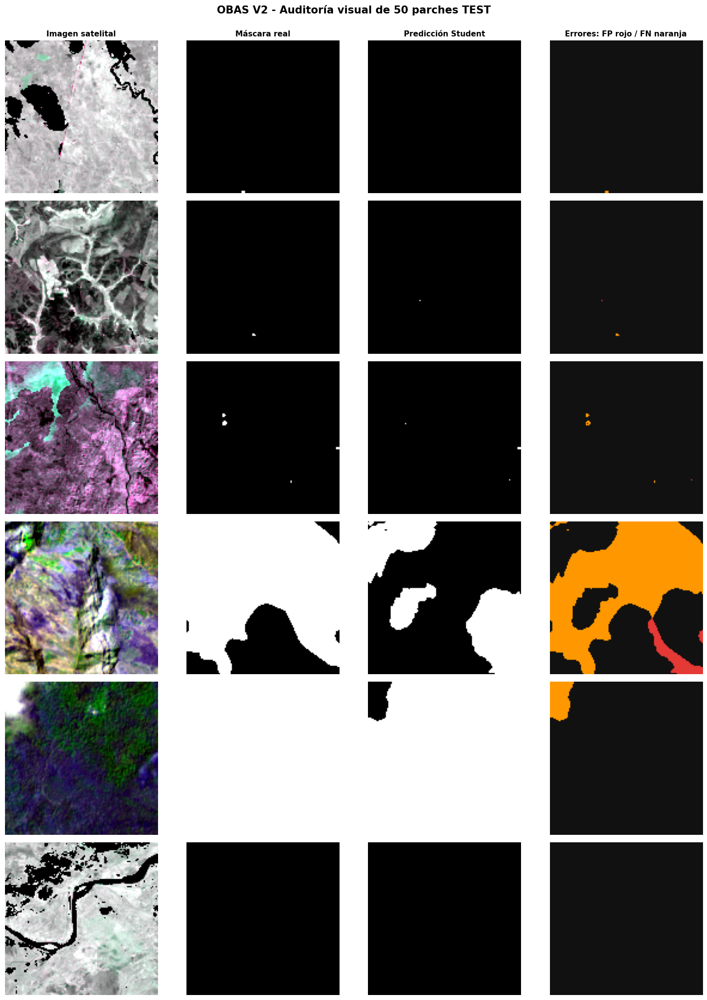

=== FIGURA GENERADA ===
Casos: 6
Archivo: /kaggle/working/OBAS_V2_Auditoria_50_TEST/comparaciones_visuales/S15_comparacion_6_casos_TEST.png

=== CASOS INCLUIDOS ===


,archivo,zona,tipo_resultado,f1,TP,FP,FN
2,OBAS_zone1_002429.npy,OBAS_zone1,Prediccion sin superposicion,0.000000,0,1,5
3,OBAS_zone1_000105.npy,OBAS_zone1,Quema no detectada,0.000000,0,0,6
8,OBAS_zone1_000764.npy,OBAS_zone1,Sin quema correctamente,1.000000,0,0,0
31,OBAS_zone3_000349.npy,OBAS_zone3,Quema detectada parcialmente,0.388889,7,1,21
44,CEMS_AOI01_01_000060.npy,CEMS_AOI01_01,Quema detectada parcialmente,0.501280,4406,586,8181
46,CEMS_AOI01_01_000029.npy,CEMS_AOI01_01,Quema detectada parcialmente,0.983875,15864,0,520


In [74]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CARPETA_FIGURAS = (
    SALIDA_TEST / "comparaciones_visuales"
)
CARPETA_FIGURAS.mkdir(
    parents=True,
    exist_ok=True
)

# Casos seleccionados por su comportamiento
casos = [
    "OBAS_zone1_000105.npy",
    "OBAS_zone1_002429.npy",
    "OBAS_zone3_000349.npy",
    "CEMS_AOI01_01_000060.npy"
]

# Agregar un caso con quema bien segmentada
candidatos_buenos = df_analisis_test[
    (df_analisis_test["clase_real"] == 1) &
    (df_analisis_test["TP"] > 0)
].sort_values("f1", ascending=False)

for nombre in candidatos_buenos["archivo"]:
    if nombre not in casos:
        casos.append(nombre)
        break

# Agregar un caso correctamente negativo
candidatos_negativos = df_analisis_test[
    (df_analisis_test["clase_real"] == 0) &
    (df_analisis_test["prediccion"] == 0)
]

if not candidatos_negativos.empty:
    casos.append(
        candidatos_negativos.iloc[0]["archivo"]
    )

assert len(casos) == 6, (
    f"Se esperaban 6 casos, se obtuvieron {len(casos)}"
)

fig, ejes = plt.subplots(
    len(casos), 4,
    figsize=(15, 3.4 * len(casos)),
    squeeze=False
)

for i, nombre in enumerate(casos):

    fila = df_analisis_test[
        df_analisis_test["archivo"] == nombre
    ].iloc[0]

    parche = Path(nombre).stem

    registro = df_50_test[
        df_50_test["Parche"] == parche
    ].iloc[0]

    imagen = np.load(
        registro["Ruta_imagen"]
    ).astype(np.float32)

    mascara = np.load(
        registro["Ruta_mascara"]
    )

    if imagen.shape == (3, 128, 128):
        imagen = np.transpose(
            imagen, (1, 2, 0)
        )

    real = (mascara > 0).astype(np.uint8)

    probabilidades = modelo_student(
        imagen[np.newaxis, ...],
        training=False
    ).numpy()[0, :, :, 0]

    pred = (
        probabilidades >= 0.5
    ).astype(np.uint8)

    # Solo para visualización:
    # contraste por canal, sin modificar
    # la entrada utilizada por el modelo.
    visual = imagen.copy()

    for canal in range(3):
        valores = visual[:, :, canal]
        minimo = np.percentile(valores, 2)
        maximo = np.percentile(valores, 98)

        visual[:, :, canal] = np.clip(
            (valores - minimo) /
            max(maximo - minimo, 1e-8),
            0, 1
        )

    # Mapa de errores:
    # 0 = correcto, 1 = FP, 2 = FN
    errores = np.zeros_like(real)

    errores[(real == 0) & (pred == 1)] = 1
    errores[(real == 1) & (pred == 0)] = 2

    ejes[i, 0].imshow(visual)
    ejes[i, 1].imshow(real, cmap="gray", vmin=0, vmax=1)
    ejes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)

    # Fondo negro, FP rojo y FN naranja
    from matplotlib.colors import ListedColormap

    mapa_colores = ListedColormap([
        "#111111", "#e53935", "#ff9800"
    ])

    ejes[i, 3].imshow(
        errores,
        cmap=mapa_colores,
        vmin=0,
        vmax=2
    )

    ejes[i, 0].set_ylabel(
        f"{parche}\nF1={fila['f1']:.3f}",
        fontsize=9
    )

    for j in range(4):
        ejes[i, j].axis("off")

titulos = [
    "Imagen satelital",
    "Máscara real",
    "Predicción Student",
    "Errores: FP rojo / FN naranja"
]

for j, titulo in enumerate(titulos):
    ejes[0, j].set_title(
        titulo,
        fontsize=11,
        fontweight="bold"
    )

plt.suptitle(
    "OBAS V2 - Auditoría visual de 50 parches TEST",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

ruta_figura = (
    CARPETA_FIGURAS /
    "S15_comparacion_6_casos_TEST.png"
)

plt.savefig(
    ruta_figura,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("=== FIGURA GENERADA ===")
print("Casos:", len(casos))
print("Archivo:", ruta_figura)

print("\n=== CASOS INCLUIDOS ===")

display(
    df_analisis_test[
        df_analisis_test["archivo"].isin(casos)
    ][
        [
            "archivo",
            "zona",
            "tipo_resultado",
            "f1",
            "TP",
            "FP",
            "FN"
        ]
    ]
)


### Paso 12.23. Consolidación de resultados de auditoría

Se consolidan las métricas globales, la matriz de
confusión, los errores por imagen y la latencia
de inferencia del Student MobileNetV2–UNet.

Se documenta el origen de los 50 parches y la
limitación de trazabilidad del entrenamiento original.

Los resultados se almacenan en formatos CSV y JSON
para facilitar su incorporación al informe final
de la semana 15.

In [76]:

import json
import pandas as pd
from datetime import datetime, timezone

# Consolidar matriz de confusión
tp = int(df_resultados_50_test["TP"].sum())
tn = int(df_resultados_50_test["TN"].sum())
fp = int(df_resultados_50_test["FP"].sum())
fn = int(df_resultados_50_test["FN"].sum())

total = tp + tn + fp + fn

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * tp / (2 * tp + fp + fn)
    if 2 * tp + fp + fn else 0.0
)
iou = (
    tp / (tp + fp + fn)
    if tp + fp + fn else 0.0
)
accuracy = (tp + tn) / total if total else 0.0

conteos = (
    df_analisis_test["tipo_resultado"]
    .value_counts()
    .to_dict()
)

resumen = {
    "proyecto": "OBAS V2",
    "auditoria": "Semana 15",
    "modelo": "Student_MobileNetV2_UNet_V2_baseline_best.keras",
    "fecha_generacion_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "numero_parches": len(df_resultados_50_test),
    "tamano_parche": [128, 128],
    "umbral_segmentacion": 0.5,
    "indice_seleccion": "patch_index_spatial_v2.csv",
    "particion_declarada": "test",
    "independencia_entrenamiento_verificada": False,
    "limitacion": (
        "No se dispone de evidencia concluyente de "
        "que el modelo Student original se entrenó "
        "con la misma partición espacial. "
        "La evaluación no equivale a validación "
        "externa ni a prueba en aplicación móvil."
    ),
    "matriz_confusion_pixeles": {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    },
    "metricas_globales_pixeles": {
        "precision": precision,
        "recall": recall,
        "f1_dice": f1,
        "iou": iou,
        "accuracy": accuracy
    },
    "clasificacion_parches": {
        str(k): int(v)
        for k, v in conteos.items()
    },
    "inferencia_kaggle_ms": {
        "promedio": float(
            df_resultados_50_test[
                "tiempo_respuesta_ms"
            ].mean()
        ),
        "mediana": float(
            df_resultados_50_test[
                "tiempo_respuesta_ms"
            ].median()
        ),
        "maximo": float(
            df_resultados_50_test[
                "tiempo_respuesta_ms"
            ].max()
        )
    },
    "interpretacion_confianza": (
        "Promedio de max(p, 1-p) por pixel. "
        "No representa confianza calibrada "
        "de la prediccion completa."
    )
}

# Guardar JSON
ruta_json = (
    SALIDA_TEST /
    "S15_resumen_auditoria_50_TEST.json"
)

with open(
    ruta_json,
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        resumen,
        archivo,
        indent=2,
        ensure_ascii=False
    )

# Guardar CSV de métricas
df_metricas = pd.DataFrame([
    {
        "modelo": resumen["modelo"],
        "parches": resumen["numero_parches"],
        "precision": precision,
        "recall": recall,
        "f1_dice": f1,
        "iou": iou,
        "accuracy": accuracy,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "latencia_promedio_ms": resumen[
            "inferencia_kaggle_ms"
        ]["promedio"]
    }
])

ruta_metricas = (
    SALIDA_TEST /
    "S15_metricas_globales_50_TEST.csv"
)

df_metricas.to_csv(
    ruta_metricas,
    index=False,
    encoding="utf-8-sig"
)

print("=== RESUMEN DEFINITIVO DE AUDITORÍA ===")
display(df_metricas)

print("\n=== CLASIFICACIÓN DE RESULTADOS ===")
for tipo, cantidad in conteos.items():
    print(f"{tipo}: {cantidad}")

print("\n=== ARCHIVOS GUARDADOS ===")
print("JSON:", ruta_json)
print("CSV:", ruta_metricas)

print("\n=== CONTROL METODOLÓGICO ===")
print(
    "Independencia del entrenamiento verificada:",
    resumen["independencia_entrenamiento_verificada"]
)
print("Evaluación realizada en Kaggle.")


=== RESUMEN DEFINITIVO DE AUDITORÍA ===


,modelo,parches,precision,recall,f1_dice,iou,accuracy,TN,FP,FN,TP,latencia_promedio_ms
0,Student_MobileNetV2_UNet_V2_baseline_best.keras,50,0.921712,0.720744,0.808933,0.679167,0.97152,746480,4195,19136,49389,253.313021



=== CLASIFICACIÓN DE RESULTADOS ===
Sin quema correctamente: 23
Quema detectada parcialmente: 20
Quema no detectada: 5
Prediccion sin superposicion: 1
Falsa alarma: 1

=== ARCHIVOS GUARDADOS ===
JSON: /kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_resumen_auditoria_50_TEST.json
CSV: /kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_metricas_globales_50_TEST.csv

=== CONTROL METODOLÓGICO ===
Independencia del entrenamiento verificada: False
Evaluación realizada en Kaggle.


### Paso 12.24. Curva Precision–Recall sobre 50 parches de test

Se calculan las probabilidades de segmentación del modelo
Student sobre los 50 parches seleccionados.

Se construye la curva Precision–Recall a nivel de píxel,
se calcula el Average Precision (AP) y se comparan
distintos umbrales de clasificación.

El umbral de 0.5 se mantiene como referencia principal.
La exploración de otros umbrales es descriptiva y no
constituye una selección validada de hiperparámetros.

Los resultados se guardan para el informe de auditoría.

=== CURVA PRECISION-RECALL: 50 TEST ===


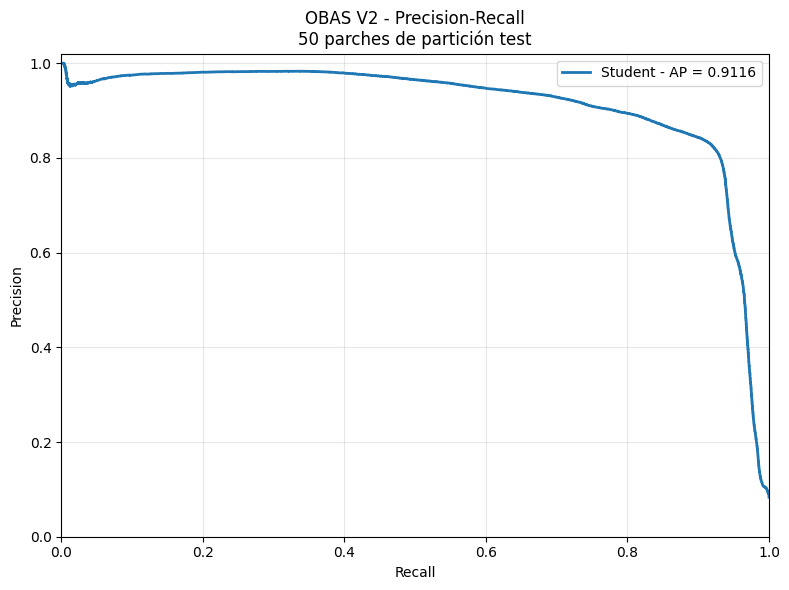


=== AVERAGE PRECISION ===
AP: 0.9116

=== COMPARACIÓN DE UMBRALES ===


,umbral,precision,recall,f1,TP,FP,FN
0,0.3,0.917642,0.732025,0.814391,50162,4502,18363
1,0.4,0.919681,0.726042,0.811469,49752,4345,18773
2,0.5,0.921712,0.720744,0.808933,49389,4195,19136
3,0.6,0.923771,0.714279,0.805629,48946,4039,19579
4,0.7,0.926367,0.705742,0.801143,48361,3844,20164
5,0.8,0.930959,0.691675,0.793674,47397,3515,21128
6,0.9,0.938272,0.651704,0.769163,44658,2938,23867



=== ARCHIVOS GUARDADOS ===
Curva: /kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_curva_precision_recall_50_TEST.png
Umbrales: /kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_comparacion_umbrales_50_TEST.csv

NOTA: No se selecciona un nuevo umbral a partir de estos resultados de test.


In [77]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Reunir máscaras reales y probabilidades
reales = []
probabilidades = []

print("=== CURVA PRECISION-RECALL: 50 TEST ===")

for _, fila in df_50_test.iterrows():

    imagen = np.load(
        fila["Ruta_imagen"]
    ).astype(np.float32)

    mascara = np.load(
        fila["Ruta_mascara"]
    )

    if imagen.shape == (3, 128, 128):
        imagen = np.transpose(
            imagen, (1, 2, 0)
        )

    real = (mascara > 0).astype(np.uint8)

    pred_prob = modelo_student(
        imagen[np.newaxis, ...],
        training=False
    ).numpy()[0, :, :, 0]

    reales.append(real.ravel())
    probabilidades.append(pred_prob.ravel())

y_true = np.concatenate(reales)
y_score = np.concatenate(probabilidades)

assert len(y_true) == 50 * 128 * 128
assert np.isfinite(y_score).all()

# Curva PR
precision_pr, recall_pr, umbrales_pr = (
    precision_recall_curve(
        y_true,
        y_score
    )
)

ap = average_precision_score(
    y_true,
    y_score
)

# Comparación descriptiva de umbrales
umbrales = [
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9
]

filas_umbrales = []

for umbral in umbrales:

    pred = y_score >= umbral

    tp = int(np.sum((y_true == 1) & pred))
    fp = int(np.sum((y_true == 0) & pred))
    fn = int(np.sum((y_true == 1) & (~pred)))

    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0

    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn else 0.0
    )

    filas_umbrales.append({
        "umbral": umbral,
        "precision": p,
        "recall": r,
        "f1": f1,
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

df_umbrales_test = pd.DataFrame(
    filas_umbrales
)

# Figura
plt.figure(figsize=(8, 6))

plt.plot(
    recall_pr,
    precision_pr,
    linewidth=2,
    label=f"Student - AP = {ap:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    "OBAS V2 - Precision-Recall\n"
    "50 parches de partición test"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

ruta_pr = (
    SALIDA_TEST /
    "S15_curva_precision_recall_50_TEST.png"
)

plt.savefig(
    ruta_pr,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Guardar tabla
ruta_umbrales = (
    SALIDA_TEST /
    "S15_comparacion_umbrales_50_TEST.csv"
)

df_umbrales_test.to_csv(
    ruta_umbrales,
    index=False,
    encoding="utf-8-sig"
)

print("\n=== AVERAGE PRECISION ===")
print(f"AP: {ap:.4f}")

print("\n=== COMPARACIÓN DE UMBRALES ===")
display(df_umbrales_test)

print("\n=== ARCHIVOS GUARDADOS ===")
print("Curva:", ruta_pr)
print("Umbrales:", ruta_umbrales)

print(
    "\nNOTA: No se selecciona un nuevo "
    "umbral a partir de estos resultados "
    "de test."
)


### Paso 12.25. Inventario de evidencias de auditoría

Se identifican y verifican los archivos generados
durante la auditoría del modelo Student MobileNetV2–UNet.

Se incluyen las métricas, curvas Precision–Recall,
análisis de errores, pruebas de robustez, resultados
de remuestreo con tres semillas y visualizaciones Grad-CAM.

Se registra la ubicación y disponibilidad de cada
archivo para preparar el informe final de la semana 15.

El inventario no implica que todas las actividades
de la rúbrica estén completamente satisfechas.

In [78]:

from pathlib import Path
import pandas as pd

RAIZ_SALIDA = Path("/kaggle/working")

PALABRAS_CLAVE = {
    "Metricas": [
        "metricas", "confusion", "resumen"
    ],
    "Precision-Recall": [
        "precision_recall", "umbrales", "curva_pr"
    ],
    "Robustez": [
        "robustez", "blur", "oscuridad",
        "occlusion", "background"
    ],
    "Tres semillas": [
        "semillas", "bootstrap", "seeds"
    ],
    "Grad-CAM": [
        "gradcam", "grad_cam"
    ],
    "Errores visuales": [
        "comparacion", "errores", "visuales"
    ],
    "50 parches": [
        "50_test", "50_parches",
        "pruebadataset", "seleccion_50"
    ]
}

EXTENSIONES = {
    ".csv", ".json", ".png",
    ".jpg", ".jpeg", ".pdf"
}

archivos = []

for ruta in RAIZ_SALIDA.rglob("*"):

    if not ruta.is_file():
        continue

    if ruta.suffix.lower() not in EXTENSIONES:
        continue

    nombre = ruta.name.lower()

    categorias = [
        categoria
        for categoria, palabras
        in PALABRAS_CLAVE.items()
        if any(p in nombre for p in palabras)
    ]

    if not categorias:
        continue

    archivos.append({
        "categoria": ", ".join(categorias),
        "archivo": ruta.name,
        "ruta": str(ruta),
        "formato": ruta.suffix.lower(),
        "tamano_kb": round(
            ruta.stat().st_size / 1024, 2
        )
    })

df_inventario = pd.DataFrame(
    archivos,
    columns=[
        "categoria", "archivo",
        "ruta", "formato", "tamano_kb"
    ]
)

print("=== INVENTARIO DE EVIDENCIAS ===")

print(
    "Archivos identificados:",
    len(df_inventario)
)

if not df_inventario.empty:

    df_inventario = df_inventario.sort_values(
        ["categoria", "archivo"]
    ).reset_index(drop=True)

    print("\n=== RESUMEN POR CATEGORÍA ===")

    categorias_resumen = []

    for categoria in PALABRAS_CLAVE:

        cantidad = int(
            df_inventario["categoria"]
            .str.contains(
                categoria,
                regex=False
            ).sum()
        )

        categorias_resumen.append({
            "categoria": categoria,
            "archivos": cantidad
        })

    display(
        pd.DataFrame(categorias_resumen)
    )

    print("\n=== ARCHIVOS IDENTIFICADOS ===")

    display(
        df_inventario[
            ["categoria", "archivo", "tamano_kb"]
        ]
    )

    ruta_inventario = (
        SALIDA_TEST /
        "S15_inventario_evidencias.csv"
    )

    df_inventario.to_csv(
        ruta_inventario,
        index=False,
        encoding="utf-8-sig"
    )

    print("\nInventario guardado en:")
    print(ruta_inventario)

else:

    print(
        "No se encontraron archivos "
        "con los nombres esperados."
    )


=== INVENTARIO DE EVIDENCIAS ===
Archivos identificados: 19

=== RESUMEN POR CATEGORÍA ===


,categoria,archivos
0,Metricas,6
1,Precision-Recall,2
2,Robustez,3
3,Tres semillas,3
4,Grad-CAM,0
5,Errores visuales,5
6,50 parches,9



=== ARCHIVOS IDENTIFICADOS ===


,categoria,archivo,tamano_kb
0,50 parches,S15_PruebaDataset_50_Galviz_Falla_Pena.csv,4.87
1,50 parches,S15_PruebaDataset_50_TEST_Galviz_Falla_Pena.csv,7.08
2,50 parches,seleccion_50_parches.csv,16.52
3,50 parches,seleccion_50_test_espacial.csv,22.44
4,Errores visuales,OBAS_V2_analisis_errores_50.csv,5.89
5,Errores visuales,S15_comparacion_6_casos_TEST.png,464.81
6,"Errores visuales, 50 parches",OBAS_V2_analisis_errores_50_TEST.csv,8.34
7,Metricas,OBAS_V2_matriz_confusion_50.png,63.74
8,Metricas,OBAS_V2_metricas_globales_50.csv,0.22
9,"Metricas, 50 parches",S15_metricas_globales_50_TEST.csv,0.27



Inventario guardado en:
/kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_inventario_evidencias.csv


### Paso 12.26. Recuperación de evidencias Grad-CAM

Se inspeccionan las carpetas y archivos de imagen
generados durante la auditoría.

El objetivo es localizar las visualizaciones de
interpretabilidad correspondientes a los casos
exitosos y los casos de contraste del modelo Student.

Se comprueba si las evidencias están disponibles
con nombres diferentes a los esperados.

No se ejecuta nuevamente Grad-CAM en este paso.

In [79]:

from pathlib import Path
import pandas as pd

RAIZ = Path("/kaggle/working")

EXTENSIONES_IMAGEN = {
    ".png", ".jpg", ".jpeg", ".webp"
}

PALABRAS = [
    "grad",
    "cam",
    "heatmap",
    "saliency",
    "interpret",
    "explain",
    "exito",
    "error",
    "contraste",
    "atribucion"
]

imagenes = []

for ruta in RAIZ.rglob("*"):

    if not ruta.is_file():
        continue

    if ruta.suffix.lower() not in EXTENSIONES_IMAGEN:
        continue

    texto_ruta = str(ruta).lower()

    coincidencias = [
        palabra for palabra in PALABRAS
        if palabra in texto_ruta
    ]

    imagenes.append({
        "archivo": ruta.name,
        "carpeta": str(ruta.parent),
        "coincidencias": ", ".join(coincidencias),
        "tamano_kb": round(
            ruta.stat().st_size / 1024, 2
        )
    })

df_imagenes = pd.DataFrame(imagenes)

print("=== BÚSQUEDA DE EVIDENCIAS GRAD-CAM ===")
print("Total de imágenes:", len(df_imagenes))

if not df_imagenes.empty:

    candidatas = df_imagenes[
        df_imagenes["coincidencias"] != ""
    ].copy()

    print("\nImágenes candidatas:", len(candidatas))

    if not candidatas.empty:
        display(
            candidatas.sort_values(
                ["carpeta", "archivo"]
            ).head(100)
        )
    else:
        print(
            "No se encontraron imágenes "
            "con palabras relacionadas."
        )

    print("\n=== CARPETAS CON IMÁGENES ===")

    resumen_carpetas = (
        df_imagenes.groupby("carpeta")
        .size()
        .reset_index(name="cantidad")
        .sort_values(
            "cantidad",
            ascending=False
        )
    )

    display(resumen_carpetas.head(30))

else:
    print("No se encontraron imágenes.")

print("\n=== ARCHIVOS DE INTERPRETABILIDAD ===")

archivos_interpretabilidad = []

for ruta in RAIZ.rglob("*"):

    if not ruta.is_file():
        continue

    if ruta.suffix.lower() not in {
        ".csv", ".json", ".npz", ".npy"
    }:
        continue

    if any(
        palabra in str(ruta).lower()
        for palabra in [
            "gradcam", "grad_cam",
            "saliency", "interpretabilidad",
            "heatmap"
        ]
    ):
        archivos_interpretabilidad.append(
            str(ruta)
        )

if archivos_interpretabilidad:
    for ruta in archivos_interpretabilidad[:50]:
        print(ruta)
else:
    print(
        "No se encontraron archivos adicionales "
        "de interpretabilidad."
    )


=== BÚSQUEDA DE EVIDENCIAS GRAD-CAM ===
Total de imágenes: 15

Imágenes candidatas: 10


,archivo,carpeta,coincidencias,tamano_kb
10,error_01_OBAS_zone1_001510.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,92.47
9,error_02_OBAS_zone1_003273.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,97.71
6,error_03_OBAS_zone1_002917.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,96.52
7,error_04_OBAS_zone3_001966.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,82.18
11,error_05_OBAS_zone3_000545.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,91.21
13,error_06_OBAS_zone3_003269.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,59.10
5,error_07_CEMS_AOI01_01_000020.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,79.02
14,error_08_OBAS_zone3_001205.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,102.13
8,error_09_OBAS_zone3_000645.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,105.61
12,error_10_OBAS_zone3_001079.png,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,error,88.26



=== CARPETAS CON IMÁGENES ===


,carpeta,cantidad
2,/kaggle/working/OBAS_V2_Auditoria_50/comparaci...,10
0,/kaggle/working,2
1,/kaggle/working/OBAS_V2_Auditoria_50,1
3,/kaggle/working/OBAS_V2_Auditoria_50_TEST,1
4,/kaggle/working/OBAS_V2_Auditoria_50_TEST/comp...,1



=== ARCHIVOS DE INTERPRETABILIDAD ===
No se encontraron archivos adicionales de interpretabilidad.


In [80]:

import tensorflow as tf
import pandas as pd

print("=== INSPECCIÓN DEL MODELO STUDENT ===")

print("Nombre:", modelo_student.name)
print("Entrada:", modelo_student.input_shape)
print("Salida:", modelo_student.output_shape)
print("Número de capas:", len(modelo_student.layers))

print("\n=== ÚLTIMAS 25 CAPAS ===")

filas = []

for indice, capa in enumerate(modelo_student.layers):

    try:
        forma = str(capa.output.shape)
    except Exception:
        forma = "No disponible"

    filas.append({
        "indice": indice,
        "nombre": capa.name,
        "tipo": type(capa).__name__,
        "salida": forma
    })

df_capas = pd.DataFrame(filas)

display(df_capas.tail(25))

print("\n=== CAPAS CONVOLUCIONALES VISIBLES ===")

tipos_conv = (
    tf.keras.layers.Conv2D,
    tf.keras.layers.DepthwiseConv2D,
    tf.keras.layers.SeparableConv2D
)

capas_conv = [
    fila
    for fila, capa in zip(filas, modelo_student.layers)
    if isinstance(capa, tipos_conv)
]

print(
    "Capas convolucionales de nivel superior:",
    len(capas_conv)
)

if capas_conv:
    display(pd.DataFrame(capas_conv).tail(20))
else:
    print(
        "No hay capas convolucionales directamente "
        "visibles. Pueden estar dentro de submodelos."
    )

print("\n=== POSIBLES SUBMODELOS ===")

submodelos = []

for indice, capa in enumerate(modelo_student.layers):

    if isinstance(capa, tf.keras.Model):

        submodelos.append({
            "indice": indice,
            "nombre": capa.name,
            "tipo": type(capa).__name__,
            "capas_internas": len(capa.layers)
        })

if submodelos:
    display(pd.DataFrame(submodelos))
else:
    print("No se encontraron submodelos anidados.")

print("\n=== CAPA DE SALIDA ===")
print("Nombre:", modelo_student.layers[-1].name)
print("Tipo:", type(modelo_student.layers[-1]).__name__)


=== INSPECCIÓN DEL MODELO STUDENT ===
Nombre: Student_MobileNetV2_UNet_V2
Entrada: (None, 128, 128, 3)
Salida: (None, 128, 128, 1)
Número de capas: 29

=== ÚLTIMAS 25 CAPAS ===


,indice,nombre,tipo,salida
4,4,decoder1_conv1,Conv2D,"(None, 8, 8, 256)"
5,5,decoder1_bn1,BatchNormalization,"(None, 8, 8, 256)"
6,6,decoder1_conv2,Conv2D,"(None, 8, 8, 256)"
7,7,decoder1_bn2,BatchNormalization,"(None, 8, 8, 256)"
8,8,decoder2_upsample,UpSampling2D,"(None, 16, 16, 256)"
9,9,decoder2_concat,Concatenate,"(None, 16, 16, 448)"
10,10,decoder2_conv1,Conv2D,"(None, 16, 16, 128)"
11,11,decoder2_bn1,BatchNormalization,"(None, 16, 16, 128)"
12,12,decoder2_conv2,Conv2D,"(None, 16, 16, 128)"
13,13,decoder2_bn2,BatchNormalization,"(None, 16, 16, 128)"



=== CAPAS CONVOLUCIONALES VISIBLES ===
Capas convolucionales de nivel superior: 10


,indice,nombre,tipo,salida
0,4,decoder1_conv1,Conv2D,"(None, 8, 8, 256)"
1,6,decoder1_conv2,Conv2D,"(None, 8, 8, 256)"
2,10,decoder2_conv1,Conv2D,"(None, 16, 16, 128)"
3,12,decoder2_conv2,Conv2D,"(None, 16, 16, 128)"
4,16,decoder3_conv1,Conv2D,"(None, 32, 32, 64)"
5,18,decoder3_conv2,Conv2D,"(None, 32, 32, 64)"
6,22,decoder4_conv1,Conv2D,"(None, 64, 64, 32)"
7,24,decoder4_conv2,Conv2D,"(None, 64, 64, 32)"
8,27,decoder_final_conv,Conv2D,"(None, 128, 128, 16)"
9,28,burned_area_probability,Conv2D,"(None, 128, 128, 1)"



=== POSIBLES SUBMODELOS ===


,indice,nombre,tipo,capas_internas
0,1,MobileNetV2_Encoder,Functional,154



=== CAPA DE SALIDA ===
Nombre: burned_area_probability
Tipo: Conv2D


### Paso 12.28. Prueba inicial de Grad-CAM para segmentación

Se implementa Grad-CAM sobre la capa decoder4_conv2
del modelo Student MobileNetV2–UNet.

La atribución se calcula respecto a las probabilidades
de segmentación en una región positiva predicha.

Se verifica la existencia de gradientes, la forma
del mapa de activación y su correspondencia espacial
con la imagen satelital.

Se utiliza inicialmente un parche con quema detectada
correctamente antes de procesar los demás casos.

Grad-CAM es una explicación aproximada de las
activaciones del modelo, no una validación causal.

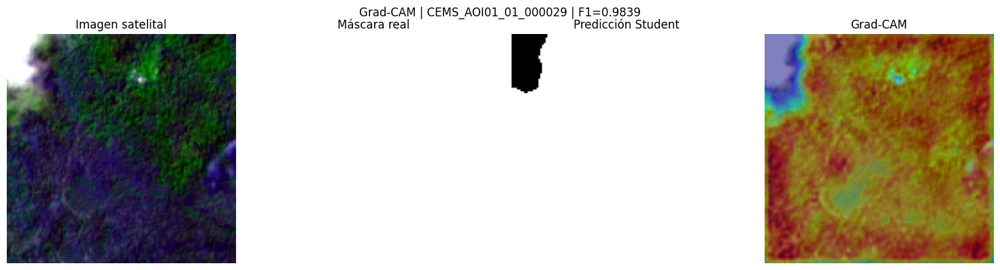

=== VERIFICACIÓN GRAD-CAM ===
Parche: CEMS_AOI01_01_000029.npy
Capa: decoder4_conv2
Forma activaciones: (1, 64, 64, 32)
Forma gradientes: (1, 64, 64, 32)
Gradientes finitos: True
Gradiente máximo absoluto: 2.0667951107025146
Mapa mínimo: 0.0
Mapa máximo: 1.0
Píxeles positivos predichos: 15864
Figura guardada: /kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_gradcam_prueba_inicial.png


In [81]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Capa seleccionada
NOMBRE_CAPA_CAM = "decoder4_conv2"

# Seleccionar un caso positivo bien segmentado
candidatos = df_analisis_test[
    (df_analisis_test["clase_real"] == 1) &
    (df_analisis_test["TP"] > 0)
].sort_values("f1", ascending=False)

assert not candidatos.empty, (
    "No hay casos positivos detectados."
)

caso = candidatos.iloc[0]
nombre_parche = caso["archivo"]
id_parche = nombre_parche.removesuffix(".npy")

registro = df_50_test[
    df_50_test["Parche"] == id_parche
].iloc[0]

imagen = np.load(
    registro["Ruta_imagen"]
).astype(np.float32)

mascara = np.load(
    registro["Ruta_mascara"]
)

if imagen.shape == (3, 128, 128):
    imagen = np.transpose(imagen, (1, 2, 0))

real = (mascara > 0).astype(np.uint8)

# Modelo que devuelve características y predicción
capa_cam = modelo_student.get_layer(
    NOMBRE_CAPA_CAM
)

modelo_cam = tf.keras.Model(
    inputs=modelo_student.inputs,
    outputs=[
        capa_cam.output,
        modelo_student.outputs[0]
    ]
)

entrada = tf.convert_to_tensor(
    imagen[np.newaxis, ...],
    dtype=tf.float32
)

with tf.GradientTape() as tape:

    activaciones, salida = modelo_cam(
        entrada,
        training=False
    )

    # Región positiva definida por la predicción
    region = tf.cast(
        salida >= 0.5,
        tf.float32
    )

    # La región actúa como máscara fija del objetivo
    region = tf.stop_gradient(region)

    objetivo = tf.reduce_sum(
        salida * region
    )

gradientes = tape.gradient(
    objetivo,
    activaciones
)

assert gradientes is not None, (
    "No se pudieron calcular los gradientes."
)

# Pesos por canal
pesos = tf.reduce_mean(
    gradientes,
    axis=(1, 2),
    keepdims=True
)

# Grad-CAM
cam = tf.reduce_sum(
    pesos * activaciones,
    axis=-1
)

cam = tf.nn.relu(cam)

cam = tf.image.resize(
    cam[..., tf.newaxis],
    (128, 128),
    method="bilinear"
)[0, :, :, 0].numpy()

# Normalización
cam = cam - cam.min()

if cam.max() > 0:
    cam = cam / cam.max()

prob = salida.numpy()[0, :, :, 0]
pred = (prob >= 0.5).astype(np.uint8)

# Imagen solo para visualización
visual = imagen.copy()

for canal in range(3):

    valores = visual[:, :, canal]

    minimo = np.percentile(valores, 2)
    maximo = np.percentile(valores, 98)

    visual[:, :, canal] = np.clip(
        (valores - minimo) /
        max(maximo - minimo, 1e-8),
        0, 1
    )

fig, ejes = plt.subplots(
    1, 4,
    figsize=(15, 4)
)

ejes[0].imshow(visual)
ejes[0].set_title("Imagen satelital")

ejes[1].imshow(
    real,
    cmap="gray",
    vmin=0,
    vmax=1
)
ejes[1].set_title("Máscara real")

ejes[2].imshow(
    pred,
    cmap="gray",
    vmin=0,
    vmax=1
)
ejes[2].set_title("Predicción Student")

ejes[3].imshow(visual)
ejes[3].imshow(
    cam,
    cmap="jet",
    alpha=0.5,
    vmin=0,
    vmax=1
)
ejes[3].set_title("Grad-CAM")

for eje in ejes:
    eje.axis("off")

plt.suptitle(
    f"Grad-CAM | {id_parche} | F1={caso['f1']:.4f}",
    fontsize=12
)

plt.tight_layout()

ruta_cam_prueba = (
    SALIDA_TEST /
    "S15_gradcam_prueba_inicial.png"
)

plt.savefig(
    ruta_cam_prueba,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("=== VERIFICACIÓN GRAD-CAM ===")
print("Parche:", nombre_parche)
print("Capa:", NOMBRE_CAPA_CAM)
print("Forma activaciones:", activaciones.shape)
print("Forma gradientes:", gradientes.shape)
print("Gradientes finitos:",
      bool(tf.reduce_all(tf.math.is_finite(gradientes)).numpy()))
print("Gradiente máximo absoluto:",
      float(tf.reduce_max(tf.abs(gradientes)).numpy()))
print("Mapa mínimo:", float(cam.min()))
print("Mapa máximo:", float(cam.max()))
print("Píxeles positivos predichos:", int(pred.sum()))
print("Figura guardada:", ruta_cam_prueba)


### Paso 12.29. Validación espacial de Grad-CAM

Se evalúa Grad-CAM sobre un parche que contiene
una región quemada pequeña y localizada.

Se utiliza la capa decoder4_conv2 y una función
objetivo basada en las probabilidades de los
píxeles predichos como quemados.

Se comparan la imagen original, la máscara real,
la predicción y el mapa de atribución.

El objetivo es verificar si Grad-CAM presenta
una concentración espacial razonable antes
de generar las veinte evidencias finales.

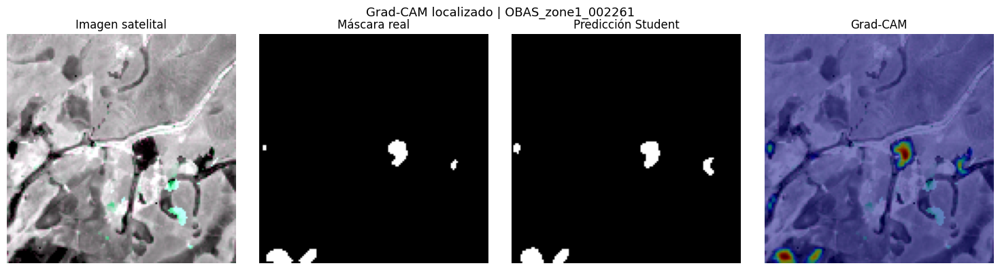

=== VALIDACIÓN ESPACIAL GRAD-CAM ===
Parche: OBAS_zone1_002261
Píxeles quemados reales: 269
Píxeles predichos: 311
Gradientes finitos: True
Máximo Grad-CAM: 1.0
Activación media dentro: 0.4889
Activación media fuera: 0.0017
Figura: /kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_gradcam_validacion_localizada.png


In [82]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

PARCHE_VALIDACION = "OBAS_zone1_002261"

registro = df_50_test[
    df_50_test["Parche"] == PARCHE_VALIDACION
].iloc[0]

imagen = np.load(
    registro["Ruta_imagen"]
).astype(np.float32)

mascara = np.load(
    registro["Ruta_mascara"]
)

if imagen.shape == (3, 128, 128):
    imagen = np.transpose(
        imagen, (1, 2, 0)
    )

real = (mascara > 0).astype(np.uint8)

entrada = tf.convert_to_tensor(
    imagen[np.newaxis, ...],
    dtype=tf.float32
)

# Reutilizar el modelo Grad-CAM del paso anterior
with tf.GradientTape() as tape:

    activaciones, salida = modelo_cam(
        entrada,
        training=False
    )

    region = tf.stop_gradient(
        tf.cast(
            salida >= 0.5,
            tf.float32
        )
    )

    objetivo = tf.reduce_sum(
        salida * region
    )

gradientes = tape.gradient(
    objetivo,
    activaciones
)

assert gradientes is not None

pesos = tf.reduce_mean(
    gradientes,
    axis=(1, 2),
    keepdims=True
)

mapa = tf.reduce_sum(
    pesos * activaciones,
    axis=-1
)

mapa = tf.nn.relu(mapa)

mapa = tf.image.resize(
    mapa[..., tf.newaxis],
    (128, 128)
)[0, :, :, 0].numpy()

mapa -= mapa.min()

if mapa.max() > 0:
    mapa /= mapa.max()

prob = salida.numpy()[0, :, :, 0]
pred = (prob >= 0.5).astype(np.uint8)

# Preparar imagen RGB para visualización
visual = imagen.copy()

for canal in range(3):

    valores = visual[:, :, canal]

    p2 = np.percentile(valores, 2)
    p98 = np.percentile(valores, 98)

    visual[:, :, canal] = np.clip(
        (valores - p2) / max(p98 - p2, 1e-8),
        0,
        1
    )

# Figura comparativa
fig, ejes = plt.subplots(
    1, 4,
    figsize=(15, 4)
)

ejes[0].imshow(visual)
ejes[0].set_title("Imagen satelital")

ejes[1].imshow(
    real,
    cmap="gray",
    vmin=0,
    vmax=1
)
ejes[1].set_title("Máscara real")

ejes[2].imshow(
    pred,
    cmap="gray",
    vmin=0,
    vmax=1
)
ejes[2].set_title("Predicción Student")

ejes[3].imshow(visual)
ejes[3].imshow(
    mapa,
    cmap="jet",
    alpha=0.5,
    vmin=0,
    vmax=1
)
ejes[3].set_title("Grad-CAM")

for eje in ejes:
    eje.axis("off")

plt.suptitle(
    f"Grad-CAM localizado | {PARCHE_VALIDACION}",
    fontsize=13
)

plt.tight_layout()

ruta_validacion = (
    SALIDA_TEST /
    "S15_gradcam_validacion_localizada.png"
)

plt.savefig(
    ruta_validacion,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# Diagnóstico cuantitativo descriptivo
media_dentro = float(
    mapa[pred == 1].mean()
) if pred.any() else float("nan")

media_fuera = float(
    mapa[pred == 0].mean()
) if (~pred.astype(bool)).any() else float("nan")

print("=== VALIDACIÓN ESPACIAL GRAD-CAM ===")
print("Parche:", PARCHE_VALIDACION)
print("Píxeles quemados reales:", int(real.sum()))
print("Píxeles predichos:", int(pred.sum()))
print("Gradientes finitos:",
      bool(tf.reduce_all(tf.math.is_finite(gradientes)).numpy()))
print("Máximo Grad-CAM:", float(mapa.max()))
print("Activación media dentro:", round(media_dentro, 4))
print("Activación media fuera:", round(media_fuera, 4))
print("Figura:", ruta_validacion)


### Paso 12.30. Generación de veinte evidencias Grad-CAM

Se generan veinte visualizaciones de interpretabilidad
del modelo Student MobileNetV2–UNet.

Se seleccionan diez casos positivos con mayor F1
y diez casos de error o contraste con menor F1.

Para las predicciones positivas, la atribución se
calcula sobre la región quemada predicha.

Cuando no existe una predicción positiva, se utiliza
la región quemada de la máscara de referencia como
objetivo diagnóstico, sin atribuir al modelo una
detección que no realizó.

Se guardan las figuras individuales y un índice CSV
con el resultado, tipo de objetivo y archivo generado.

In [83]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path

CARPETA_CAM = SALIDA_TEST / "GradCAM_20_casos"
CARPETA_CAM.mkdir(parents=True, exist_ok=True)

# Solo casos con quema real para comparar
# detecciones buenas frente a errores.
positivos = df_analisis_test[
    df_analisis_test["clase_real"] == 1
].copy()

exitos = positivos.sort_values(
    ["f1", "archivo"],
    ascending=[False, True]
).head(10).copy()

errores = positivos.sort_values(
    ["f1", "archivo"],
    ascending=[True, True]
).head(10).copy()

# Evitar solapamiento entre grupos
assert set(exitos["archivo"]).isdisjoint(
    set(errores["archivo"])
), "Hay casos repetidos entre grupos."

seleccion = []

for grupo, tabla in [
    ("exito", exitos),
    ("error_contraste", errores)
]:
    for _, fila in tabla.iterrows():
        seleccion.append((grupo, fila))

def preparar_visual(imagen):

    visual = imagen.copy()

    for canal in range(3):

        valores = visual[:, :, canal]
        p2 = np.percentile(valores, 2)
        p98 = np.percentile(valores, 98)

        visual[:, :, canal] = np.clip(
            (valores - p2) / max(p98 - p2, 1e-8),
            0, 1
        )

    return visual

registros_cam = []

print("=== GENERACIÓN DE 20 GRAD-CAM ===")

for numero, (grupo, fila) in enumerate(
    seleccion,
    start=1
):

    nombre = fila["archivo"]
    parche = Path(nombre).stem

    registro = df_50_test[
        df_50_test["Parche"] == parche
    ].iloc[0]

    imagen = np.load(
        registro["Ruta_imagen"]
    ).astype(np.float32)

    mascara = np.load(
        registro["Ruta_mascara"]
    )

    if imagen.shape == (3, 128, 128):
        imagen = np.transpose(
            imagen, (1, 2, 0)
        )

    real = (mascara > 0).astype(np.uint8)

    entrada = tf.convert_to_tensor(
        imagen[np.newaxis, ...],
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        activaciones, salida = modelo_cam(
            entrada,
            training=False
        )

        pred = tf.cast(
            salida >= 0.5,
            tf.float32
        )

        hay_prediccion = bool(
            tf.reduce_any(pred > 0).numpy()
        )

        if hay_prediccion:

            region = tf.stop_gradient(pred)
            tipo_objetivo = "region_predicha"

        else:

            region = tf.convert_to_tensor(
                real[np.newaxis, ..., np.newaxis],
                dtype=tf.float32
            )

            tipo_objetivo = (
                "region_real_diagnostica"
            )

        objetivo = tf.reduce_sum(
            salida * region
        )

    gradientes = tape.gradient(
        objetivo,
        activaciones
    )

    if gradientes is None:
        print("Sin gradientes:", parche)
        continue

    pesos = tf.reduce_mean(
        gradientes,
        axis=(1, 2),
        keepdims=True
    )

    cam = tf.reduce_sum(
        pesos * activaciones,
        axis=-1
    )

    cam = tf.nn.relu(cam)

    cam = tf.image.resize(
        cam[..., tf.newaxis],
        (128, 128)
    )[0, :, :, 0].numpy()

    cam -= cam.min()

    if cam.max() > 0:
        cam /= cam.max()

    pred_np = (
        salida.numpy()[0, :, :, 0] >= 0.5
    ).astype(np.uint8)

    visual = preparar_visual(imagen)

    fig, ejes = plt.subplots(
        1, 4,
        figsize=(14, 3.8)
    )

    ejes[0].imshow(visual)
    ejes[0].set_title("Imagen satelital")

    ejes[1].imshow(
        real,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ejes[1].set_title("Máscara real")

    ejes[2].imshow(
        pred_np,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ejes[2].set_title("Predicción Student")

    ejes[3].imshow(visual)
    ejes[3].imshow(
        cam,
        cmap="jet",
        alpha=0.5,
        vmin=0,
        vmax=1
    )
    ejes[3].set_title("Grad-CAM")

    for eje in ejes:
        eje.axis("off")

    plt.suptitle(
        f"{grupo.upper()} | {parche} | "
        f"F1={fila['f1']:.4f}\n"
        f"Objetivo: {tipo_objetivo}",
        fontsize=10
    )

    plt.tight_layout()

    nombre_salida = (
        f"{numero:02d}_{grupo}_{parche}.png"
    )

    ruta_salida = CARPETA_CAM / nombre_salida

    plt.savefig(
        ruta_salida,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)

    registros_cam.append({
        "numero": numero,
        "grupo": grupo,
        "archivo": nombre,
        "zona": fila["zona"],
        "f1": float(fila["f1"]),
        "tipo_objetivo": tipo_objetivo,
        "gradientes_finitos": bool(
            tf.reduce_all(
                tf.math.is_finite(gradientes)
            ).numpy()
        ),
        "cam_maximo": float(cam.max()),
        "ruta_figura": str(ruta_salida)
    })

    print(
        f"{numero:02d}/20 | {grupo} | "
        f"F1={fila['f1']:.4f} | "
        f"{tipo_objetivo}"
    )

df_gradcam_20 = pd.DataFrame(
    registros_cam
)

ruta_indice_cam = (
    CARPETA_CAM /
    "S15_indice_gradcam_20.csv"
)

df_gradcam_20.to_csv(
    ruta_indice_cam,
    index=False,
    encoding="utf-8-sig"
)

print("\n=== RESUMEN GRAD-CAM ===")

print("Figuras generadas:", len(df_gradcam_20))

if not df_gradcam_20.empty:

    display(
        df_gradcam_20[
            [
                "numero",
                "grupo",
                "archivo",
                "f1",
                "tipo_objetivo",
                "gradientes_finitos",
                "cam_maximo"
            ]
        ]
    )

print("\nCarpeta:", CARPETA_CAM)
print("Índice:", ruta_indice_cam)


=== GENERACIÓN DE 20 GRAD-CAM ===
01/20 | exito | F1=0.9839 | region_predicha
02/20 | exito | F1=0.9744 | region_predicha
03/20 | exito | F1=0.9048 | region_predicha
04/20 | exito | F1=0.8918 | region_predicha
05/20 | exito | F1=0.8889 | region_predicha
06/20 | exito | F1=0.8828 | region_predicha
07/20 | exito | F1=0.8718 | region_predicha
08/20 | exito | F1=0.8705 | region_predicha
09/20 | exito | F1=0.8659 | region_predicha
10/20 | exito | F1=0.7361 | region_predicha
11/20 | error_contraste | F1=0.0000 | region_real_diagnostica
12/20 | error_contraste | F1=0.0000 | region_predicha
13/20 | error_contraste | F1=0.0000 | region_real_diagnostica
14/20 | error_contraste | F1=0.0000 | region_real_diagnostica
15/20 | error_contraste | F1=0.0000 | region_real_diagnostica
16/20 | error_contraste | F1=0.0000 | region_real_diagnostica
17/20 | error_contraste | F1=0.3889 | region_predicha
18/20 | error_contraste | F1=0.4444 | region_predicha
19/20 | error_contraste | F1=0.4872 | region_predicha


,numero,grupo,archivo,f1,tipo_objetivo,gradientes_finitos,cam_maximo
0,1,exito,CEMS_AOI01_01_000029.npy,0.983875,region_predicha,True,1.0
1,2,exito,OBAS_zone2_002597.npy,0.974359,region_predicha,True,1.0
2,3,exito,OBAS_zone1_003534.npy,0.904762,region_predicha,True,1.0
3,4,exito,CEMS_AOI01_01_000071.npy,0.891828,region_predicha,True,1.0
4,5,exito,OBAS_zone2_000138.npy,0.888889,region_predicha,True,1.0
5,6,exito,OBAS_zone1_002261.npy,0.882759,region_predicha,True,1.0
6,7,exito,OBAS_zone3_003252.npy,0.871795,region_predicha,True,1.0
7,8,exito,CEMS_AOI01_01_000051.npy,0.870492,region_predicha,True,1.0
8,9,exito,OBAS_zone1_002326.npy,0.865874,region_predicha,True,1.0
9,10,exito,OBAS_zone1_001883.npy,0.736059,region_predicha,True,1.0



Carpeta: /kaggle/working/OBAS_V2_Auditoria_50_TEST/GradCAM_20_casos
Índice: /kaggle/working/OBAS_V2_Auditoria_50_TEST/GradCAM_20_casos/S15_indice_gradcam_20.csv


### Paso 12.31. Control de calidad de las evidencias Grad-CAM

Se verifica la integridad de las veinte figuras
Grad-CAM generadas para la auditoría.

Se comprueba la existencia, apertura y resolución
de cada imagen.

Se crea una lámina de contacto con las diez
visualizaciones exitosas y los diez casos de error.

Esta revisión permite detectar figuras incompletas
o problemas de visualización antes de incorporarlas
al informe final.

=== CONTROL DE CALIDAD GRAD-CAM ===
Esperadas: 20
Encontradas: 20
Válidas: 20


,numero,grupo,archivo,existe,imagen_valida,ancho,alto
0,1,exito,01_exito_CEMS_AOI01_01_000029.png,True,True,2044,566
1,2,exito,02_exito_OBAS_zone2_002597.png,True,True,2044,566
2,3,exito,03_exito_OBAS_zone1_003534.png,True,True,2044,566
3,4,exito,04_exito_CEMS_AOI01_01_000071.png,True,True,2044,566
4,5,exito,05_exito_OBAS_zone2_000138.png,True,True,2044,566
5,6,exito,06_exito_OBAS_zone1_002261.png,True,True,2044,566
6,7,exito,07_exito_OBAS_zone3_003252.png,True,True,2044,566
7,8,exito,08_exito_CEMS_AOI01_01_000051.png,True,True,2044,566
8,9,exito,09_exito_OBAS_zone1_002326.png,True,True,2044,566
9,10,exito,10_exito_OBAS_zone1_001883.png,True,True,2044,566


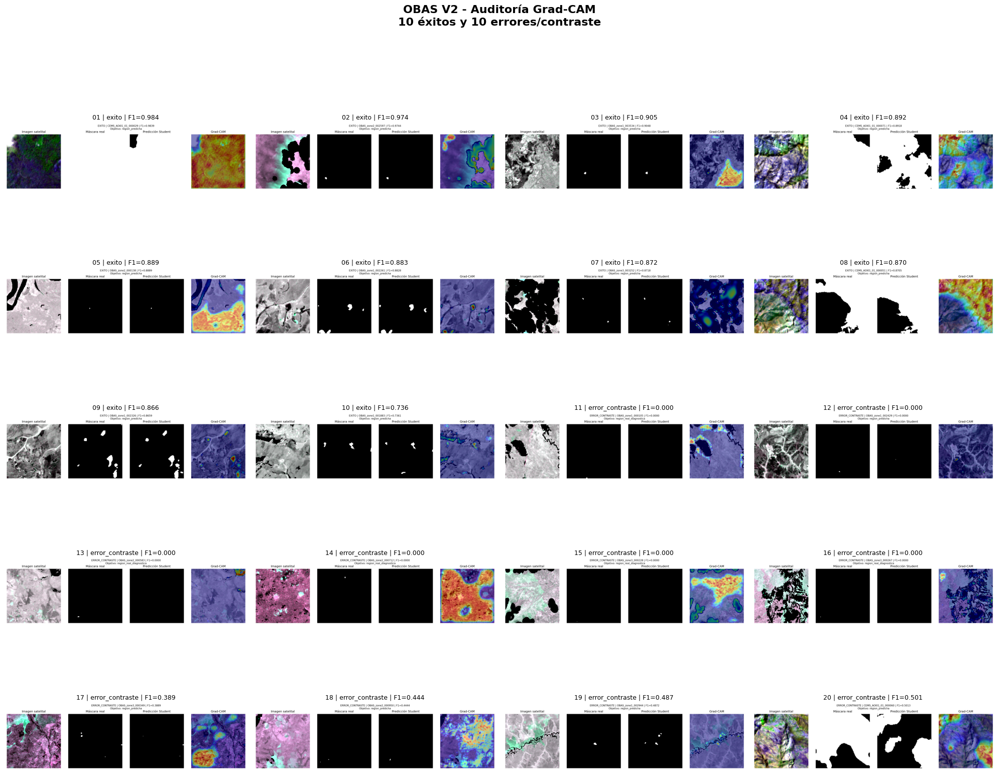


=== ARCHIVOS GENERADOS ===
Lámina: /kaggle/working/OBAS_V2_Auditoria_50_TEST/GradCAM_20_casos/S15_lamina_20_gradcam.png
Control: /kaggle/working/OBAS_V2_Auditoria_50_TEST/GradCAM_20_casos/S15_control_calidad_gradcam.csv

=== RESULTADO FINAL ===
20/20 figuras verificadas correctamente.


In [84]:

from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

CARPETA_CAM = SALIDA_TEST / "GradCAM_20_casos"

verificacion = []

for _, fila in df_gradcam_20.iterrows():

    ruta = Path(fila["ruta_figura"])

    existe = ruta.is_file()
    valida = False
    ancho = None
    alto = None

    if existe:
        try:
            with Image.open(ruta) as img:
                img.verify()

            with Image.open(ruta) as img:
                ancho, alto = img.size

            valida = ancho > 0 and alto > 0

        except Exception as e:
            print("Error en:", ruta.name, e)

    verificacion.append({
        "numero": int(fila["numero"]),
        "grupo": fila["grupo"],
        "archivo": ruta.name,
        "existe": existe,
        "imagen_valida": valida,
        "ancho": ancho,
        "alto": alto
    })

df_verificacion_cam = pd.DataFrame(
    verificacion
)

print("=== CONTROL DE CALIDAD GRAD-CAM ===")

print("Esperadas:", 20)
print("Encontradas:", int(df_verificacion_cam["existe"].sum()))
print("Válidas:", int(df_verificacion_cam["imagen_valida"].sum()))

display(df_verificacion_cam)

# Crear lámina de contacto
fig, ejes = plt.subplots(
    5, 4,
    figsize=(20, 17)
)

ejes = ejes.ravel()

for i, (_, fila) in enumerate(
    df_gradcam_20.iterrows()
):

    ruta = Path(fila["ruta_figura"])

    with Image.open(ruta) as img:
        imagen = img.convert("RGB").copy()

    ejes[i].imshow(imagen)

    ejes[i].set_title(
        f"{int(fila['numero']):02d} | "
        f"{fila['grupo']} | "
        f"F1={fila['f1']:.3f}",
        fontsize=9
    )

    ejes[i].axis("off")

plt.suptitle(
    "OBAS V2 - Auditoría Grad-CAM\n"
    "10 éxitos y 10 errores/contraste",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

ruta_lamina = (
    CARPETA_CAM /
    "S15_lamina_20_gradcam.png"
)

plt.savefig(
    ruta_lamina,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Guardar verificación
ruta_control = (
    CARPETA_CAM /
    "S15_control_calidad_gradcam.csv"
)

df_verificacion_cam.to_csv(
    ruta_control,
    index=False,
    encoding="utf-8-sig"
)

print("\n=== ARCHIVOS GENERADOS ===")
print("Lámina:", ruta_lamina)
print("Control:", ruta_control)

print("\n=== RESULTADO FINAL ===")

if (
    len(df_verificacion_cam) == 20
    and df_verificacion_cam["imagen_valida"].all()
):
    print("20/20 figuras verificadas correctamente.")
else:
    print(
        "Hay figuras pendientes de revisar."
    )


### Paso 12.32. Consolidación y respaldo de evidencias

Se genera un paquete ZIP con los resultados de
la auditoría del modelo Student MobileNetV2–UNet.

El paquete incluye las métricas, pruebas de robustez,
resultados de remuestreo, comparaciones visuales,
curva Precision–Recall y veinte mapas Grad-CAM.

Se conservan los archivos originales y se documenta
su procedencia para facilitar la elaboración del
informe técnico y la entrega de la semana 15.

No se incluyen pesos del modelo ni imágenes de
entrenamiento completas, para mantener el paquete
de evidencias compacto.

In [85]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import pandas as pd

RAIZ = Path("/kaggle/working")

CARPETAS = [
    RAIZ / "OBAS_V2_Auditoria_50",
    RAIZ / "OBAS_V2_Auditoria_50_TEST"
]

EXTENSIONES = {
    ".csv", ".json", ".png",
    ".jpg", ".jpeg"
}

ruta_zip = (
    RAIZ /
    "S15_Evidencias_Auditoria_OBAS_V2.zip"
)

archivos_incluidos = []

with ZipFile(
    ruta_zip,
    "w",
    compression=ZIP_DEFLATED
) as zipf:

    for carpeta in CARPETAS:

        if not carpeta.exists():
            print(
                "Carpeta no encontrada:",
                carpeta
            )
            continue

        for archivo in sorted(
            carpeta.rglob("*")
        ):

            if not archivo.is_file():
                continue

            if archivo.suffix.lower() not in EXTENSIONES:
                continue

            nombre_interno = (
                Path(carpeta.name) /
                archivo.relative_to(carpeta)
            )

            zipf.write(
                archivo,
                arcname=str(nombre_interno)
            )

            archivos_incluidos.append({
                "archivo": archivo.name,
                "carpeta": carpeta.name,
                "tamano_kb": round(
                    archivo.stat().st_size / 1024,
                    2
                )
            })

# Verificar integridad del ZIP
with ZipFile(ruta_zip, "r") as zipf:
    archivo_danado = zipf.testzip()
    total_zip = len(zipf.namelist())

print("=== RESPALDO DE AUDITORÍA ===")

print(
    "Archivos incluidos:",
    len(archivos_incluidos)
)

print(
    "Archivos dentro del ZIP:",
    total_zip
)

print(
    "Integridad:",
    "Correcta" if archivo_danado is None
    else f"Error: {archivo_danado}"
)

print(
    "Tamaño del ZIP (MB):",
    round(
        ruta_zip.stat().st_size / (1024 ** 2),
        2
    )
)

print("\n=== CONTENIDO POR CARPETA ===")

df_respaldo = pd.DataFrame(
    archivos_incluidos
)

if not df_respaldo.empty:
    display(
        df_respaldo.groupby("carpeta")
        .agg(
            archivos=("archivo", "count"),
            tamano_kb=("tamano_kb", "sum")
        )
        .reset_index()
    )

print("\n=== ARCHIVO FINAL ===")
print(ruta_zip)


=== RESPALDO DE AUDITORÍA ===
Archivos incluidos: 50
Archivos dentro del ZIP: 50
Integridad: Correcta
Tamaño del ZIP (MB): 6.87

=== CONTENIDO POR CARPETA ===


,carpeta,archivos,tamano_kb
0,OBAS_V2_Auditoria_50,16,1002.41
1,OBAS_V2_Auditoria_50_TEST,34,6609.20



=== ARCHIVO FINAL ===
/kaggle/working/S15_Evidencias_Auditoria_OBAS_V2.zip


In [86]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import pandas as pd
import numpy as np

CARPETA_PRUEBAS = Path(
    "/kaggle/working/S15_Pruebas_App_50"
)

CARPETA_PRUEBAS.mkdir(
    parents=True,
    exist_ok=True
)

RUTA_ZIP_APP = Path(
    "/kaggle/working/S15_50_Archivos_NPY_Para_App.zip"
)

registros = []

with ZipFile(
    RUTA_ZIP_APP,
    "w",
    ZIP_DEFLATED
) as zipf:

    for numero, (_, fila) in enumerate(
        df_50_test.iterrows(),
        start=1
    ):

        ruta_imagen = Path(
            fila["Ruta_imagen"]
        )

        ruta_mascara = Path(
            fila["Ruta_mascara"]
        )

        assert ruta_imagen.exists()
        assert ruta_mascara.exists()

        # Mantener el archivo NPY original
        zipf.write(
            ruta_imagen,
            arcname=f"imagenes/{ruta_imagen.name}"
        )

        # Máscara real para verificar resultados
        zipf.write(
            ruta_mascara,
            arcname=f"mascaras/{ruta_mascara.name}"
        )

        registros.append({
            "numero": numero,
            "archivo": ruta_imagen.name,
            "zona": fila["source"],
            "clase_real": (
                "quema"
                if bool(fila["has_burn"])
                else "sin_quema"
            ),
            "prediccion_app": "",
            "confianza_app": "",
            "tiempo_respuesta_ms_app": "",
            "observaciones": ""
        })

df_pruebas_app = pd.DataFrame(registros)

ruta_registro = (
    CARPETA_PRUEBAS /
    "S15_Registro_Pruebas_App_50.csv"
)

df_pruebas_app.to_csv(
    ruta_registro,
    index=False,
    encoding="utf-8-sig"
)

with ZipFile(RUTA_ZIP_APP) as zipf:
    error_zip = zipf.testzip()
    archivos_zip = zipf.namelist()

print("=== PREPARACIÓN PARA PRUEBAS EN APP ===")

print("Imágenes NPY:", len(df_pruebas_app))
print(
    "Máscaras:",
    sum(
        nombre.startswith("mascaras/")
        for nombre in archivos_zip
    )
)

print(
    "Archivos en ZIP:",
    len(archivos_zip)
)

print(
    "Integridad:",
    "Correcta"
    if error_zip is None
    else f"Error: {error_zip}"
)

print("\n=== DISTRIBUCIÓN ===")

display(
    df_pruebas_app["clase_real"]
    .value_counts()
    .rename_axis("clase")
    .reset_index(name="cantidad")
)

print("\n=== PRIMEROS ARCHIVOS ===")
display(df_pruebas_app.head(10))

print("\nZIP:", RUTA_ZIP_APP)
print("CSV de registro:", ruta_registro)


=== PREPARACIÓN PARA PRUEBAS EN APP ===
Imágenes NPY: 50
Máscaras: 50
Archivos en ZIP: 100
Integridad: Correcta

=== DISTRIBUCIÓN ===


,clase,cantidad
0,quema,26
1,sin_quema,24



=== PRIMEROS ARCHIVOS ===


,numero,archivo,zona,clase_real,prediccion_app,confianza_app,tiempo_respuesta_ms_app,observaciones
0,1,OBAS_zone1_001883.npy,OBAS_zone1,quema,,,,
1,2,OBAS_zone1_003023.npy,OBAS_zone1,quema,,,,
2,3,OBAS_zone1_002429.npy,OBAS_zone1,quema,,,,
3,4,OBAS_zone1_000105.npy,OBAS_zone1,quema,,,,
4,5,OBAS_zone1_002944.npy,OBAS_zone1,quema,,,,
5,6,OBAS_zone1_003534.npy,OBAS_zone1,quema,,,,
6,7,OBAS_zone1_002261.npy,OBAS_zone1,quema,,,,
7,8,OBAS_zone1_002326.npy,OBAS_zone1,quema,,,,
8,9,OBAS_zone1_000764.npy,OBAS_zone1,sin_quema,,,,
9,10,OBAS_zone1_002502.npy,OBAS_zone1,sin_quema,,,,



ZIP: /kaggle/working/S15_50_Archivos_NPY_Para_App.zip
CSV de registro: /kaggle/working/S15_Pruebas_App_50/S15_Registro_Pruebas_App_50.csv


In [87]:

from IPython.display import FileLink, display
from pathlib import Path

ruta_zip = Path(
    "/kaggle/working/S15_50_Archivos_NPY_Para_App.zip"
)

ruta_csv = Path(
    "/kaggle/working/S15_Pruebas_App_50/"
    "S15_Registro_Pruebas_App_50.csv"
)

assert ruta_zip.is_file(), "No se encontró el ZIP."
assert ruta_csv.is_file(), "No se encontró el CSV."

print("=== DESCARGAS PARA PRUEBAS EN APP ===")

print("\n1. Descargar los 50 archivos NPY:")
display(FileLink(str(ruta_zip)))

print("\n2. Descargar el registro CSV:")
display(FileLink(str(ruta_csv)))

print("\nDescarga ambos archivos antes de continuar.")


=== DESCARGAS PARA PRUEBAS EN APP ===

1. Descargar los 50 archivos NPY:


/kaggle/working/S15_50_Archivos_NPY_Para_App.zip


2. Descargar el registro CSV:


/kaggle/working/S15_Pruebas_App_50/S15_Registro_Pruebas_App_50.csv


Descarga ambos archivos antes de continuar.


### Paso 12.36. Matriz de confusión del modelo Student

Se presenta la matriz de confusión obtenida durante la
evaluación de 50 parches satelitales de la partición test.

La matriz compara las etiquetas reales de los píxeles
con las predicciones del modelo utilizando un umbral de 0.5.

Se identifican verdaderos negativos, falsos positivos,
falsos negativos y verdaderos positivos para analizar
los errores de segmentación.

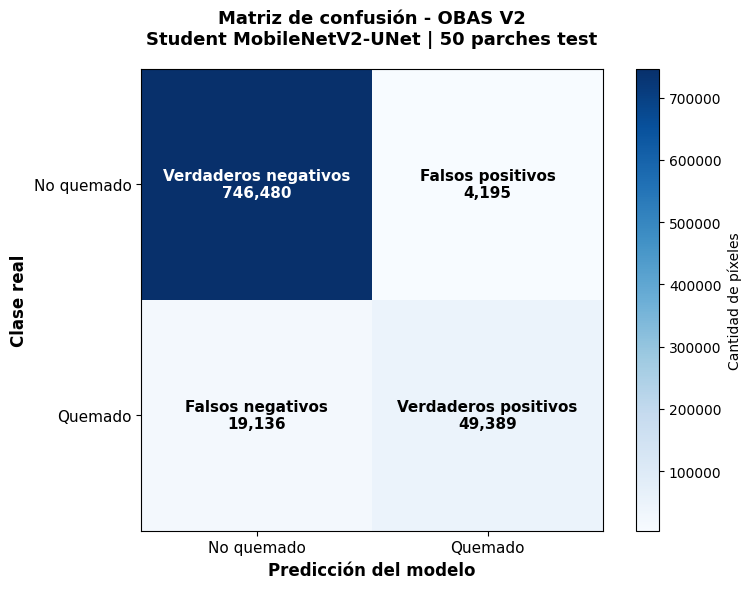

=== MATRIZ DE CONFUSIÓN ===
[[746480   4195]
 [ 19136  49389]]

Imagen guardada en:
/kaggle/working/OBAS_V2_Auditoria_50_TEST/S15_Matriz_Confusion_50_TEST.png

Total de píxeles evaluados: 819200


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Resultados reales obtenidos en la auditoría
# de 50 parches del índice espacial test
TN = 746480
FP = 4195
FN = 19136
TP = 49389

matriz = np.array([
    [TN, FP],
    [FN, TP]
])

clases = ["No quemado", "Quemado"]

fig, ax = plt.subplots(figsize=(8, 6))

imagen = ax.imshow(
    matriz,
    cmap="Blues",
    interpolation="nearest"
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(clases, fontsize=11)
ax.set_yticklabels(clases, fontsize=11)

ax.set_xlabel(
    "Predicción del modelo",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Clase real",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "Matriz de confusión - OBAS V2\n"
    "Student MobileNetV2-UNet | 50 parches test",
    fontsize=13,
    fontweight="bold",
    pad=18
)

nombres = [
    ["Verdaderos negativos", "Falsos positivos"],
    ["Falsos negativos", "Verdaderos positivos"]
]

for i in range(2):
    for j in range(2):
        valor = matriz[i, j]

        ax.text(
            j, i,
            f"{nombres[i][j]}\n{valor:,}",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="white" if valor > matriz.max()/2 else "black"
        )

fig.colorbar(
    imagen,
    ax=ax,
    label="Cantidad de píxeles"
)

plt.tight_layout()

salida = Path(
    "/kaggle/working/OBAS_V2_Auditoria_50_TEST"
)
salida.mkdir(parents=True, exist_ok=True)

ruta_imagen = salida / "S15_Matriz_Confusion_50_TEST.png"

plt.savefig(
    ruta_imagen,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("=== MATRIZ DE CONFUSIÓN ===")
print(matriz)

print("\nImagen guardada en:")
print(ruta_imagen)

print("\nTotal de píxeles evaluados:", matriz.sum())
